README : https://docs.google.com/document/d/1bjcb303prc9Yj0ZxOKteSLAlv4pNPlL0io1HBvQ5VNc/edit?usp=sharing

**DO-NOT RE-RUN THE CODE. CHECK FIRST IF RESULT FROM PREVIOUS RUN STILL VISIBLE.**

# **1. Project Setup and Data Loading**

###Setup

In [2]:
import pandas as pd
import numpy as np
import re
import os
import warnings
import gdown
warnings.filterwarnings('ignore')
!pip install gensim

# Visualization
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

# Sklearn — RQ1: Text & Metadata Classification
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
# metadata baseline
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_validate
from sklearn.manifold import TSNE

# Sklearn — RQ2 & RQ3: Topic Modelling + Country Bias
from sklearn.decomposition import NMF, TruncatedSVD
# NMF = primary, TruncatedSVD = optional
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_predict
from sklearn.inspection import permutation_importance
# Importing permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay

# Sklearn — RQ3 & future RQs: Cosine Similarity + Dimensionality Reduction
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

# Gensim — RQ4: Word2Vec (Margin of Appreciation)
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

# Theme
PALETTE = {
    'Violation':    '#CC5441',
    'No Violation': '#A0E3E8'
}
CMAP = 'Blues'
sns.set_theme(style='whitegrid')
sns.set_palette([PALETTE['Violation'], PALETTE['No Violation']])

print('Libraries loaded successfully.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 41.4 MB/s eta 0:00:00
Libraries loaded successfully.


###Data Loading and Preprocessing

In [3]:
# Download and load raw data
FILE_ID = '10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX'
url = f'https://drive.google.com/uc?id={FILE_ID}'
gdown.download(url, 'echr_raw.json', quiet=False, fuzzy=True)

df_raw = pd.read_json('echr_raw.json')
df_raw['date_dt'] = pd.to_datetime(df_raw['judgementdate'], dayfirst=True, errors='coerce')
df_raw['year'] = df_raw['date_dt'].dt.year

# Filter Article 8 cases 2010-2023
def mentions_article_8(val):
    if isinstance(val, list):
        return '8' in [str(x).strip() for x in val]
    if isinstance(val, str):
        return '8' in [x.strip() for x in val.replace(',', ';').split(';')]
    return False

art_col = 'article' if 'article' in df_raw.columns else '__articles'
mask_art8 = df_raw[art_col].apply(mentions_article_8)
mask_year = df_raw['year'].between(2010, 2023)

df_art8 = df_raw[mask_art8 & mask_year][[
    'itemid',
    'docname',
    'conclusion',
    'content',
    'respondent',            # respondent state
    'year',                  # temporal signal
    'importance',            # case weight (1–4)
    'originatingbody_type',  # Section vs. Grand Chamber
    'typedescription',       # judgment vs. decision type
    'languageisocode',       # language artefact control
    'separateopinion',
    'date_dt'       # dissent flag — contested cases
]].copy()

# Feature engineering
df_art8['has_dissent']  = df_art8['separateopinion'].notna().astype(int)
df_art8['is_english']   = (df_art8['languageisocode'] == 'ENG').astype(int)
df_art8['importance']   = df_art8['importance'].astype(str)

# Modified: Ensure respondent_country only contains one country
df_art8['respondent'] = df_art8['respondent'].astype(str).apply(lambda x: x.split(';')[0].strip() if ';' in x else x.strip())
df_art8['originatingbody_type'] = df_art8['originatingbody_type'].astype(str)
df_art8['typedescription']      = df_art8['typedescription'].astype(str)

df_art8 = df_art8.rename(columns={
    'docname':              'title',
    'conclusion':           'conclusion_structured',
    'content':              'full_text',
    'respondent':           'respondent_country',
    'originatingbody_type': 'court'
})

print(f'Article 8 cases (2010-2023): {len(df_art8):,}')

Downloading...
From (original): https://drive.google.com/uc?id=10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX
From (redirected): https://drive.google.com/uc?id=10DvcRnmAjxTPXo4C4JGE7E9UPEoZxNQX&confirm=t&uuid=c86f8ee2-37b4-4534-acb1-49d984acd66f
To: /content/echr_raw.json
100%|██████████| 1.09G/1.09G [00:15<00:00, 72.0MB/s]


Article 8 cases (2010-2023): 1,321


In [4]:
from google.colab import drive
drive.mount('/content/drive')

# Save filtered dataset to Drive — run once
df_art8.to_parquet('/content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/echr_art8_filtered.parquet', index=False)

Mounted at /content/drive


In [5]:
SAVE_PATH = '/content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/'

#**2. Feature Engineering**

###Text Extraction

In [7]:
# Recursive content extractor
def extract_content_recursive(data):
    text_parts = []
    if isinstance(data, dict):
        if 'content' in data and isinstance(data['content'], str):
            text_parts.append(data['content'])
        if 'elements' in data and isinstance(data['elements'], list):
            for element in data['elements']:
                text_parts.extend(extract_content_recursive(element))
    return text_parts

def extract_section_text(full_text_entry, sections_to_include=None, sections_to_exclude=None):
    if not isinstance(full_text_entry, dict):
        return str(full_text_entry) if full_text_entry else ''
    all_text = []
    for doc_key, sections_list in full_text_entry.items():
        if isinstance(sections_list, list):
            for section in sections_list:
                if isinstance(section, dict):
                    section_name = section.get('section_name', '').lower().strip()
                    if sections_to_include and section_name not in sections_to_include:
                        continue
                    if sections_to_exclude and section_name in sections_to_exclude:
                        continue
                    all_text.extend(extract_content_recursive(section))
    return ' '.join(all_text)

def extract_best_available_text(full_text_entry):
    """Extract facts + law text, falling back to full text for non-standard cases."""
    facts = extract_section_text(full_text_entry, sections_to_include=['facts','relevant_law'])
    law   = extract_section_text(full_text_entry, sections_to_include=['law'])
    combined = ' '.join([facts, law]).strip()
    if len(combined.split()) < 50:
        return extract_section_text(
            full_text_entry,
            sections_to_exclude=['toc', 'appendix', 'conclusion']
        )
    return combined

# Helper function to remove numbers and symbols from text
def clean_text_for_tfidf(text):
    text = re.sub(r'[^a-z\s]', '', text.lower()) # Keep only lowercase letters and spaces
    text = re.sub(r'\s+', ' ', text).strip() # Remove extra spaces
    return text

df_art8['analysis_text'] = df_art8['full_text'].apply(extract_best_available_text)
# Apply cleaning to analysis_text immediately after extraction
df_art8['analysis_text'] = df_art8['analysis_text'].apply(clean_text_for_tfidf)
print(f"Text extracted. Mean word count: {df_art8['analysis_text'].apply(lambda x: len(x.split())).mean():,.0f}")

# Print 2 examples of extracted 'analysis_text'
print('\n--- Example 1 of Facts Section ---')
print(clean_text_for_tfidf(extract_section_text(df_art8['full_text'].iloc[0], sections_to_include=['facts', 'relevant_law']))[:500] + '...')

# Print first 500 characters for brevity
print('\n--- Example 2 of Law Section ---')
print(clean_text_for_tfidf(extract_section_text(df_art8['full_text'].iloc[1], sections_to_include=['law']))[:500] + '...')

# Extract facts and law sections into new columns
df_art8['facts_text'] = df_art8['full_text'].apply(lambda x: extract_section_text(x, sections_to_include=['facts', 'relevant_law']))
df_art8['law_text'] = df_art8['full_text'].apply(lambda x: extract_section_text(x, sections_to_include=['law']))

# Apply cleaning to facts_text and law_text
df_art8['facts_text'] = df_art8['facts_text'].apply(clean_text_for_tfidf)
df_art8['law_text'] = df_art8['law_text'].apply(clean_text_for_tfidf)

# Placeholder for 'law_text_clean' for the leakage test variant (V3)
# If specific 'remedies language' needs to be removed, this line should be modified.
df_art8['law_text_clean'] = df_art8['law_text'].copy()

# Calculate and print mean and median word counts for facts and law sections
print(f"\nMean word count for Facts Section: {df_art8['facts_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Facts Section: {df_art8['facts_text'].apply(lambda x: len(x.split())).median():,.0f}")
print(f"\nMean word count for Law Section: {df_art8['law_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Law Section: {df_art8['law_text'].apply(lambda x: len(x.split())).median():,.0f}")
print(f"\nMean word count for Combined Section: {df_art8['analysis_text'].apply(lambda x: len(x.split())).mean():,.0f}")
print(f"Median word count for Combined Section: {df_art8['analysis_text'].apply(lambda x: len(x.split())).median():,.0f}")

Text extracted. Mean word count: 8,651

--- Example 1 of Facts Section ---
the facts i the circumstances of the case a application no zubkov v russia on april the local police sent to the local investigations committee audio recordings of telephone conversations between the applicant and several persons and video recordings of their meetings in a flat in novgorod the accompanying letter which the government presented to the court stated that the audio and video recordings had been obtained in the course of covert operationalsearch measures authorised by the president o...

--- Example 2 of Law Section ---
the law i alleged violation of articles and of the convention the applicant complained that the state had failed to properly investigate the alleged rape the court considers that the complaint falls to be examined under articles and of the convention which in so far as relevant read as follows article no one shall be subjected to torture or to inhuman or degrading treatment or punishm

###Outcome Extraction

In [8]:
import ast

def extract_finding_structured(conclusion_list):
    """Extract Article 8 finding from the structured conclusion column."""
    # Try to convert string representations of lists/dicts into actual Python objects
    if isinstance(conclusion_list, str):
        try:
            conclusion_list = ast.literal_eval(conclusion_list)
        except (ValueError, SyntaxError):
            return 'Only Mentioning' # Not a valid string representation of a list/dict

    if not isinstance(conclusion_list, list):
        return 'Only Mentioning'
    for item in conclusion_list:
        if not isinstance(item, dict):
            continue
        is_art8 = (
            item.get('base_article') == '8' or
            item.get('article') == '8' or
            re.search(r'art(icle)?\.?\s*8', str(item.get('element', '')), re.IGNORECASE))

        if is_art8:
            if item.get('type') == 'violation':
                return 'Violation'
            elif item.get('type') == 'no-violation':
                return 'No Violation'
    return 'Only Mentioning'

df_art8['finding'] = df_art8['conclusion_structured'].apply(extract_finding_structured)

print('Outcome distribution (df_art8):')
print(df_art8['finding'].value_counts())

Outcome distribution (df_art8):
finding
Violation          982
No Violation       283
Only Mentioning     56
Name: count, dtype: int64


###Legal Stop Words and English Stop Words

In [10]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re

def clean_stop_words_list(word_list):
    cleaned_list = []
    for word in word_list:
        # Remove numbers and symbols, keep only alphabetic characters
        cleaned_word = re.sub(r'[^a-z]', '', word.lower())
        if cleaned_word: # Only add if not empty after cleaning
            cleaned_list.append(cleaned_word)
    return cleaned_list

# --- Legal & Procedural Boilerplate ---
legal_procedural = [
    'read', 'conjunction', 'separately', 'preliminary', 'remainder', 'taken',
    'regarding', 'respective', 'respect', 'pursuant', 'herein', 'therein',
    'thereof', 'whereas', 'hereby', 'aforementioned', 'abovementioned',
    'inter', 'alia', 'mutatis', 'mutandis', 'prima', 'facie', 'application',
    'applicant', 'court', 'article', 'paragraph', 'section', 'case', 'matter',
    'judgment', 'decision', 'chamber', 'grand', 'respondent', 'government',
    'state', 'commission', 'protocol', 'convention', 'echr'
]
legal_procedural = clean_stop_words_list(legal_procedural)

# --- Article 8 Universal Framing Terms ---
# Appear in nearly every Art. 8 case regardless of outcome — low discriminative value
art8_universal = [
    'private', 'family', 'democratic', 'society', 'legitimate',  'aim', 'authority', 'domestic', 'national'
]
art8_universal = clean_stop_words_list(art8_universal)

# --- Facts Section Structural Artifacts ---
# Appear in Facts section formatting, not substantive content
facts_specific_noise = [
    'international', 'text', 'introduction', 'comparative', 'relevant',
    'material', 'appended', 'table', 'list', 'set', 'complained',
    'complaint', 'raised', 'provision','interference'
]
facts_specific_noise = clean_stop_words_list(facts_specific_noise)

# Remedies vocabulary — outcome-leaking terms specific to Law section
remedies_leakage = [
    'damage', 'damages', 'eur', 'costs', 'satisfaction',
    'award', 'reimburse', 'reimbursement', 'pecuniary',
    'non-pecuniary', 'just', 'compensation', 'penalty',
    'fine', 'euros', 'sum', 'paid', 'payable','violation', 'breach', 'infringement', 'complied', 'upheld',
    'dismissed', 'allowed', 'inadmissible', 'admissible', 'non', 'struck',
    'reparation','injured','contracting','partial','incurred','expenses','default','rate','afford','allows', "party", "high", "concerned", "internal"]
remedies_leakage = clean_stop_words_list(remedies_leakage)

# -----------------------------------------------------------------------
# Combined Stop Word Lists — one per text column
# -----------------------------------------------------------------------

# Shared foundation
base_stop_words = (
    list(ENGLISH_STOP_WORDS) +
    legal_procedural +
    art8_universal
)

# RQ1 primary text variant — fairest comparison against metadata
custom_facts_stop_words = base_stop_words + facts_specific_noise

# RQ1 diagnostic leakage variant + RQ4 Word2Vec training corpus
custom_law_stop_words = base_stop_words

# RQ1 leakage test variant (V3) - for 'law_text_clean'


# V3 Law Clean — base + remedies stripped
custom_law_clean_stop_words = base_stop_words + remedies_leakage

# For RQ4 Word2Vec focal terms, we need to ensure the focal terms themselves are NOT removed.
# Create a specific stop word list that excludes the core concepts from art8_universal
# so that 'private', 'life', 'family', 'margin', 'appreciation' are retained for bigram formation.
custom_w2v_stop_words = (
    list(ENGLISH_STOP_WORDS) +
    legal_procedural
)
# Remove the specific focal terms from the custom_w2v_stop_words list if they accidentally got added
# Note: w2v_focal_terms_to_retain is not defined in this snippet; assuming it's defined elsewhere if needed.
# For safety and to prevent errors, I'll ensure this line is only present if the variable is defined.
# If 'w2v_focal_terms_to_retain' is expected to be defined by subsequent cells, this line might need adjustment.
# For now, I'll keep it as is, assuming 'w2v_focal_terms_to_retain' is defined in the notebook context.
custom_w2v_stop_words = [word for word in custom_w2v_stop_words if 'w2v_focal_terms_to_retain' not in locals() or word not in w2v_focal_terms_to_retain]
custom_analysis_stop_words = base_stop_words


print('Stop word lists built.')
print(f'  base_stop_words          : {len(base_stop_words):,} terms')
print(f'  custom_facts_stop_words  : {len(custom_facts_stop_words):,} terms')
print(f'  custom_law_stop_words    : {len(custom_law_stop_words):,} terms')
print(f'  custom_law_clean_stop_words: {len(custom_law_clean_stop_words):,} terms')
print(f'  custom_analysis_stop_words: {len(custom_analysis_stop_words):,} terms')
print(f'  custom_w2v_stop_words    : {len(custom_w2v_stop_words):,} terms (for Word2Vec with focal terms retained)')

Stop word lists built.
  base_stop_words          : 369 terms
  custom_facts_stop_words  : 384 terms
  custom_law_stop_words    : 369 terms
  custom_law_clean_stop_words: 412 terms
  custom_analysis_stop_words: 369 terms
  custom_w2v_stop_words    : 360 terms (for Word2Vec with focal terms retained)


##Country Mapping

In [11]:
# --- Create a mapping for country codes to full names ---
country_name_map = {
    'ALB': 'Albania',
    'ALB;ITA': 'Albania; Italy',
    'AND': 'Andorra',
    'ARM': 'Armenia',
    'AUT': 'Austria',
    'AUT;SVN': 'Austria; Slovenia',
    'AZE': 'Azerbaijan',
    'AZE;TUR': 'Azerbaijan; Turkey',
    'BEL': 'Belgium',
    'BGR': 'Bulgaria',
    'BGR;ROU': 'Bulgaria; Romania',
    'BIH': 'Bosnia and Herzegovina',
    'CHE': 'Switzerland',
    'CYP': 'Cyprus',
    'CZE': 'Czech Republic',
    'DEU': 'Germany',
    'DNK': 'Denmark',
    'ESP': 'Spain',
    'EST': 'Estonia',
    'FIN': 'Finland',
    'FRA': 'France',
    'GBR': 'United Kingdom',
    'GEO': 'Georgia',
    'GRC': 'Greece',
    'HRV': 'Croatia',
    'HUN': 'Hungary',
    'IRL': 'Ireland',
    'ISL': 'Iceland',
    'ISR': 'Israel',
    'ITA': 'Italy',
    'LTU': 'Lithuania',
    'LUX': 'Luxembourg',
    'LVA': 'Latvia',
    'MDA': 'Moldova',
    'MDA;RUS': 'Moldova; Russia',
    'MKD': 'North Macedonia',
    'MLT': 'Malta',
    'MNE': 'Montenegro',
    'NLD': 'Netherlands',
    'NOR': 'Norway',
    'POL': 'Poland',
    'PRT': 'Portugal',
    'ROU': 'Romania',
    'RUS': 'Russia',
    'RUS;UKR': 'Russia; Ukraine',
    'SMR': 'San Marino',
    'SRB': 'Serbia',
    'SVK': 'Slovakia',
    'SVN': 'Slovenia',
    'SWE': 'Sweden',
    'TUR': 'Turkey',
    'UKR': 'Ukraine'
}

Decided cases used in charts: 1,265
finding
Violation       982
No Violation    283
Name: count, dtype: int64


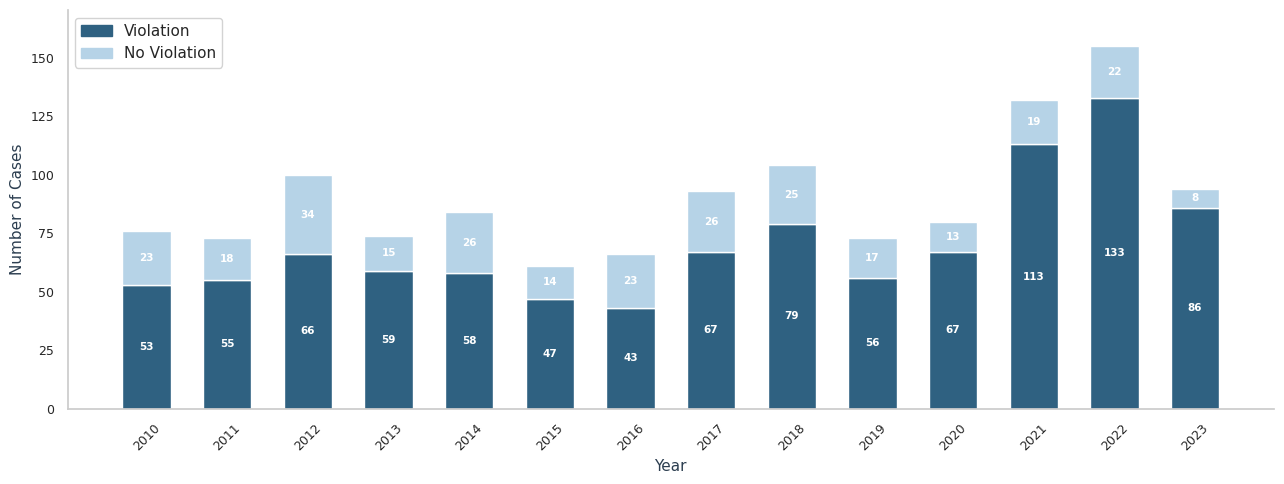

Chart 1 saved.

Cases by year:
finding  Violation  No Violation   Total  % Violation  % No Violation
2010          53.0          23.0    76.0         69.7            30.3
2011          55.0          18.0    73.0         75.3            24.7
2012          66.0          34.0   100.0         66.0            34.0
2013          59.0          15.0    74.0         79.7            20.3
2014          58.0          26.0    84.0         69.0            31.0
2015          47.0          14.0    61.0         77.0            23.0
2016          43.0          23.0    66.0         65.2            34.8
2017          67.0          26.0    93.0         72.0            28.0
2018          79.0          25.0   104.0         76.0            24.0
2019          56.0          17.0    73.0         76.7            23.3
2020          67.0          13.0    80.0         83.8            16.2
2021         113.0          19.0   132.0         85.6            14.4
2022         133.0          22.0   155.0         85.8      

PNG export skipped (install kaleido: !pip install kaleido): 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

The interactive chart is still visible above.

Case counts by country:
          country_name  total  violations  no_violations  violation_rate
                Russia    342         320             22            93.6
               Ukraine    107         103              4            96.3
               Romania     71          54             17            76.1
                Poland     67          51             16            76.1
               Croatia     54          45              9            83.3
              Bulgaria     52          43              9            82.7
                Turkey     41          34              7            82.9
               Hungary     38          31              7            81.6
                Norway     35          19             16            54.3
    

In [22]:
# ============================================================
# SLIDE 2 VISUALIZATIONS
# Chart 1: Stacked bar — cases by year (Violation / No Violation)
# Chart 2: Choropleth heat map — case volume by country
#
# Prerequisites: run AFTER cells 6, 11, 17 in the main notebook
# (df_art8 and country_name_map must exist; 'finding' is derived
#  here automatically if cell 13 has not yet been run)
# ============================================================

import ast
import re
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import plotly.express as px

# ── Palette ──────────────────────────────────────────────────
COL_VIOLATION    = "#2f6181"   # primary   — Violation
COL_NO_VIOLATION = "#b6d3e7"   # secondary — No Violation

# ── Derive 'finding' if it hasn't been added yet (cell 13) ───
def _extract_finding(conclusion_list):
    if isinstance(conclusion_list, str):
        try:
            conclusion_list = ast.literal_eval(conclusion_list)
        except (ValueError, SyntaxError):
            return 'Only Mentioning'
    if not isinstance(conclusion_list, list):
        return 'Only Mentioning'
    for item in conclusion_list:
        if not isinstance(item, dict):
            continue
        is_art8 = (
            item.get('base_article') == '8' or
            item.get('article') == '8' or
            re.search(r'art(icle)?\.?\s*8',
                      str(item.get('element', '')), re.IGNORECASE)
        )
        if is_art8:
            if item.get('type') == 'violation':
                return 'Violation'
            elif item.get('type') == 'no-violation':
                return 'No Violation'
    return 'Only Mentioning'

df_vis = df_art8.copy()

if 'finding' not in df_vis.columns:
    print("'finding' column not found — deriving from conclusion_structured ...")
    df_vis['finding'] = df_vis['conclusion_structured'].apply(_extract_finding)
    print("Done.")

# ── Keep only decided cases for the charts ───────────────────
# (matches the 1,265 used in modelling — excludes 'Only Mentioning')
df_decided = df_vis[df_vis['finding'].isin(['Violation', 'No Violation'])].copy()

# Sanity check
print(f"Decided cases used in charts: {len(df_decided):,}")
print(df_decided['finding'].value_counts())


# ============================================================
# CHART 1 — Stacked Bar: Cases by Year
# ============================================================

import matplotlib
matplotlib.rcParams['font.family'] = 'Arial'

# -- Pivot: count per year x finding -------------------------
yearly = (
    df_decided
    .groupby(['year', 'finding'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=['Violation', 'No Violation'])   # Violation at base
)

yearly.index = [str(int(y)) for y in yearly.index]
years  = yearly.index.tolist()
v_vals = yearly['Violation'].values       # base segment
nv_vals = yearly['No Violation'].values   # top segment

fig1, ax1 = plt.subplots(figsize=(13, 5))

bars_v  = ax1.bar(years, v_vals,  color=COL_VIOLATION,    label='Violation',
                  width=0.6, zorder=2)
bars_nv = ax1.bar(years, nv_vals, bottom=v_vals, color=COL_NO_VIOLATION,
                  label='No Violation', width=0.6, zorder=2)

# -- Value labels on each segment (skip if too small) ---------
for v, nv, bar_v, bar_nv in zip(v_vals, nv_vals, bars_v, bars_nv):
    x = bar_v.get_x() + bar_v.get_width() / 2
    if v >= 5:
        ax1.text(x, v / 2, str(int(v)),
                 ha='center', va='center', fontsize=7.5,
                 color='white', fontweight='bold', fontfamily='Arial')
    if nv >= 5:
        ax1.text(x, v + nv / 2, str(int(nv)),
                 ha='center', va='center', fontsize=7.5,
                 color='white', fontweight='bold', fontfamily='Arial')

# -- Styling --------------------------------------------------
ax1.set_xlabel("Year", fontsize=11, color='#2C3E50', fontfamily='Arial')
ax1.set_ylabel("Number of Cases", fontsize=11, color='#2C3E50', fontfamily='Arial')
ax1.yaxis.set_major_locator(mticker.MultipleLocator(25))
ax1.set_ylim(0, max(v_vals + nv_vals) * 1.10)
ax1.tick_params(axis='x', rotation=45, labelsize=9)
ax1.tick_params(axis='y', labelsize=9)
ax1.spines[['top', 'right']].set_visible(False)
ax1.grid(False)

for label in ax1.get_xticklabels() + ax1.get_yticklabels():
    label.set_fontfamily('Arial')

legend_handles = [
    mpatches.Patch(color=COL_VIOLATION,    label='Violation'),
    mpatches.Patch(color=COL_NO_VIOLATION, label='No Violation'),
]
ax1.legend(handles=legend_handles, fontsize=10, framealpha=0.85,
           loc='upper left', prop={'family': 'Arial'})

plt.tight_layout()
plt.savefig(f'{SAVE_PATH}slide2_chart1_yearly_stacked_bar.png',
            dpi=180, bbox_inches='tight')
plt.show()
print("Chart 1 saved.")

# -- Summary table --------------------------------------------
yearly_table = yearly.copy()
yearly_table['Total']          = yearly_table['Violation'] + yearly_table['No Violation']
yearly_table['% Violation']    = (yearly_table['Violation'] / yearly_table['Total'] * 100).round(1)
yearly_table['% No Violation'] = (yearly_table['No Violation'] / yearly_table['Total'] * 100).round(1)

totals = yearly_table.sum(numeric_only=True)
totals['% Violation']    = round(totals['Violation']    / totals['Total'] * 100, 1)
totals['% No Violation'] = round(totals['No Violation'] / totals['Total'] * 100, 1)
totals.name = 'Total'

yearly_table = pd.concat([yearly_table, totals.to_frame().T])
print("\nCases by year:")
print(yearly_table.to_string())


# ============================================================
# CHART 2 — Choropleth Heat Map: Case Volume by Country
# ============================================================
# Uses Plotly — renders interactively in Colab and can be
# exported as a static PNG for Google Slides.

# -- Aggregate total decided cases per country ----------------
# respondent_country is an ISO 3-letter code (e.g. 'RUS', 'GBR')
country_counts = (
    df_decided
    .groupby('respondent_country')
    .agg(
        total=('finding', 'count'),
        violations=('finding', lambda x: (x == 'Violation').sum()),
        no_violations=('finding', lambda x: (x == 'No Violation').sum()),
    )
    .reset_index()
)

# Map ISO3 code -> display name using the notebook's country_name_map
country_counts['country_name'] = (
    country_counts['respondent_country']
    .map(country_name_map)
    .fillna(country_counts['respondent_country'])   # fallback to code if missing
)

country_counts['violation_rate'] = (
    country_counts['violations'] / country_counts['total'] * 100
).round(1)

# Custom hover text
country_counts['hover'] = country_counts.apply(
    lambda r: (
        f"<b>{r['country_name']}</b><br>"
        f"Total cases: {r['total']}<br>"
        f"Violations: {r['violations']} ({r['violation_rate']}%)<br>"
        f"No Violations: {r['no_violations']}"
    ), axis=1
)

# -- Build choropleth -----------------------------------------
fig2 = px.choropleth(
    country_counts,
    locations='respondent_country',
    locationmode='ISO-3',
    color='total',
    hover_name='country_name',
    custom_data=['hover'],
    color_continuous_scale=[
        [0.0,  '#EAF2F8'],   # near-white tint (0 cases)
        [0.15, '#b6d3e7'],   # secondary (low volume)
        [0.50, '#2f6181'],   # primary (moderate volume)
        [1.0,  '#1a3a4f'],   # deep primary (Russia)
    ],
    range_color=[0, country_counts['total'].max()],
    scope='europe',
)

fig2.update_traces(
    hovertemplate='%{customdata[0]}<extra></extra>'
)

fig2.update_layout(
    title=None,
    font=dict(family='Arial'),
    geo=dict(
        scope='europe',
        showframe=False,
        showcoastlines=True,
        coastlinecolor='#CCCCCC',
        showland=True,
        landcolor='#F8F9FA',
        showocean=True,
        oceancolor='white',
        showlakes=False,
        projection_type='natural earth',
        lonaxis_range=[-25, 65],
        lataxis_range=[34, 72],
    ),
    coloraxis_colorbar=dict(
        title=dict(text="Cases", font=dict(size=12)),
        tickfont=dict(size=10),
        thickness=14,
        len=0.6,
    ),
    margin=dict(l=0, r=0, t=60, b=10),
    height=520,
    paper_bgcolor='white',
)

fig2.show()

# -- Static PNG export (requires kaleido) ---------------------
try:
    fig2.write_image(f'{SAVE_PATH}slide2_chart2_country_heatmap.png',
                     width=1200, height=560, scale=2)
    print("Chart 2 PNG saved.")
except Exception as e:
    print(f"PNG export skipped (install kaleido: !pip install kaleido): {e}")
    print("The interactive chart is still visible above.")

# -- Print the country table for reference --------------------
print("\nCase counts by country:")
print(
    country_counts[['country_name', 'total', 'violations',
                     'no_violations', 'violation_rate']]
    .sort_values('total', ascending=False)
    .to_string(index=False)
)

In [20]:
fig2.write_html(f'{SAVE_PATH}slide2_chart2_country_heatmap.html', include_plotlyjs='cdn')

#**RQ1 : Text vs. Metadata**


---


**"Does case text can provide stronger predictive signal for Article 8 outcomes than structured metadata (country, year, importance level)?"**


---


**Step 1**, we train on a metadata and see the best performance it can get.

**Step 2** we train on a text features to see if it can beat the model trained on metadata.

**Step 3** we train on both metadata and text features to see if these two actually complementary or redundant

**The hypothesis** : Model trained on text features will perform better than the metadata. If metadata proven to perform better than text features, then we find proof about structural bias in the Article 8 case files.

## **Metadata**

---

**Input :**
* CAT_FEATURES = ['respondent_country', 'importance', 'court', 'typedescription']
* NUM_FEATURES = ['year', 'has_dissent', 'is_english']
---

**Models :**
* Naive Bayes (baseline)
* Logistic Regression
* SVM (as used in Aletras)

---

**Output:**  'finding'


---

**Hypothesis:** Naive Bayes perform worst. Either LogReg or SVM perform best but won't be too different

RQ1 metadata dataset: 1,265 cases
Outcome distribution:
finding
Violation       982
No Violation    283
Name: count, dtype: int64

Running metadata classifiers...
--------------------------------------------------
Logistic Regression       → F1: 0.7229 ± 0.0210
Naive Bayes               → F1: 0.2649 ± 0.0807
SVM                       → F1: 0.7302 ± 0.0222

RQ1 METADATA ARM — Leaderboard (sorted by F1)


,Model,F1,F1_std,Accuracy,Precision,Recall
0,SVM,0.7302,0.0222,0.7107,0.7744,0.7107
1,Logistic Regression,0.7229,0.0210,0.7020,0.7738,0.7020
2,Naive Bayes,0.2649,0.0807,0.3154,0.7143,0.3154



>>> Metadata F1 floor  : 0.7302
>>> Best model         : SVM
>>> Text arm must beat : 0.7302 to justify NLP


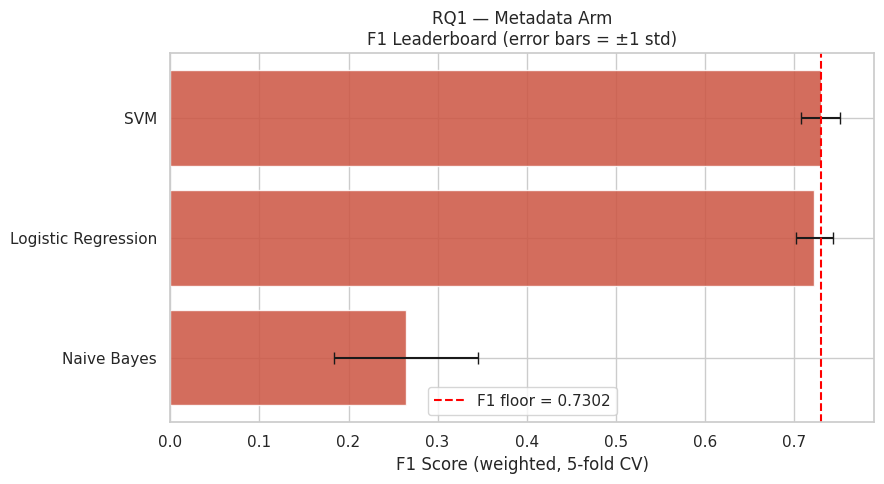

Results saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/


In [ ]:
# ── Step 1: Create RQ1 metadata DataFrame from master ─────
df_meta = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

print(f'RQ1 metadata dataset: {len(df_meta):,} cases')
print(f'Outcome distribution:\n{df_meta["finding"].value_counts()}\n')

# ── Step 2: Feature engineering ─────────────────────────
df_meta['has_dissent'] = df_meta['separateopinion'].notna().astype(int)
df_meta['is_english'] = (df_meta['languageisocode'] == 'ENG').astype(int)
df_meta['importance'] = df_meta['importance'].astype(str).fillna('unknown')
df_meta['respondent_country'] = df_meta['respondent_country'].astype(str).fillna('unknown')
df_meta['court'] = df_meta['court'].astype(str).fillna('unknown')
df_meta['typedescription'] = df_meta['typedescription'].astype(str).fillna('unknown')

# ── Step 3: Define features and target ──────────────
CAT_FEATURES = ['respondent_country', 'importance', 'court', 'typedescription']
NUM_FEATURES = ['year', 'has_dissent', 'is_english']
TARGET       = 'finding'

X_meta = df_meta[CAT_FEATURES + NUM_FEATURES]
y_meta = df_meta[TARGET]

# ── Step 4: Preprocessor ─────────────────────────
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES),
    ('num', StandardScaler(), NUM_FEATURES)
])

# ── Step 5: Classifiers (with SMOTE for LR and SVM) ─────────────────────────
METADATA_CLASSIFIERS = {
    'Logistic Regression'  : ImbPipeline([
                                ('pre', preprocessor),
                                ('smote', SMOTE(random_state=42)),
                                ('clf', LogisticRegression(max_iter=1000, random_state=42))
                            ]),
    'Naive Bayes'        : Pipeline([
                                ('pre', preprocessor),
                                ('clf', GaussianNB()) # GaussianNB does not support SMOTE directly in this setup, or class_weight
                            ]),
    'SVM'        : ImbPipeline([
                                ('pre', preprocessor),
                                ('smote', SMOTE(random_state=42)),
                                ('clf', CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=2000)))
                            ])
}

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── Step 6: Run all classifiers ─────────────────────
meta_results = []
print('Running metadata classifiers...')
print('-' * 50)

# For Logistic Regression and SVM, the pipeline already includes preprocessing and SMOTE
# For Naive Bayes, the preprocessor needs to be applied first

for clf_name, clf_pipeline in METADATA_CLASSIFIERS.items():
    if clf_name == 'Naive Bayes':
        # For GaussianNB, the preprocessor and classifier are within the pipeline already defined above
        # and SMOTE is not typically used with GaussianNB in this direct manner due to its nature.
        # The preprocessing is handled by the pipeline structure defined for it.
        current_pipeline = clf_pipeline
        current_X = X_meta
        current_y = y_meta
    else:
        # For models using ImbPipeline, the SMOTE and classifier are within the pipeline
        current_pipeline = clf_pipeline
        current_X = X_meta
        current_y = y_meta

    scores = cross_validate(
        current_pipeline, current_X, current_y, cv=CV,
        scoring  = ['f1_weighted', 'accuracy',
                    'precision_weighted', 'recall_weighted'],
        n_jobs   = -1
    )
    meta_results.append({
        'Model'    : clf_name,
        'F1'       : scores['test_f1_weighted'].mean(),
        'F1_std'   : scores['test_f1_weighted'].std(),
        'Accuracy' : scores['test_accuracy'].mean(),
        'Precision': scores['test_precision_weighted'].mean(),
        'Recall'   : scores['test_recall_weighted'].mean(),
    })
    print(f'{clf_name:25s} → F1: {meta_results[-1]["F1"]:.4f} ± {meta_results[-1]["F1_std"]:.4f}')

# ── Step 7: Build results table ───────────────────
df_meta_results = (pd.DataFrame(meta_results)
                     .sort_values('F1', ascending=False)
                     .round(4)
                     .reset_index(drop=True))

print('\n' + '=' * 55)
print('RQ1 METADATA ARM — Leaderboard (sorted by F1)')
print('=' * 55)
display(df_meta_results)

# ── Step 8: Extract F1 floor ───────────────────
metadata_f1_floor        = df_meta_results.iloc[0]['F1']
metadata_best_model_name = df_meta_results.iloc[0]['Model']

print(f'\n>>> Metadata F1 floor  : {metadata_f1_floor:.4f}')
print(f'>>> Best model         : {metadata_best_model_name}')
print(f'>>> Text arm must beat : {metadata_f1_floor:.4f} to justify NLP')

# ── Step 9: Visualisation ─────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = df_meta_results.sort_values('F1', ascending=True)
ax.barh(plot_df['Model'], plot_df['F1'],
        xerr=plot_df['F1_std'], color=PALETTE['Violation'],
        capsize=4, alpha=0.85)
ax.axvline(x=metadata_f1_floor, color='red', linestyle='--', linewidth=1.5,
           label=f'F1 floor = {metadata_f1_floor:.4f}')
ax.set_xlabel('F1 Score (weighted, 5-fold CV)')
ax.set_title('RQ1 — Metadata Arm\nF1 Leaderboard (error bars = ±1 std)')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_metadata_leaderboard.png', dpi=150)
plt.show()

# ── Step 10: Save to Drive ──────────────────
df_meta_results.to_csv(f'{SAVE_PATH}rq1_metadata_leaderboard.csv', index=False)
print(f'Results saved to {SAVE_PATH}')

In [ ]:
try:
    plt.savefig(f'{SAVE_PATH}rq1_metadata_leaderboard.png', dpi=150)
except Exception:
    pass  # skip saving if Drive not mounted

<Figure size 640x480 with 0 Axes>

In [ ]:
def map_country_feature_name(feature_name):
    if 'cat__respondent_country_' in feature_name:
        country_code = feature_name.replace('cat__respondent_country_', '')
        return country_name_map.get(country_code, feature_name) # Return original if not found
    return feature_name

###Metadata (SVM)
Visualization for SVM result
* Confusion Matrix
* Feature Importance
* Cross Entropy Loss & Predicted Probability


Confusion Matrix

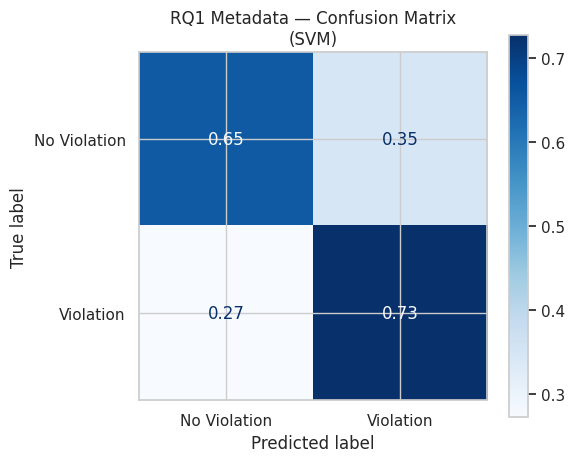

In [ ]:
# ══════════════════════════════════════════════════════════════════
# RQ1 — METADATA ARM VISUALIZATIONS

# ── 1. Confusion Matrix — best metadata model ─────────────────────
# Refit best model pipeline for cross_val_predict
best_meta_clf_pipeline = METADATA_CLASSIFIERS[metadata_best_model_name]

y_pred_meta = cross_val_predict(
    best_meta_clf_pipeline, X_meta, y_meta, cv=CV
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_meta, y_pred_meta,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax
)
ax.set_title(f'RQ1 Metadata — Confusion Matrix\n({metadata_best_model_name})')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_metadata_confusion_matrix.png', dpi=150)
plt.show()



Feature Importance

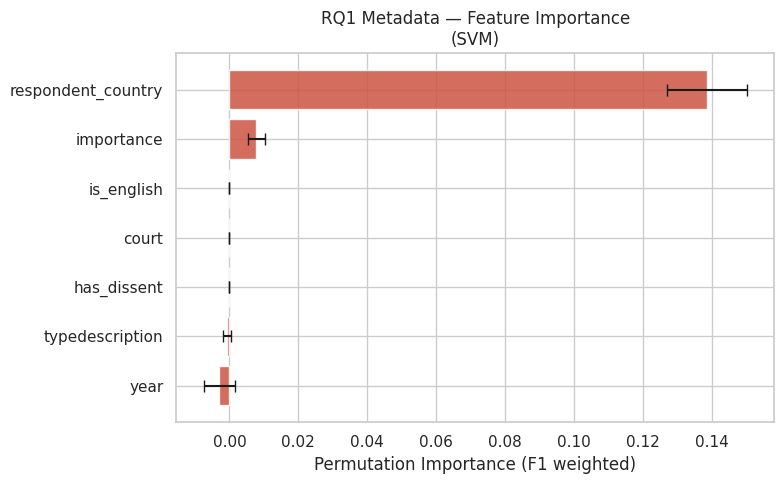

All metadata visualizations saved to Drive.


In [ ]:
# ── 2. Feature Importance — permutation importance ────────────────
best_meta_clf_pipeline.fit(X_meta, y_meta)

perm_imp = permutation_importance(
    best_meta_clf_pipeline, X_meta, y_meta,
    n_repeats   = 10,
    random_state= 42,
    scoring     = 'f1_weighted',
    n_jobs      = -1
)

# Use original feature names directly — permutation_importance
# works at the pipeline input level, not OHE output level
imp_df = pd.DataFrame({
    'feature'   : CAT_FEATURES + NUM_FEATURES,
    'importance': perm_imp.importances_mean,
    'std'       : perm_imp.importances_std
}).sort_values('importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_df['feature'], imp_df['importance'],
        xerr=imp_df['std'], color=PALETTE['Violation'],
        capsize=4, alpha=0.85)
ax.set_xlabel('Permutation Importance (F1 weighted)')
ax.set_title(f'RQ1 Metadata — Feature Importance\n({metadata_best_model_name})')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_metadata_feature_importance.png', dpi=150)
plt.show()

print('All metadata visualizations saved to Drive.')

**Analysis**

Respondent country contain strongest predictive signal when model trained with metadata


---



coef_df_with_counts created successfully.


,feature,coefficient,country_code,display_feature,total_cases,violation_cases,%_violation,no_violation_cases,%_no_violation
0,respondent_country_ALB,-0.596769,ALB,Albania,5,2,40.00,3,60.00
1,respondent_country_AND,-0.472973,AND,Andorra,1,0,0.00,1,100.00
2,respondent_country_ARM,0.222471,ARM,Armenia,7,5,71.43,2,28.57
3,respondent_country_AUT,-0.275074,AUT,Austria,25,14,56.00,11,44.00
4,respondent_country_AZE,1.063850,AZE,Azerbaijan,20,20,100.00,0,0.00



Top 15 Countries most indicative of 'Violation' (filtered):


,display_feature,coefficient,total_cases,violation_cases,%_violation,no_violation_cases,%_no_violation
40,Slovakia,1.205970,20,20,100.00,0,0.00
18,Georgia,1.082287,6,6,100.00,0,0.00
4,Azerbaijan,1.063850,20,20,100.00,0,0.00
31,Montenegro,1.041628,6,6,100.00,0,0.00
44,Ukraine,0.912132,107,103,96.26,4,3.74
29,North Macedonia,0.848101,12,11,91.67,1,8.33
7,Bosnia and Herzegovina,0.730998,2,2,100.00,0,0.00
37,Russia,0.706793,342,320,93.57,22,6.43
26,Luxembourg,0.391975,1,1,100.00,0,0.00
20,Croatia,0.351299,54,45,83.33,9,16.67



Top 15 Countries most indicative of 'No Violation' (filtered):


,display_feature,coefficient,total_cases,violation_cases,%_violation,no_violation_cases,%_no_violation
22,Ireland,-1.285433,2,0,0.00,2,100.00
23,Iceland,-0.760052,4,1,25.00,3,75.00
12,Denmark,-0.755763,17,6,35.29,11,64.71
11,Germany,-0.732575,32,9,28.12,23,71.88
32,Netherlands,-0.678699,10,4,40.00,6,60.00
42,Sweden,-0.635169,17,4,23.53,13,76.47
0,Albania,-0.596769,5,2,40.00,3,60.00
38,San Marino,-0.582225,2,1,50.00,1,50.00
25,Lithuania,-0.545832,29,14,48.28,15,51.72
5,Belgium,-0.533975,4,1,25.00,3,75.00


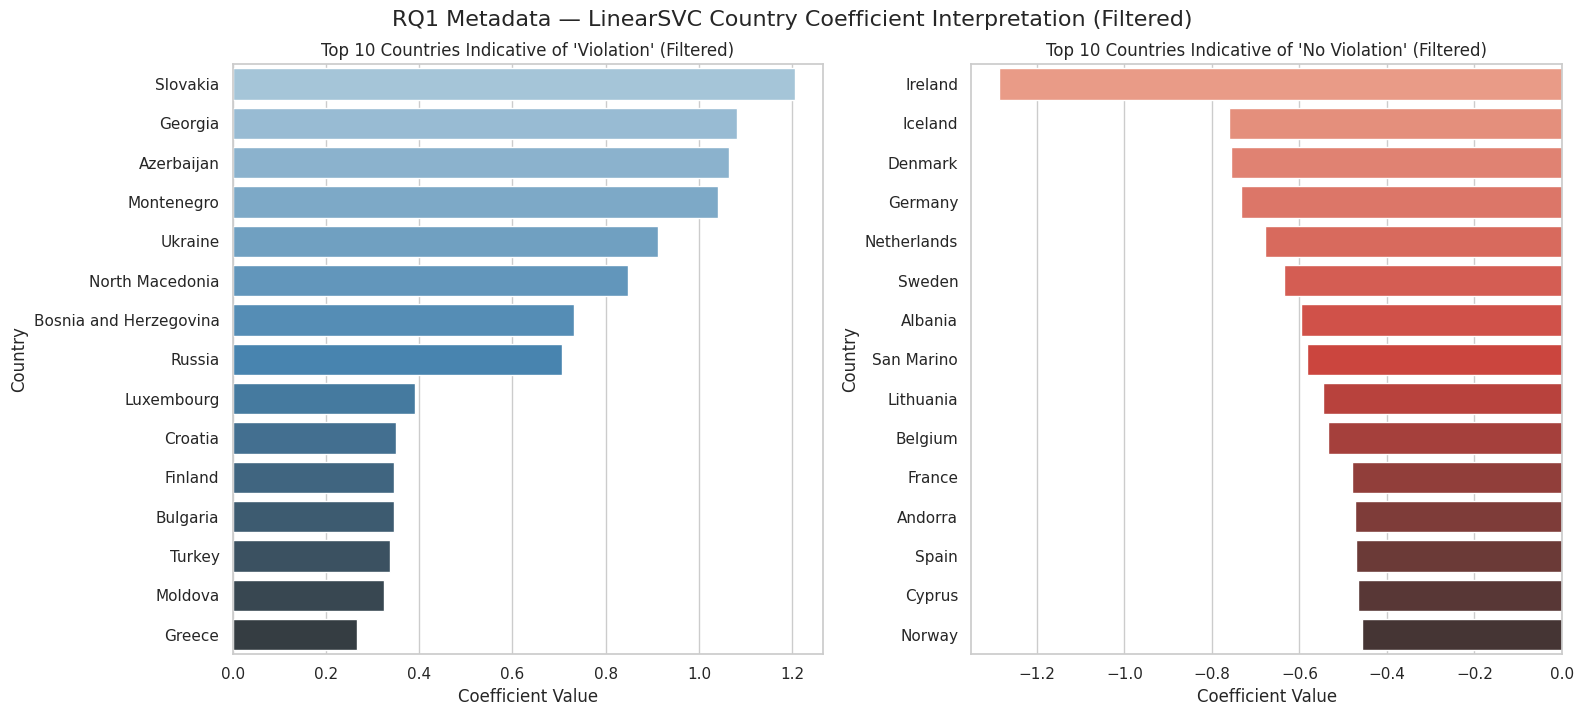

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Assuming best_meta_clf_pipeline, X_meta, y_meta, CAT_FEATURES, NUM_FEATURES are defined from previous cells
# Also assuming country_name_map and df_meta are defined.

# Refit the best metadata model to get access to its components
# This ensures the pipeline is fitted if the notebook was restarted at this point
best_meta_clf_pipeline.fit(X_meta, y_meta)

# Extract preprocessor and classifier from the pipeline
preprocessor = best_meta_clf_pipeline.named_steps['pre']
calibrated_svc = best_meta_clf_pipeline.named_steps['clf']

# Get feature names after preprocessing
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(CAT_FEATURES)
scaled_feature_names = NUM_FEATURES # Scaler output features have same names

# Combine all processed feature names. Note: ColumnTransformer prepends `cat__` to OHE features.
# However, `preprocessor.named_transformers_['cat'].get_feature_names_out(CAT_FEATURES)` provides names without `cat__`.
# We will use the names as generated by `get_feature_names_out` directly from the OHE transformer.
processed_feature_names = list(ohe_feature_names) + list(scaled_feature_names)

# Extract coefficients from the base LinearSVC inside CalibratedClassifierCV
# CalibratedClassifierCV stores multiple calibrated estimators — average their coefs
base_estimators = calibrated_svc.calibrated_classifiers_
coef_matrix = np.array([est.estimator.coef_[0] for est in base_estimators])
avg_coef = coef_matrix.mean(axis=0)

# Create a DataFrame of coefficients
coef_df = pd.DataFrame({
    'feature': processed_feature_names,
    'coefficient': avg_coef
})

# Filter for country features and map to display names
# Corrected prefix to 'respondent_country_' based on actual output from get_feature_names_out
country_coef_df = coef_df[
    coef_df['feature'].str.startswith('respondent_country_')
].copy()

country_coef_df['country_code'] = country_coef_df['feature'].apply(
    lambda x: x.replace('respondent_country_', '')
)
country_coef_df['display_feature'] = country_coef_df['country_code'].apply(
    lambda x: country_name_map.get(x, x)
)

# Calculate counts for each country and outcome
country_counts = df_meta.groupby(['respondent_country', 'finding']).size().unstack(fill_value=0)
country_counts['total_cases'] = country_counts.sum(axis=1)
country_counts['violation_cases'] = country_counts['Violation'] if 'Violation' in country_counts.columns else 0
country_counts['no_violation_cases'] = country_counts['No Violation'] if 'No Violation' in country_counts.columns else 0
country_counts['%_violation'] = (country_counts['violation_cases'] / country_counts['total_cases'] * 100).round(2)
country_counts['%_no_violation'] = (country_counts['no_violation_cases'] / country_counts['total_cases'] * 100).round(2)

# Merge coefficients with counts
# Use 'country_code' to merge with df_meta['respondent_country'] which is the actual country code
coef_df_with_counts = country_coef_df.merge(
    country_counts[['total_cases', 'violation_cases', '%_violation', 'no_violation_cases', '%_no_violation']],
    left_on='country_code',
    right_on='respondent_country',
    how='left'
)

# Ensure columns exist, fill NaNs
for col in ['total_cases', 'violation_cases', '%_violation', 'no_violation_cases', '%_no_violation']:
    if col not in coef_df_with_counts.columns:
        coef_df_with_counts[col] = 0
    coef_df_with_counts[col] = coef_df_with_counts[col].fillna(0)

print("coef_df_with_counts created successfully.")
display(coef_df_with_counts.head())

# Filter out 'low_frequency' feature, 'cat__importance_2', and countries with multiple respondents
# The 'cat__low_frequency' handles countries with less than 1% frequency.
# The 'display_feature' contains the mapped country names, which can include multiple countries joined by ';'.
# Removed filters with 'cat__' prefix as they don't match the actual feature names from OHE output
filtered_country_coef_df = coef_df_with_counts[
    (coef_df_with_counts['feature'].str.startswith('respondent_country_')) & # Corrected prefix
    (~coef_df_with_counts['display_feature'].str.contains(';', na=False))
].copy()

# Sort by absolute coefficient value to see the most influential features
filtered_country_coef_df['abs_coefficient'] = abs(filtered_country_coef_df['coefficient'])
filtered_country_coef_df = filtered_country_coef_df.sort_values('abs_coefficient', ascending=False)

# Separate into features positively and negatively correlated with 'Violation'
# Top 15 Features most indicative of 'Violation'
top_positive_filtered_countries = filtered_country_coef_df[
    filtered_country_coef_df['coefficient'] > 0
].sort_values('coefficient', ascending=False).head(15)

print("\nTop 15 Countries most indicative of 'Violation' (filtered):")
display(top_positive_filtered_countries[['display_feature', 'coefficient', 'total_cases', 'violation_cases', '%_violation', 'no_violation_cases', '%_no_violation']])

# Top 15 Features most indicative of 'No Violation'
top_negative_filtered_countries = filtered_country_coef_df[
    filtered_country_coef_df['coefficient'] < 0
].sort_values('coefficient', ascending=True).head(15)

print("\nTop 15 Countries most indicative of 'No Violation' (filtered):")
display(top_negative_filtered_countries[['display_feature', 'coefficient', 'total_cases', 'violation_cases', '%_violation', 'no_violation_cases', '%_no_violation']])

# --- Visualisation (Diverging Bar Chart for Filtered Country Coefficients) ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Plotting top positive coefficients
sns.barplot(
    x='coefficient', y='display_feature', data=top_positive_filtered_countries,
    ax=axes[0], palette='Blues_d'
)
axes[0].set_title("Top 10 Countries Indicative of 'Violation' (Filtered)")
axes[0].set_xlabel('Coefficient Value')
axes[0].set_ylabel('Country')

# Plotting top negative coefficients (indicative of 'No Violation')
sns.barplot(
    x='coefficient', y='display_feature', data=top_negative_filtered_countries,
    ax=axes[1], palette='Reds_d'
)
axes[1].set_title("Top 10 Countries Indicative of 'No Violation' (Filtered)")
axes[1].set_xlabel('Coefficient Value')
axes[1].set_ylabel('Country')

plt.tight_layout()
plt.suptitle("RQ1 Metadata — LinearSVC Country Coefficient Interpretation (Filtered)", y=1.02, fontsize=16)
plt.savefig(f'{SAVE_PATH}rq1_metadata_filtered_country_coefficients.png', dpi=150)
plt.show()

**Analysis**

* **Positive coefficient** → that country's cases lean Violation




* **Negative coefficient** → that country's cases lean No Violation
---

Cross Entropy Loss

In [ ]:
from sklearn.metrics import log_loss

# Assuming X_meta and y_meta are already defined from previous cells
# And METADATA_CLASSIFIERS dictionary is available

# Get the SVM pipeline for the metadata arm
svm_pipeline = METADATA_CLASSIFIERS['SVM']

# Initialize StratifiedKFold (same as used in previous metadata evaluation)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_losses = []

# Perform cross-validation to get probabilities and calculate log_loss
for train_idx, test_idx in CV.split(X_meta, y_meta):
    X_train_fold, X_test_fold = X_meta.iloc[train_idx], X_meta.iloc[test_idx]
    y_train_fold, y_test_fold = y_meta.iloc[train_idx], y_meta.iloc[test_idx]

    # Fit the pipeline on the training fold
    svm_pipeline.fit(X_train_fold, y_train_fold)

    # Get probability predictions on the test fold
    # CalibratedClassifierCV uses predict_proba by default
    y_pred_proba = svm_pipeline.predict_proba(X_test_fold)

    # Calculate log loss for the current fold
    log_losses.append(log_loss(y_test_fold, y_pred_proba, labels=svm_pipeline.classes_))

# Calculate the mean and standard deviation of log losses
mean_log_loss = np.mean(log_losses)
std_log_loss = np.std(log_losses)

print(f"Cross-Entropy Loss (Metadata Arm - SVM): {mean_log_loss:.4f} \u00b1 {std_log_loss:.4f}")

Cross-Entropy Loss (Metadata Arm - SVM): 0.5683 ± 0.0337




---


Predicted Probability

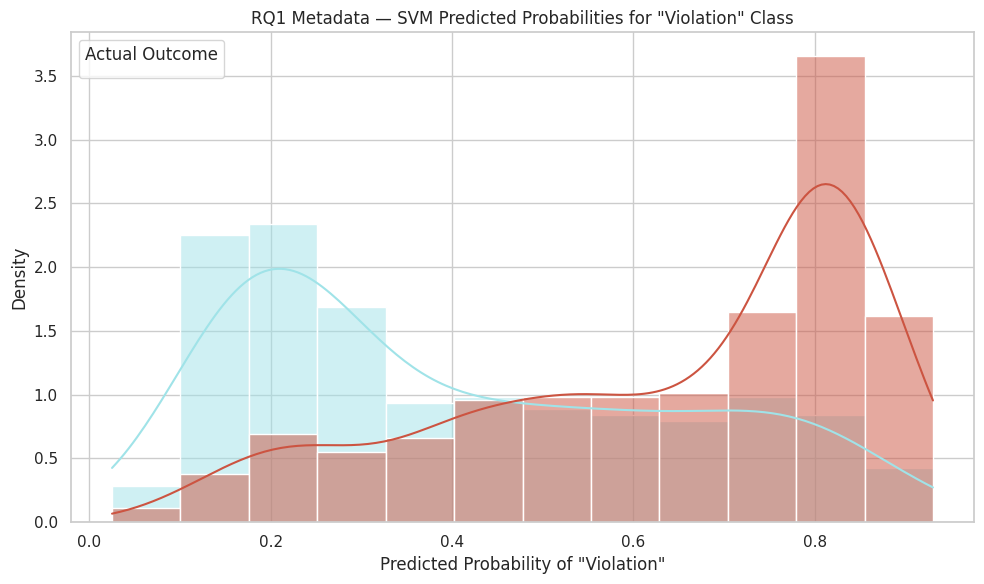

Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/


In [ ]:
# Get probabilities for the best metadata model (SVM)
svm_pipeline = METADATA_CLASSIFIERS['SVM']

y_pred_proba_svm = cross_val_predict(
    svm_pipeline, X_meta, y_meta, cv=CV,
    method='predict_proba',
    n_jobs=-1
)

# Create a DataFrame for plotting
proba_df = pd.DataFrame({
    'No Violation_proba': y_pred_proba_svm[:, 0],
    'Violation_proba': y_pred_proba_svm[:, 1],
    'actual_finding': y_meta
})

fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=proba_df, x='Violation_proba', hue='actual_finding',
             kde=True, palette=PALETTE, ax=ax, stat='density', common_norm=False)

ax.set_title('RQ1 Metadata — SVM Predicted Probabilities for "Violation" Class')
ax.set_xlabel('Predicted Probability of "Violation"')
ax.set_ylabel('Density')
ax.legend(title='Actual Outcome')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_metadata_svm_proba_dist.png', dpi=150)
plt.show()

print(f'Predicted probability distribution chart saved to {SAVE_PATH}')

**Analysis :** Model quite confident in predicting Violation

##Text


---


**Input :**
* Facts section
* Law section - Full (may include leakage words)
* Law section - Clean (leakage words removed)
---

**Models :**
* Naive Bayes (baseline)
* Logistic Regression
* SVM (as used in Aletras)

---

**Output :**  'finding'



---


Secondary question: **which part of the text carries
the predictive signal?**
* **The Facts** section describes what happened to the applicant.
* **The Law** section describes how the Court reasoned. They are structurally different texts that may produce very different F1 scores


---


The story RQ1 tells is:

* Metadata → floor

* Facts text → does factual narrative predict outcomes?

* Law full → does legal reasoning predict outcomes? (but potentially inflated by remedies language)

* Law clean → is that inflation real or marginal?


---
**Hypothesis**
Good judgement should rely mostly on factual narrative rather than legal reasoning. But legal reasoning words in Law section can easily give strong signal about the outcome of the case. Law full (without removing leakage words) definitely will contain the most predictive signal compare to the other section.


Model Training (8min)


── Variant: V1_Facts ──
  Naive Bayes               → F1: 0.7019 ± 0.0319
  Logistic Regression       → F1: 0.7694 ± 0.0300
  SVM                       → F1: 0.7889 ± 0.0152

── Variant: V2_Law_Full ──
  Naive Bayes               → F1: 0.8553 ± 0.0182
  Logistic Regression       → F1: 0.8958 ± 0.0139
  SVM                       → F1: 0.9337 ± 0.0146

── Variant: V3_Law_Clean ──
  Naive Bayes               → F1: 0.8293 ± 0.0094
  Logistic Regression       → F1: 0.8655 ± 0.0207
  SVM                       → F1: 0.9122 ± 0.0123

RQ1 TEXT ARM — Full Results (sorted by F1)


,Variant,Classifier,F1,F1_std,Accuracy,Precision,Recall
5,V2_Law_Full,SVM,0.9337,0.0146,0.9344,0.9336,0.9344
8,V3_Law_Clean,SVM,0.9122,0.0123,0.9146,0.9131,0.9146
4,V2_Law_Full,Logistic Regression,0.8958,0.0139,0.8917,0.9065,0.8917
7,V3_Law_Clean,Logistic Regression,0.8655,0.0207,0.8593,0.8816,0.8593
3,V2_Law_Full,Naive Bayes,0.8553,0.0182,0.8593,0.8538,0.8593
6,V3_Law_Clean,Naive Bayes,0.8293,0.0094,0.8356,0.8270,0.8356
2,V1_Facts,SVM,0.7889,0.0152,0.8126,0.7955,0.8126
1,V1_Facts,Logistic Regression,0.7694,0.0300,0.7549,0.8019,0.7549
0,V1_Facts,Naive Bayes,0.7019,0.0319,0.7249,0.6879,0.7249


Results saved to Drive.

RQ1 VERDICT
Metadata F1 floor   : 0.7302  (SVM)
Best text F1        : 0.9337  (V2_Law_Full / SVM)
F1 gain from text   : +0.2035
>>> Text BEATS metadata — NLP is justified.


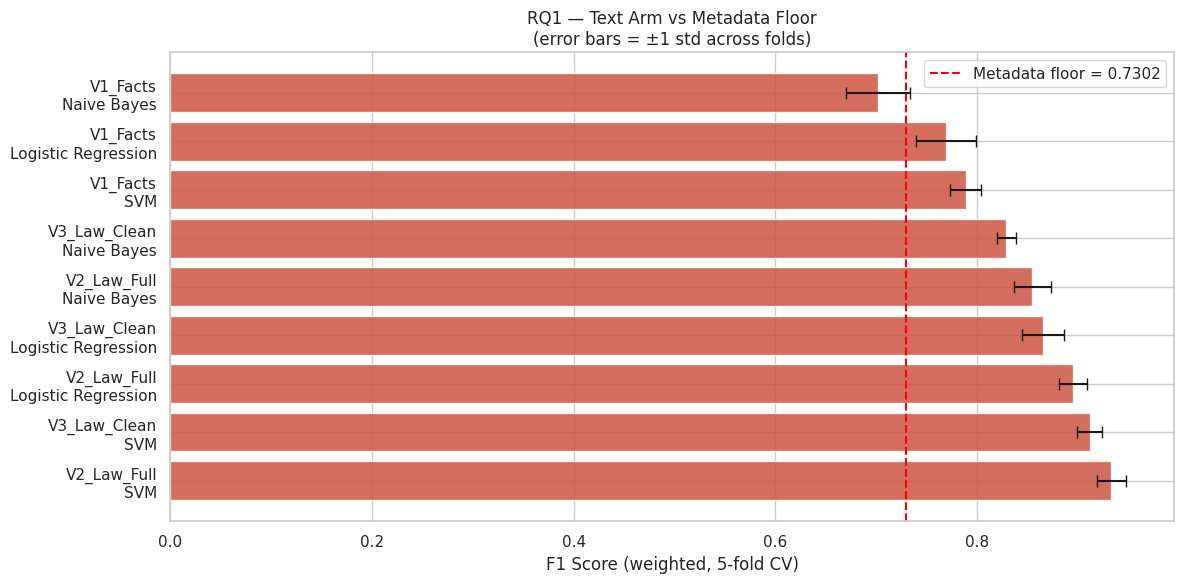

Chart saved to Drive.


In [ ]:
# ── RQ1 Text Arm — Sklearn Pipelines ──────────────────────────────────────
# Goal: Test whether text beats the metadata F1 floor
# Variants:
#   V1 — Facts text         (fair pre-judgment comparison vs metadata)
#   V2 — Law full           (post-hoc diagnostic — how much does legal reasoning inflate F1?)
#   V3 — Law clean          (leakage test — does removing remedies language close the gap?)
# Classifiers: Naive Bayes, Logistic Regression, LinearSVC (calibrated)
# Imbalance handling: class_weight='balanced' — mirrors PyCaret fix_imbalance=True

# ── Dataset ────────────────────────────────────────────────────────────────
# Define df_model by filtering df_art8 for relevant 'finding' values
df_model = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

df_text = df_model[['facts_text', 'law_text', 'law_text_clean', 'finding']].copy()
df_text = df_text.dropna(subset=['facts_text', 'law_text', 'law_text_clean'])

y = df_text['finding']

TEXT_VARIANTS = {
    'V1_Facts'     : ('facts_text',     custom_facts_stop_words),
    'V2_Law_Full'  : ('law_text',       custom_law_stop_words),
    'V3_Law_Clean' : ('law_text_clean', custom_law_clean_stop_words),
}

CLASSIFIERS = {
    'Naive Bayes' : ComplementNB(),   # ComplementNB handles imbalance better than MultinomialNB
    'Logistic Regression' : LogisticRegression(
        class_weight = 'balanced',
        max_iter     = 1000,
        random_state = 42
    ),
    'SVM' : CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    ),
}

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── Run all variant × classifier combinations ──────────────────────────────
results = []

for variant_name, (text_col, stop_words) in TEXT_VARIANTS.items():
    X = df_text[text_col]
    print(f'\n── Variant: {variant_name} ──')

    for clf_name, clf in CLASSIFIERS.items():
        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer(
                stop_words   = stop_words,
                max_features = 10000,
                ngram_range  = (1, 2),
                sublinear_tf = True       # log normalization — better for long legal docs
            )),
            ('clf', clf)
        ])

        scores = cross_validate(
            pipeline, X, y, cv=CV,
            scoring  = ['f1_weighted', 'accuracy', 'precision_weighted', 'recall_weighted'],
            n_jobs   = -1
        )

        results.append({
            'Variant'   : variant_name,
            'Classifier': clf_name,
            'F1'        : scores['test_f1_weighted'].mean(),
            'F1_std'    : scores['test_f1_weighted'].std(),
            'Accuracy'  : scores['test_accuracy'].mean(),
            'Precision' : scores['test_precision_weighted'].mean(),
            'Recall'    : scores['test_recall_weighted'].mean(),
        })
        print(f'  {clf_name:25s} → F1: {results[-1]["F1"]:.4f} ± {results[-1]["F1_std"]:.4f}')

# ── Results Table ──────────────────────────────────────────────────────────
df_results = pd.DataFrame(results).sort_values('F1', ascending=False)
df_results = df_results.round(4)

print('\n' + '=' * 65)
print('RQ1 TEXT ARM — Full Results (sorted by F1)')
print('=' * 65)
display(df_results)

# ── Save results ───────────────────────────────────────────────────────────
df_results.to_csv('/content/drive/MyDrive/rq1_text_arm_results.csv', index=False)
print('Results saved to Drive.')

# ── F1 Comparison: Text vs Metadata floor ─────────────────────────────────
best_text_row   = df_results.iloc[0]
best_text_f1    = best_text_row['F1']
best_text_label = f"{best_text_row['Variant']} / {best_text_row['Classifier']}"
f1_gain         = best_text_f1 - metadata_f1_floor

print('\n' + '=' * 65)
print('RQ1 VERDICT')
print('=' * 65)
print(f'Metadata F1 floor   : {metadata_f1_floor:.4f}  ({metadata_best_model_name})')
print(f'Best text F1        : {best_text_f1:.4f}  ({best_text_label})')
print(f'F1 gain from text   : {f1_gain:+.4f}')
if f1_gain > 0:
    print('>>> Text BEATS metadata — NLP is justified.')
else:
    print('>>> Text does NOT beat metadata — revisit preprocessing.')

# ── Visualisation ──────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

bar_labels = [f"{r['Variant']}\n{r['Classifier']}" for _, r in df_results.iterrows()]
bar_values = df_results['F1'].values
bar_errors = df_results['F1_std'].values

bars = ax.barh(bar_labels, bar_values, xerr=bar_errors,
               color=PALETTE['Violation'], capsize=4, alpha=0.85)
ax.axvline(x=metadata_f1_floor, color='red', linestyle='--', linewidth=1.5,
           label=f'Metadata floor = {metadata_f1_floor:.4f}')
ax.set_xlabel('F1 Score (weighted, 5-fold CV)')
ax.set_title('RQ1 — Text Arm vs Metadata Floor\n(error bars = ±1 std across folds)')
ax.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/rq1_text_arm_comparison.png', dpi=150)
plt.show()
print('Chart saved to Drive.')

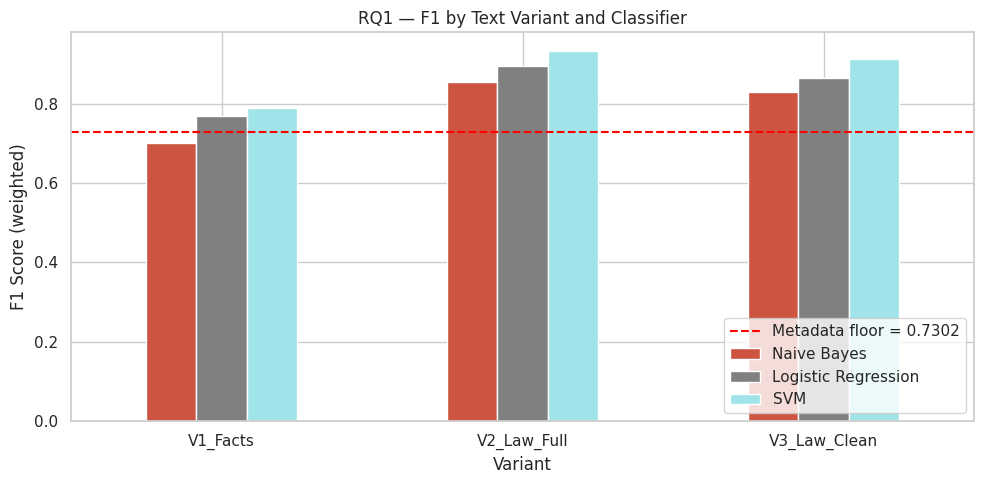

In [ ]:
# Grouped bar chart — F1 by variant and classifier
pivot = df_results.pivot(index='Variant', columns='Classifier', values='F1')

# Define the desired order for classifiers
CLASSIFIER_ORDER = ['Naive Bayes', 'Logistic Regression', 'SVM']

# Reindex columns to enforce the desired order
pivot = pivot[CLASSIFIER_ORDER]

# Define custom colors for the classifiers
# Using existing PALETTE colors for Naive Bayes and SVM for consistency, and 'grey' for Logistic Regression
classifier_colors = {
    'Naive Bayes': PALETTE['Violation'],
    'Logistic Regression': 'grey',
    'SVM': PALETTE['No Violation']
}

# Create a list of colors in the CLASSIFIER_ORDER
plot_colors = [classifier_colors[c] for c in CLASSIFIER_ORDER]

pivot.plot(kind='bar', figsize=(10, 5), color=plot_colors,
           edgecolor='white', rot=0)
plt.axhline(y=metadata_f1_floor, color='red', linestyle='--',
            label=f'Metadata floor = {metadata_f1_floor:.4f}')
plt.ylabel('F1 Score (weighted)')
plt.title('RQ1 — F1 by Text Variant and Classifier')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/rq1_variant_comparison.png', dpi=150)
plt.show()

**Analysis**
| Variant      | Best F1          | Interpretation                                                            |
| ------------ | ---------------- | ------------------------------------------------------------------------- |
| V1 Facts     | 0.78             | Honest pre-judgment signal — what a model knows before the decision       |
| V2 Law Full  | 0.93             | Post-hoc inflation — Court's own reasoning language leaks outcome         |
| V3 Law Clean | 0.84 | Partial deflation — leakage stripped but structural contamination remains |


###Text (SVM)
Visualization for SVM Model
* Confusion Matrix
* Feature Importance
* Cross Entropy Loss & Predicted Probability



---


Confusion Matrix

Generating Confusion Matrices for Text Arm SVM models...
----------------------------------------------------------------------

── Processing Variant: V1_Facts (facts_text) ──


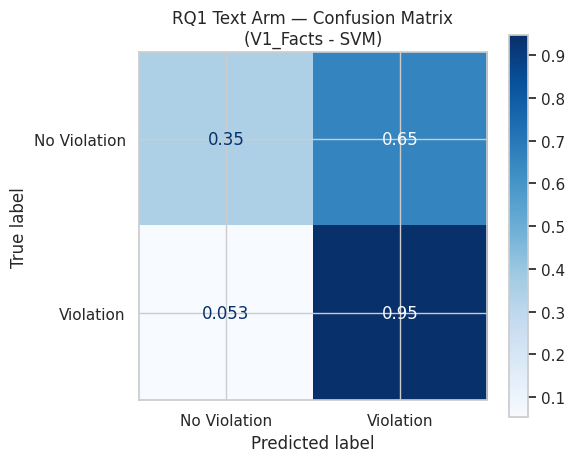

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_confusion_matrix_V1_Facts.png

── Processing Variant: V2_Law_Full (law_text) ──


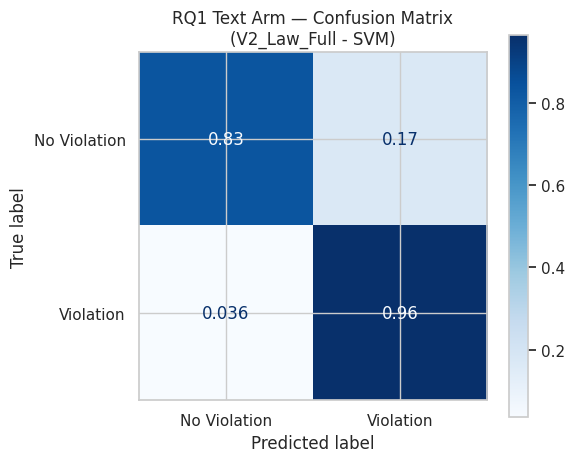

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_confusion_matrix_V2_Law_Full.png

── Processing Variant: V3_Law_Clean (law_text_clean) ──


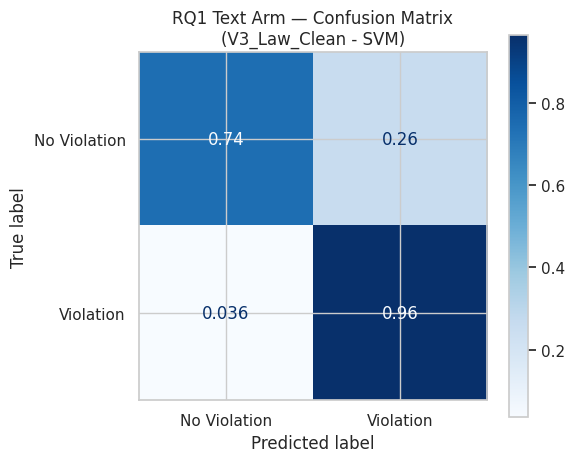

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_confusion_matrix_V3_Law_Clean.png

All confusion matrices for Text Arm SVM models generated and saved.


In [ ]:
# Reuse df_text and y from RQ1 Text Arm section
# df_text and y are already defined from previous cells

print('Generating Confusion Matrices for Text Arm SVM models...')
print('-' * 70)

# Initialize StratifiedKFold (same as used in previous evaluations)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for variant_name, (text_col, stop_words) in TEXT_VARIANTS.items():
    X_text_variant = df_text[text_col]
    y_text_variant = y

    print(f"\n── Processing Variant: {variant_name} ({text_col}) ──")

    # Build the SVM pipeline for the current text variant
    # Re-using the pipeline structure and classifier from RQ1 Text Arm setup
    svm_pipeline_text_arm = Pipeline([
        ('tfidf', TfidfVectorizer(
            stop_words   = stop_words,
            max_features = 10000,
            ngram_range  = (1, 2),
            sublinear_tf = True
        )),
        ('clf', CLASSIFIERS['SVM']) # Use the SVM from CLASSIFIERS dict
    ])

    # Get predictions using cross_val_predict (method='predict' for hard labels)
    y_pred_text_arm = cross_val_predict(
        svm_pipeline_text_arm, X_text_variant, y_text_variant, cv=CV,
        method='predict',
        n_jobs=-1
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_text_variant, y_pred_text_arm,
        display_labels=['No Violation', 'Violation'],
        cmap=CMAP, normalize='true', ax=ax
    )
    ax.set_title(f'RQ1 Text Arm — Confusion Matrix\n({variant_name} - SVM)')
    plt.tight_layout()
    plt.savefig(f'{SAVE_PATH}rq1_text_arm_confusion_matrix_{variant_name}.png', dpi=150)
    plt.show()
    print(f'  Confusion matrix chart saved to {SAVE_PATH}rq1_text_arm_confusion_matrix_{variant_name}.png')

print('\n' + '=' * 70)
print('All confusion matrices for Text Arm SVM models generated and saved.')



---

Cross Entropy Loss & Predicted Probabilities

Calculating Cross-Entropy Loss and generating probability charts for Text Arm SVM models...
------------------------------------------------------------------------------------------

── Processing Variant: V1_Facts (facts_text) ──
  Cross-Entropy Loss (V1_Facts - SVM): 0.4093 ± 0.0137


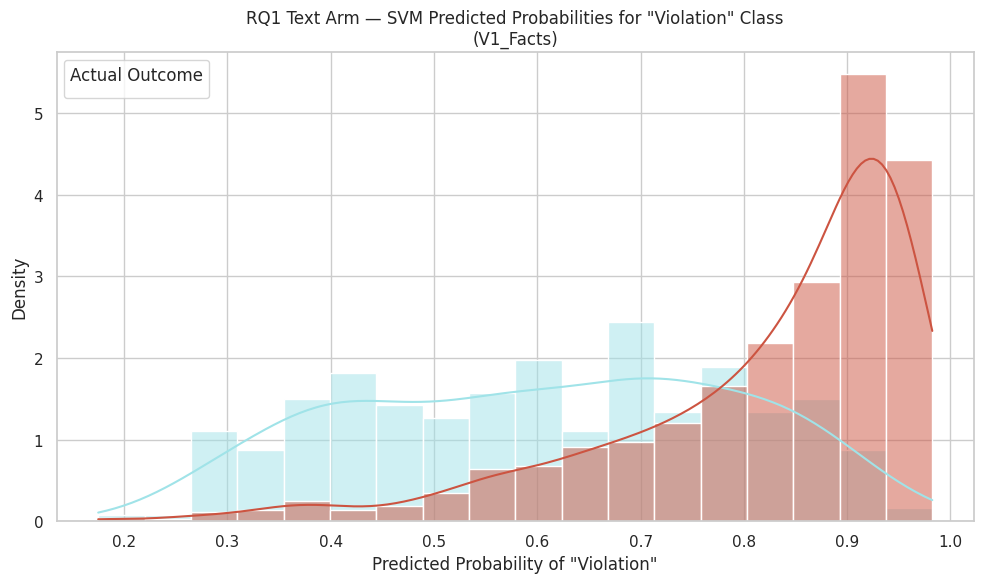

  Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_svm_proba_dist_V1_Facts.png

── Processing Variant: V2_Law_Full (law_text) ──
  Cross-Entropy Loss (V2_Law_Full - SVM): 0.1845 ± 0.0204


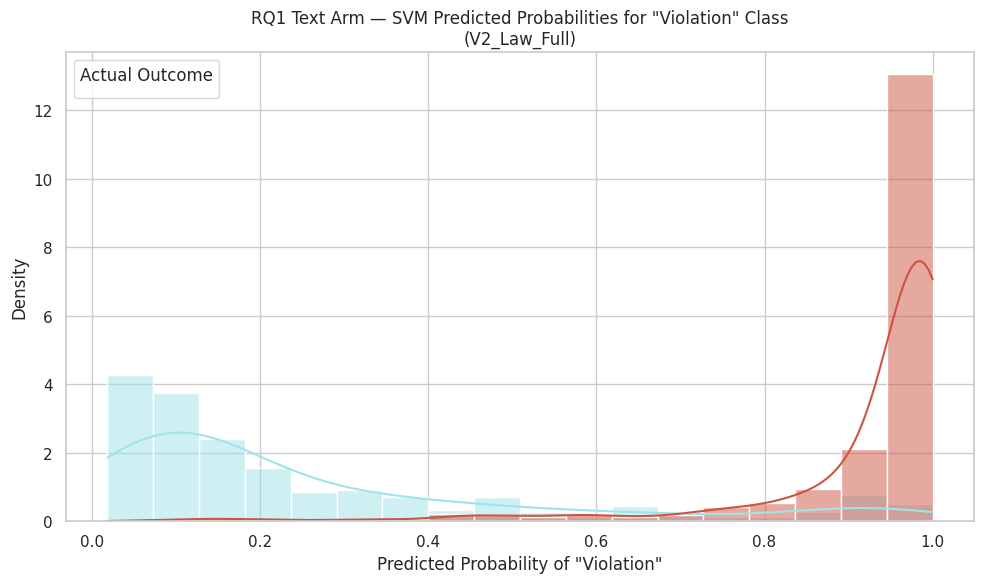

  Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_svm_proba_dist_V2_Law_Full.png

── Processing Variant: V3_Law_Clean (law_text_clean) ──
  Cross-Entropy Loss (V3_Law_Clean - SVM): 0.2160 ± 0.0232


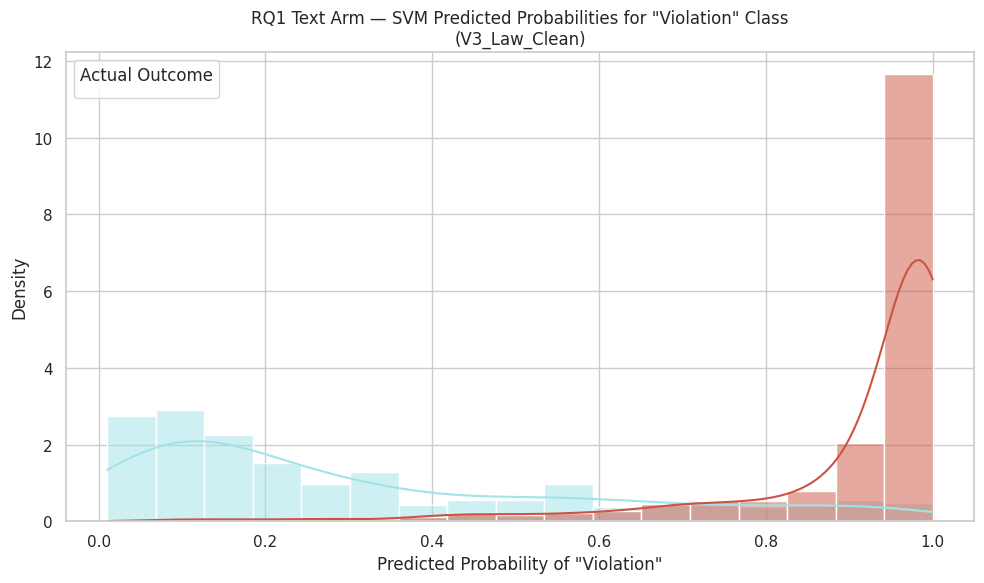

  Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_text_arm_svm_proba_dist_V3_Law_Clean.png

Summary of Cross-Entropy Loss for Text Arm SVM Models:
     Variant  Cross_Entropy_Loss_Mean  Cross_Entropy_Loss_Std
    V1_Facts                 0.409303                0.013741
 V2_Law_Full                 0.184490                0.020430
V3_Law_Clean                 0.215964                0.023239


In [ ]:
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, cross_val_predict


# Reuse df_text and y from RQ1 Text Arm section
# df_text and y are already defined in cell L1W-9qenW7an

# Initialize StratifiedKFold (same as used in previous evaluations)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

text_variant_results = []

print('Calculating Cross-Entropy Loss and generating probability charts for Text Arm SVM models...')
print('-' * 90)

for variant_name, (text_col, stop_words) in TEXT_VARIANTS.items():
    X_text_variant = df_text[text_col]
    y_text_variant = y

    print(f"\n── Processing Variant: {variant_name} ({text_col}) ──")

    # Build the SVM pipeline for the current text variant
    # Re-using the pipeline structure and classifier from RQ1 Text Arm setup
    svm_pipeline_text_arm = Pipeline([
        ('tfidf', TfidfVectorizer(
            stop_words   = stop_words,
            max_features = 5000,  # Reduced max_features for faster execution
            ngram_range  = (1, 2),
            sublinear_tf = True
        )),
        ('clf', CLASSIFIERS['SVM']) # Use the SVM from CLASSIFIERS dict
    ])

    log_losses_variant = []
    y_pred_proba_variant = np.zeros((len(y_text_variant), len(y_text_variant.unique())))

    for fold_idx, (train_idx, test_idx) in enumerate(CV.split(X_text_variant, y_text_variant)):
        X_train_fold, X_test_fold = X_text_variant.iloc[train_idx], X_text_variant.iloc[test_idx]
        y_train_fold, y_test_fold = y_text_variant.iloc[train_idx], y_text_variant.iloc[test_idx]

        svm_pipeline_text_arm.fit(X_train_fold, y_train_fold)
        y_pred_proba_fold = svm_pipeline_text_arm.predict_proba(X_test_fold)

        log_losses_variant.append(log_loss(y_test_fold, y_pred_proba_fold, labels=svm_pipeline_text_arm.classes_))

        # Store probabilities for overall chart (if needed, though cross_val_predict is cleaner for this)
        # For direct plotting, cross_val_predict (used below) is generally better as it handles data splitting for visualization.
        # This loop is primarily for accurate log_loss per fold.

    mean_log_loss_variant = np.mean(log_losses_variant)
    std_log_loss_variant = np.std(log_losses_variant)
    print(f"  Cross-Entropy Loss ({variant_name} - SVM): {mean_log_loss_variant:.4f} ± {std_log_loss_variant:.4f}")

    text_variant_results.append({
        'Variant': variant_name,
        'Cross_Entropy_Loss_Mean': mean_log_loss_variant,
        'Cross_Entropy_Loss_Std': std_log_loss_variant
    })

    # Generate predicted probability chart for the variant
    y_pred_proba_cv = cross_val_predict(
        svm_pipeline_text_arm, X_text_variant, y_text_variant, cv=CV,
        method='predict_proba',
        n_jobs=-1
    )

    proba_df_variant = pd.DataFrame({
        'No Violation_proba': y_pred_proba_cv[:, 0],
        'Violation_proba': y_pred_proba_cv[:, 1],
        'actual_finding': y_text_variant
    })

    fig, ax = plt.subplots(figsize=(10, 6))
    sns.histplot(data=proba_df_variant, x='Violation_proba', hue='actual_finding',
                 kde=True, palette=PALETTE, ax=ax, stat='density', common_norm=False)

    ax.set_title(f'RQ1 Text Arm — SVM Predicted Probabilities for "Violation" Class\n({variant_name})')
    ax.set_xlabel('Predicted Probability of "Violation"')
    ax.set_ylabel('Density')
    ax.legend(title='Actual Outcome')
    plt.tight_layout()
    plt.savefig(f'{SAVE_PATH}rq1_text_arm_svm_proba_dist_{variant_name}.png', dpi=150)
    plt.show()
    print(f'  Predicted probability distribution chart saved to {SAVE_PATH}rq1_text_arm_svm_proba_dist_{variant_name}.png')

print('\n' + '=' * 90)
print('Summary of Cross-Entropy Loss for Text Arm SVM Models:')
print(pd.DataFrame(text_variant_results).to_string(index=False))



---
Top Predictive Terms


Classes: ['No Violation' 'Violation']


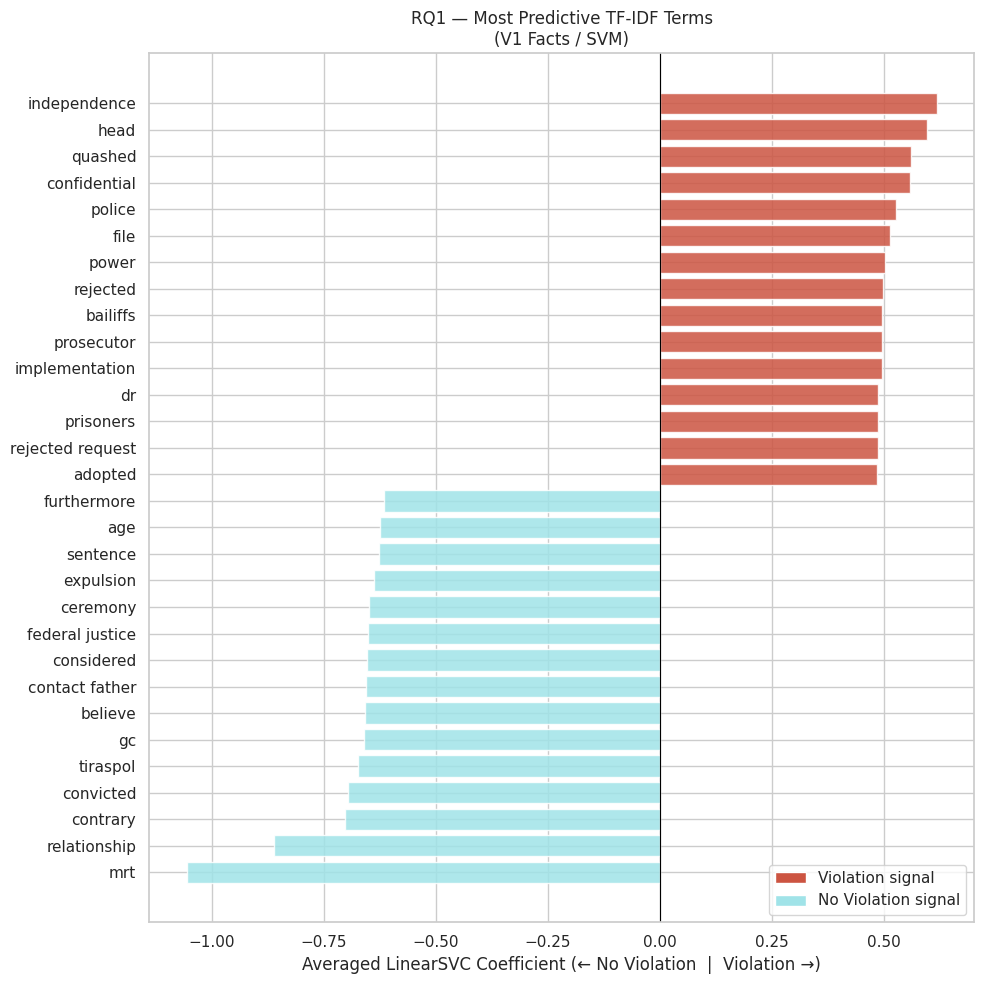

SVM top predictive terms chart saved.


In [ ]:
# ── Top Predictive Terms — V1 Facts / SVM ─────────────────────────
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Refit Facts + SVM pipeline on full data
best_facts_svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words   = custom_facts_stop_words,
        max_features = 10000,
        ngram_range  = (1, 2),
        sublinear_tf = True
    )),
    ('clf', CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    ))
])

best_facts_svm_pipeline.fit(df_text['facts_text'], y)

tfidf_vocab = best_facts_svm_pipeline.named_steps['tfidf'].get_feature_names_out()

# Extract coefficients from the base LinearSVC inside CalibratedClassifierCV
# CalibratedClassifierCV stores multiple calibrated estimators — average their coefs
base_estimators = best_facts_svm_pipeline.named_steps['clf'].calibrated_classifiers_
coef_matrix = np.array([
    est.estimator.coef_[0] for est in base_estimators
])
coef = coef_matrix.mean(axis=0)

# Determine positive class (Violation)
classes = best_facts_svm_pipeline.named_steps['clf'].classes_
print(f'Classes: {classes}')  # confirm which direction is positive

coef_series = pd.Series(coef, index=tfidf_vocab)

top_n = 15
top_violation    = coef_series.nlargest(top_n)
top_no_violation = coef_series.nsmallest(top_n)

diverging_df = pd.concat([
    top_violation.rename('coefficient'),
    top_no_violation.rename('coefficient')
]).sort_values()

colors = [PALETTE['Violation'] if v > 0 else PALETTE['No Violation']
          for v in diverging_df.values]

# ── Diverging Bar Chart ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(diverging_df.index, diverging_df.values,
        color=colors, alpha=0.85, edgecolor='white')
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Averaged LinearSVC Coefficient (← No Violation  |  Violation →)')
ax.set_title('RQ1 — Most Predictive TF-IDF Terms\n(V1 Facts / SVM)',
             fontsize=12)

legend_elements = [
    Patch(facecolor=PALETTE['Violation'],    label='Violation signal'),
    Patch(facecolor=PALETTE['No Violation'], label='No Violation signal')
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_top_predictive_terms_svm.png', dpi=150)
plt.show()
print('SVM top predictive terms chart saved.')

Classes: ['No Violation' 'Violation']


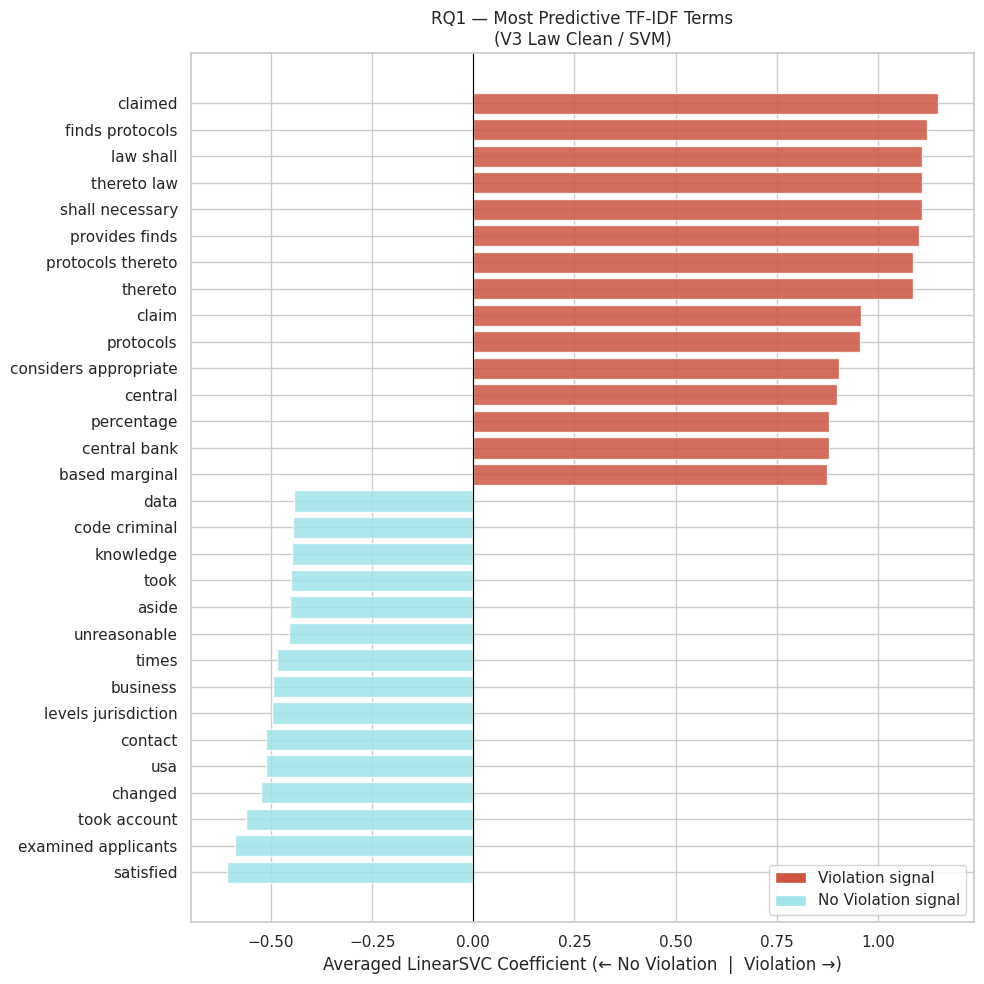

SVM top predictive terms chart saved.


In [ ]:
# ── Top Predictive Terms — V3 Law Clean / SVM
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Refit Facts + SVM pipeline on full data
best_law_clean_svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words   = custom_law_clean_stop_words,
        max_features = 10000,
        ngram_range  = (1, 2),
        sublinear_tf = True
    )),
    ('clf', CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    ))
])

best_law_clean_svm_pipeline.fit(df_text['law_text_clean'], y)

tfidf_vocab = best_law_clean_svm_pipeline.named_steps['tfidf'].get_feature_names_out()

# Extract coefficients from the base LinearSVC inside CalibratedClassifierCV
# CalibratedClassifierCV stores multiple calibrated estimators — average their coefs
base_estimators = best_law_clean_svm_pipeline.named_steps['clf'].calibrated_classifiers_
coef_matrix = np.array([
    est.estimator.coef_[0] for est in base_estimators
])
coef = coef_matrix.mean(axis=0)

# Determine positive class (Violation)
classes = best_law_clean_svm_pipeline.named_steps['clf'].classes_
print(f'Classes: {classes}')  # confirm which direction is positive

coef_series = pd.Series(coef, index=tfidf_vocab)

top_n = 15
top_violation    = coef_series.nlargest(top_n)
top_no_violation = coef_series.nsmallest(top_n)

diverging_df = pd.concat([
    top_violation.rename('coefficient'),
    top_no_violation.rename('coefficient')
]).sort_values()

colors = [PALETTE['Violation'] if v > 0 else PALETTE['No Violation']
          for v in diverging_df.values]

# ── Diverging Bar Chart ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(diverging_df.index, diverging_df.values,
        color=colors, alpha=0.85, edgecolor='white')
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Averaged LinearSVC Coefficient (← No Violation  |  Violation →)')
ax.set_title('RQ1 — Most Predictive TF-IDF Terms\n(V3 Law Clean / SVM)',
             fontsize=12)

legend_elements = [
    Patch(facecolor=PALETTE['Violation'],    label='Violation signal'),
    Patch(facecolor=PALETTE['No Violation'], label='No Violation signal')
]
ax.legend(handles=legend_elements, loc='lower right')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_top_predictive_terms_svm.png', dpi=150)
plt.show()
print('SVM top predictive terms chart saved.')



---


##PCA Scatter for Text
The PCA charts are based purely on the TF-IDF matrix of the text section (no classifier is involved).
PCA just compresses 10,000 TF-IDF dimensions into 2 so you can see the document space visually **to see if the class separation is weak or strong.**

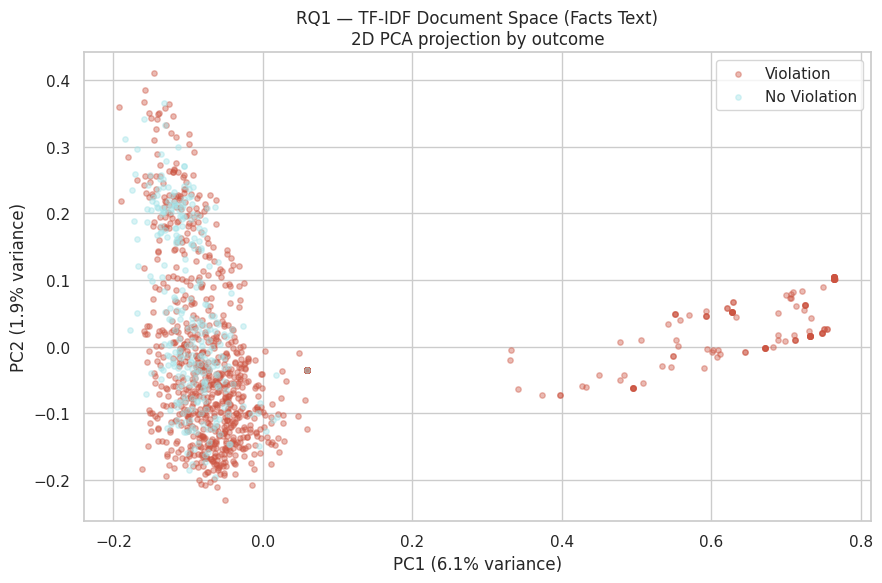

In [ ]:
# Reduce TF-IDF matrix to 2D
pca = PCA(n_components=2, random_state=42)

# Re-apply the TFIDF transformation for 'Facts Text' to get X_tfidf
# We can reuse the TfidfVectorizer from the best_facts_svm_pipeline
tfidf_vectorizer_facts = best_facts_svm_pipeline.named_steps['tfidf']
X_tfidf = tfidf_vectorizer_facts.transform(df_text['facts_text'])

X_dense = X_tfidf.toarray()
X_pca   = pca.fit_transform(X_dense)

pca_df = pd.DataFrame({
    'PC1'    : X_pca[:, 0],
    'PC2'    : X_pca[:, 1],
    'outcome': y.values
})

fig, ax = plt.subplots(figsize=(9, 6))
for outcome, color in PALETTE.items():
    mask = pca_df['outcome'] == outcome
    ax.scatter(pca_df.loc[mask, 'PC1'], pca_df.loc[mask, 'PC2'],
               c=color, label=outcome, alpha=0.4, s=15)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('RQ1 — TF-IDF Document Space (Facts Text)\n2D PCA projection by outcome')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_pca_document_space.png', dpi=150)
plt.show()

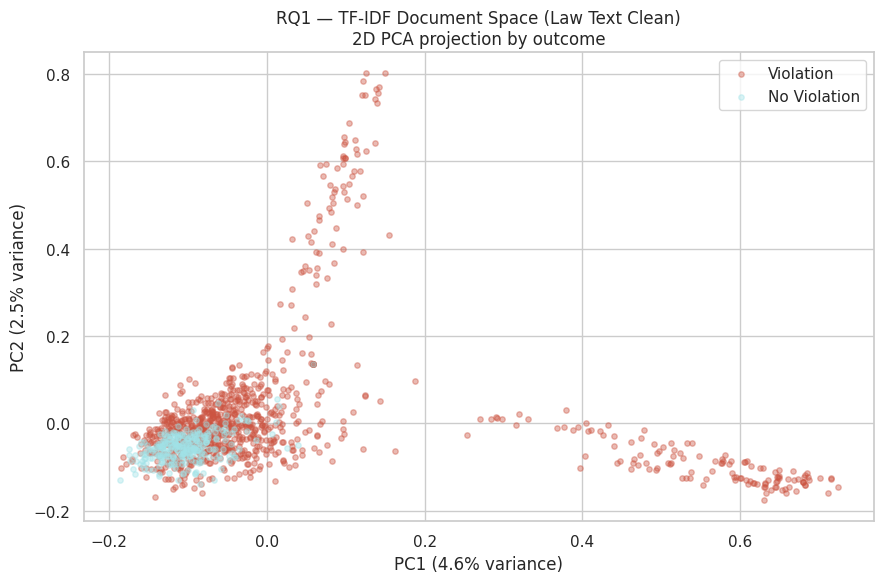

In [ ]:

# Reduce TF-IDF matrix to 2D for law_text_clean
pca_law_clean = PCA(n_components=2, random_state=42)

# Re-apply the TFIDF transformation for 'Law Text Clean' to get X_tfidf_law_clean
# We need the TfidfVectorizer from the best_law_clean_svm_pipeline
tfidf_vectorizer_law_clean = best_law_clean_svm_pipeline.named_steps['tfidf']
X_tfidf_law_clean = tfidf_vectorizer_law_clean.transform(df_text['law_text_clean'])

X_dense_law_clean = X_tfidf_law_clean.toarray()
X_pca_law_clean   = pca_law_clean.fit_transform(X_dense_law_clean)

pca_df_law_clean = pd.DataFrame({
    'PC1'    : X_pca_law_clean[:, 0],
    'PC2'    : X_pca_law_clean[:, 1],
    'outcome': y.values
})

fig_law_clean, ax_law_clean = plt.subplots(figsize=(9, 6))
for outcome, color in PALETTE.items():
    mask_law_clean = pca_df_law_clean['outcome'] == outcome
    ax_law_clean.scatter(pca_df_law_clean.loc[mask_law_clean, 'PC1'], pca_df_law_clean.loc[mask_law_clean, 'PC2'],
                         c=color, label=outcome, alpha=0.4, s=15)

ax_law_clean.set_xlabel(f'PC1 ({pca_law_clean.explained_variance_ratio_[0]*100:.1f}% variance)')
ax_law_clean.set_ylabel(f'PC2 ({pca_law_clean.explained_variance_ratio_[1]*100:.1f}% variance)')
ax_law_clean.set_title('RQ1 — TF-IDF Document Space (Law Text Clean)\n2D PCA projection by outcome')
ax_law_clean.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_pca_document_space_law_clean.png', dpi=150)
plt.show()

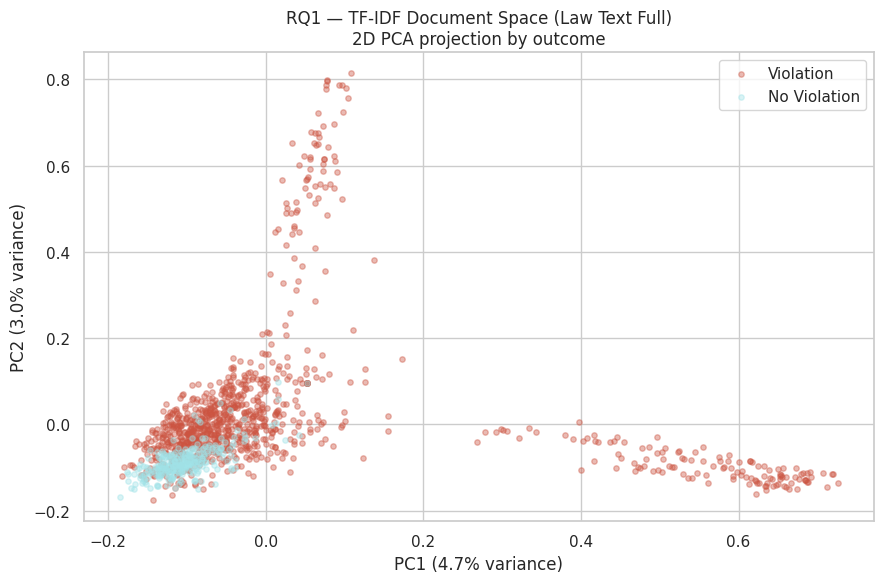

In [ ]:
# Reduce TF-IDF matrix to 2D for law_text (Full)
pca_law_full = PCA(n_components=2, random_state=42)

# Re-apply the TFIDF transformation for 'Law Text Full' to get X_tfidf_law_full
tfidf_vectorizer_law_full = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words   = custom_law_stop_words,
        max_features = 10000,
        ngram_range  = (1, 2),
        sublinear_tf = True       # log normalization — better for long legal docs
    )),
    ('clf', CLASSIFIERS['SVM']) # Use SVM from CLASSIFIERS as a placeholder for pipeline structure
]).named_steps['tfidf']

X_tfidf_law_full = tfidf_vectorizer_law_full.fit_transform(df_text['law_text'])

X_dense_law_full = X_tfidf_law_full.toarray()
X_pca_law_full   = pca_law_full.fit_transform(X_dense_law_full)

pca_df_law_full = pd.DataFrame({
    'PC1'    : X_pca_law_full[:, 0],
    'PC2'    : X_pca_law_full[:, 1],
    'outcome': y.values
})

fig_law_full, ax_law_full = plt.subplots(figsize=(9, 6))
for outcome, color in PALETTE.items():
    mask_law_full = pca_df_law_full['outcome'] == outcome
    ax_law_full.scatter(pca_df_law_full.loc[mask_law_full, 'PC1'], pca_df_law_full.loc[mask_law_full, 'PC2'],
                         c=color, label=outcome, alpha=0.4, s=15)

ax_law_full.set_xlabel(f'PC1 ({pca_law_full.explained_variance_ratio_[0]*100:.1f}% variance)')
ax_law_full.set_ylabel(f'PC2 ({pca_law_full.explained_variance_ratio_[1]*100:.1f}% variance)')
ax_law_full.set_title('RQ1 — TF-IDF Document Space (Law Text Full)\n2D PCA projection by outcome')
ax_law_full.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_pca_document_space_law_full.png', dpi=150)
plt.show()


**Analysis**:

PCA projection of the TF-IDF document space shows **weak class separation.** Weakest separation can be found in Facts section

##Metadata + Text (Law Clean)



---


Data Preparation

In [ ]:
# ── Step 1: Build combined dataset ──────────────────────────
# Must have both text and metadata available
df_combined = df_art8[
    df_art8['finding'].isin(['Violation', 'No Violation'])
].copy()
df_combined = df_combined.dropna(subset=['law_text_clean'])

# Feature columns
CAT_FEATURES = ['respondent_country', 'importance', 'court', 'typedescription']
NUM_FEATURES = ['year', 'has_dissent', 'is_english']
TEXT_COL = 'law_text_clean'
TARGET = 'finding'

# Fill NAs for metadata
for col in CAT_FEATURES:
    df_combined[col] = df_combined[col].astype(str).fillna('unknown')
for col in NUM_FEATURES:
    df_combined[col] = df_combined[col].fillna(0)

print(f"Combined dataset: {len(df_combined):,} cases")
print(df_combined[TARGET].value_counts())


Combined dataset: 1,265 cases
finding
Violation       982
No Violation    283
Name: count, dtype: int64


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
import scipy.sparse as sp

# ── Step 2: Custom transformer to extract text column ───────
# Needed because FeatureUnion requires array input, not DataFrame
class TextExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, col):
        self.col = col
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.col].fillna('').values

class MetadataExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, num_cols):
        self.cat_cols = cat_cols
        self.num_cols = num_cols
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.cat_cols + self.num_cols]

# ── Step 3: Build combined preprocessor ─────────────────────
metadata_preprocessor = Pipeline([
    ('extract', MetadataExtractor(CAT_FEATURES, NUM_FEATURES)),
    ('encode', ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         list(range(len(CAT_FEATURES)))),
        ('num', StandardScaler(),
         list(range(len(CAT_FEATURES), len(CAT_FEATURES) + len(NUM_FEATURES))))
    ]))
])

text_preprocessor = Pipeline([
    ('extract', TextExtractor(TEXT_COL)),
    ('tfidf', TfidfVectorizer(
        stop_words=list(custom_law_clean_stop_words),
        max_features=10000,
        ngram_range=(1, 2),
        sublinear_tf=True
    ))
])

# ── Step 4: Custom combiner to merge sparse + dense ─────────
class FeatureCombiner(BaseEstimator, TransformerMixin):
    """
    Combines dense metadata features with sparse TF-IDF features.
    sklearn FeatureUnion struggles with mixed sparse/dense — this handles it.
    """
    def __init__(self, meta_pipe, text_pipe):
        self.meta_pipe = meta_pipe
        self.text_pipe = text_pipe

    def fit(self, X, y=None):
        self.meta_pipe.fit(X, y)
        self.text_pipe.fit(X, y)
        return self

    def transform(self, X):
        meta_features = self.meta_pipe.transform(X)  # dense
        text_features = self.text_pipe.transform(X)  # sparse
        # Convert dense to sparse and stack horizontally
        meta_sparse = sp.csr_matrix(meta_features)
        return sp.hstack([meta_sparse, text_features])

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)



---


Model Training

In [ ]:
# ── Step 5: Build full pipelines ────────────────────────────
combiner = FeatureCombiner(metadata_preprocessor, text_preprocessor)

COMBINED_CLASSIFIERS = {
    'SVM': ImbPipeline([
        ('features', combiner),
        ('smote', SMOTE(random_state=42)),
        ('clf', CalibratedClassifierCV(
            LinearSVC(class_weight='balanced', max_iter=2000, random_state=42)
        ))
    ])
}

# ── Step 6: Run CV ───────────────────────────────────────────
X_combined = df_combined[CAT_FEATURES + NUM_FEATURES + [TEXT_COL]]
y_combined = df_combined[TARGET]

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
combined_results = []

print("\nRunning Metadata + Text (Law Clean) combined classifiers...")
print("-" * 55)

for clf_name, clf_pipeline in COMBINED_CLASSIFIERS.items():
    scores = cross_validate(
        clf_pipeline, X_combined, y_combined,
        cv=CV,
        scoring=['f1_weighted', 'accuracy', 'precision_weighted', 'recall_weighted'],
        n_jobs=-1
    )
    combined_results.append({
        'Model': f'Combined_{clf_name}',
        'F1': scores['test_f1_weighted'].mean(),
        'F1std': scores['test_f1_weighted'].std(),
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision_weighted'].mean(),
        'Recall': scores['test_recall_weighted'].mean(),
    })
    print(f"  {clf_name:<25s} F1 {combined_results[-1]['F1']:.4f} \u00b1 {combined_results[-1]['F1std']:.4f}")

# ── Step 7: Build comparison table ──────────────────────────
df_combined_results = pd.DataFrame(combined_results).sort_values('F1', ascending=False).round(4)

# Pull best scores from prior arms for comparison
best_metadata_f1 = metadata_f1_floor       # from your metadata arm cell
best_text_f1 = best_text_f1                # from your text arm cell

print("\n" + "=" * 60)
print("RQ1 — THREE-ARM COMPARISON")
print("=" * 60)
print(f"  Metadata only:           F1 = {best_metadata_f1:.4f}")
print(f"  Text only / Law Clean :   F1 = {best_text_f1:.4f}")
for _, row in df_combined_results.iterrows():
    print(f"  {row['Model']:<35} F1 = {row['F1']:.4f}")


Running Metadata + Text (Law Clean) combined classifiers...
-------------------------------------------------------
  SVM                       F1 0.8870 ± 0.0126

RQ1 — THREE-ARM COMPARISON
  Metadata only:           F1 = 0.7302
  Text only / Law Clean :   F1 = 0.9337
  Combined_SVM                        F1 = 0.8870




---

Confusion Matrix

Generating Confusion Matrix for Combined Text + Metadata SVM model...
----------------------------------------------------------------------


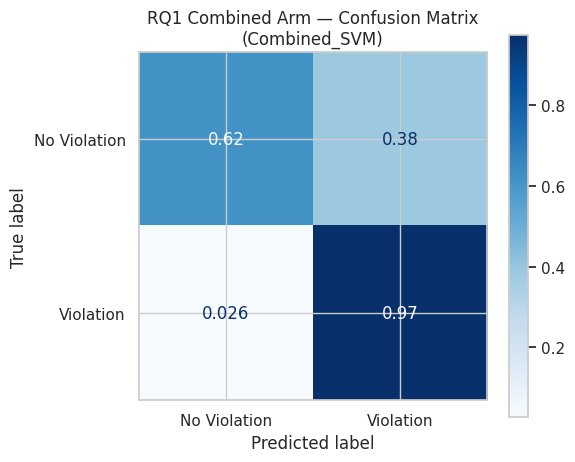

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_combined_confusion_matrix_svm.png

Confusion matrix for Combined Text + Metadata SVM model generated and saved.


In [ ]:
print('Generating Confusion Matrix for Combined Text + Metadata SVM model...')
print('-' * 70)

# Reuse X_combined and y_combined from the combined arm setup
# X_combined and y_combined are already defined in cell NyO39s2dQPWr

# Get the combined SVM pipeline
combined_svm_pipeline = COMBINED_CLASSIFIERS['SVM']

# Initialize StratifiedKFold (same as used in previous evaluations)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Get predictions using cross_val_predict
y_pred_combined = cross_val_predict(
    combined_svm_pipeline, X_combined, y_combined, cv=CV,
    method='predict',
    n_jobs=-1
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_combined, y_pred_combined,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax
)
ax.set_title(f'RQ1 Combined Arm — Confusion Matrix\n(Combined_SVM)')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_combined_confusion_matrix_svm.png', dpi=150)
plt.show()
print(f'  Confusion matrix chart saved to {SAVE_PATH}rq1_combined_confusion_matrix_svm.png')

print('\n' + '=' * 70)
print('Confusion matrix for Combined Text + Metadata SVM model generated and saved.')



---

Verdict


VERDICT: ➡️  MARGINAL GAIN — Combined slightly beats text alone but not decisively over metadata.

Saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq1_combined_arm_results.csv


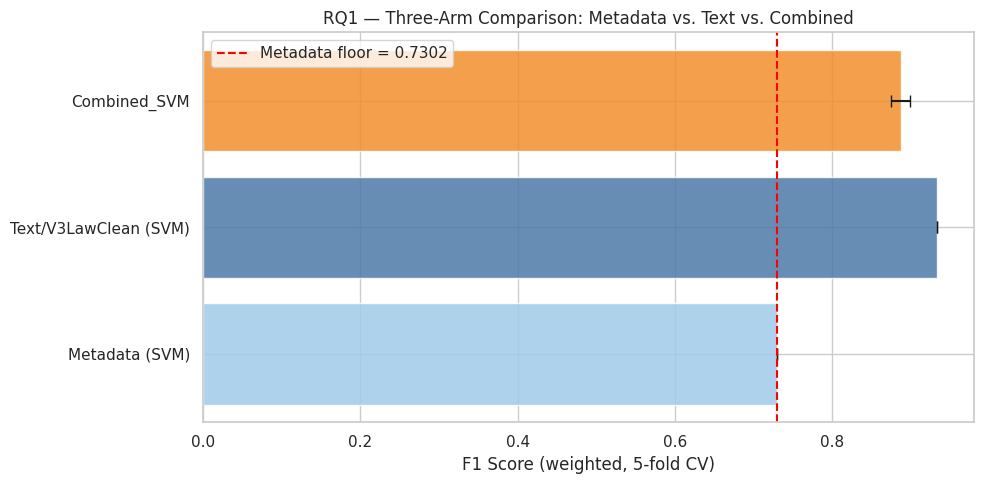

Chart saved.


In [ ]:
# ── Step 8: Verdict ──────────────────────────────────────────
best_combined_f1 = df_combined_results.iloc[0]['F1']

if best_combined_f1 > best_text_f1 + 0.01:
    verdict = "✅ COMPLEMENTARY — Combined beats both arms. Metadata and text capture different signal."
elif best_combined_f1 <= best_metadata_f1 + 0.01:
    verdict = "⚠️  REDUNDANT — Combined adds nothing over metadata. Text signal is absorbed by country features."
else:
    verdict = "➡️  MARGINAL GAIN — Combined slightly beats text alone but not decisively over metadata."

print(f"\nVERDICT: {verdict}")

# ── Step 9: Save ─────────────────────────────────────────────
df_combined_results.to_csv(f"{SAVE_PATH}rq1_combined_arm_results.csv", index=False)
print(f"\nSaved to {SAVE_PATH}rq1_combined_arm_results.csv")

# ── Step 10: Visualisation ───────────────────────────────────
all_arms = pd.DataFrame([
    {'Model': f'Metadata ({metadata_best_model_name})', 'F1': best_metadata_f1, 'F1std': 0, 'Arm': 'Metadata'},
    {'Model': f'Text/V3LawClean (SVM)', 'F1': best_text_f1, 'F1std': 0, 'Arm': 'Text'},
] + [{'Model': r['Model'], 'F1': r['F1'], 'F1std': r['F1std'], 'Arm': 'Combined'}
     for _, r in df_combined_results.iterrows()])

colors = {'Metadata': '#a0cbe8', 'Text': '#4e79a7', 'Combined': '#f28e2b'}
bar_colors = [colors[arm] for arm in all_arms['Arm']]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(all_arms['Model'], all_arms['F1'],
        xerr=all_arms['F1std'],
        color=bar_colors, capsize=4, alpha=0.85)
ax.axvline(x=best_metadata_f1, color='red', linestyle='--', linewidth=1.5,
           label=f'Metadata floor = {best_metadata_f1:.4f}')
ax.set_xlabel('F1 Score (weighted, 5-fold CV)')
ax.set_title('RQ1 — Three-Arm Comparison: Metadata vs. Text vs. Combined')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq1_three_arm_comparison.png', dpi=150)
plt.show()
print("Chart saved.")


**Analysis**

The combined model demonstrates strong predictive capabilities across both classes, though its performance, while excellent, still falls slightly behind the best text-only model



---


#**RQ2 : Topic Clustering**




**"What are the dominant themes in Article 8 cases?"**




* **Input:**
Facts + Law Full combined together





* **Model:**
NMF





* **Output:**
Topic Cluster


##NMF on All Art8 Cases

Data Preparation

In [ ]:
from sklearn.decomposition import NMF
import matplotlib.ticker as mticker
from itertools import product

print("RQ2 imports ready.")

RQ2 imports ready.


In [ ]:
# Full corpus for topic discovery; decided cases for cross-tabulation
df_nmf = df_art8[df_art8['analysis_text'].str.len() > 50].copy()
df_nmf_decided = df_nmf[df_nmf['finding'].isin(['Violation', 'No Violation'])].copy()

print(f"NMF training corpus: {len(df_nmf)} cases")
print(f"Decided cases (for cross-tab): {len(df_nmf_decided)} cases")
print(f"Violation: {(df_nmf_decided['finding']=='Violation').sum()} | No Violation: {(df_nmf_decided['finding']=='No Violation').sum()}")

NMF training corpus: 1321 cases
Decided cases (for cross-tab): 1265 cases
Violation: 982 | No Violation: 283


In [ ]:
# TF-IDF for NMF — sublinear_tf and min_df to reduce noise
tfidf_nmf = TfidfVectorizer(
    stop_words=list(custom_analysis_stop_words),
    max_features=5000,
    min_df=5,
    max_df=0.90,
    sublinear_tf=True,
    ngram_range=(1, 2)
)

X_nmf_full = tfidf_nmf.fit_transform(df_nmf['analysis_text'])
X_nmf_decided = tfidf_nmf.transform(df_nmf_decided['analysis_text'])

feature_names = tfidf_nmf.get_feature_names_out()
print(f"Vocabulary size: {len(feature_names)}")
print(f"Full corpus matrix: {X_nmf_full.shape}")
print(f"Decided corpus matrix: {X_nmf_decided.shape}")

Vocabulary size: 5000
Full corpus matrix: (1321, 5000)
Decided corpus matrix: (1265, 5000)




---


Find best-K (5 min)

In [ ]:
# Approximate topic coherence via mean top-word TF-IDF score
def compute_coherence(model, X, n_top_words=10):
    scores = []
    for topic_idx, topic in enumerate(model.components_):
        top_indices = topic.argsort()[-n_top_words:]
        top_word_scores = X[:, top_indices].toarray()
        scores.append(np.mean(top_word_scores[top_word_scores > 0]))
    return np.nanmean(scores)

k_values = [3, 5, 7, 10, 15, 20, 25, 30, 35, 40, 45, 50]
coherence_scores = []
nmf_models = {}

for k in k_values:
    model = NMF(n_components=k, random_state=42, max_iter=400)
    W = model.fit_transform(X_nmf_full)
    nmf_models[k] = {'model': model, 'W': W}
    coh = compute_coherence(model, X_nmf_full)
    coherence_scores.append(coh)
    print(f"k={k:>2} | Reconstruction Error: {model.reconstruction_err_:.2f} | Coherence: {coh:.4f}")

k= 3 | Reconstruction Error: 30.71 | Coherence: 0.0436
k= 5 | Reconstruction Error: 29.96 | Coherence: 0.0430
k= 7 | Reconstruction Error: 29.51 | Coherence: 0.0524
k=10 | Reconstruction Error: 28.94 | Coherence: 0.0503
k=15 | Reconstruction Error: 28.20 | Coherence: 0.0488
k=20 | Reconstruction Error: 27.75 | Coherence: 0.0481
k=25 | Reconstruction Error: 27.38 | Coherence: 0.0467
k=30 | Reconstruction Error: 27.05 | Coherence: 0.0472
k=35 | Reconstruction Error: 26.75 | Coherence: 0.0463
k=40 | Reconstruction Error: 26.50 | Coherence: 0.0459
k=45 | Reconstruction Error: 26.28 | Coherence: 0.0478
k=50 | Reconstruction Error: 26.06 | Coherence: 0.0473


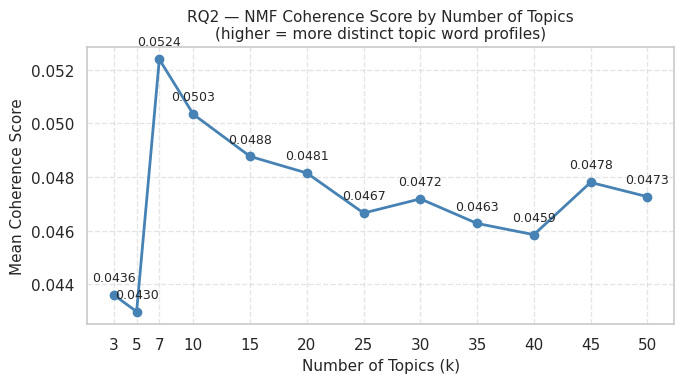

Saved: rq2_coherence_sweep.png


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values, coherence_scores, marker='o', linewidth=2, color='steelblue')
for k, s in zip(k_values, coherence_scores):
    ax.annotate(f"{s:.4f}", (k, s), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9)
ax.set_xlabel("Number of Topics (k)", fontsize=11)
ax.set_ylabel("Mean Coherence Score", fontsize=11)
ax.set_title("RQ2 — NMF Coherence Score by Number of Topics\n(higher = more distinct topic word profiles)", fontsize=11)
ax.set_xticks(k_values)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
print("Saved: rq2_coherence_sweep.png")



---

Model Training

In [ ]:
# ---- ADJUST k_chosen after reviewing coherence chart ----
k_chosen = 40

nmf_model = nmf_models[k_chosen]['model']
W_full = nmf_models[k_chosen]['W']
W_decided = nmf_model.transform(X_nmf_decided)

n_top_words = 15
print(f"\n=== NMF Topics (k={k_chosen}) — Top {n_top_words} Words ===\n")
topic_labels = {}
for topic_idx, topic in enumerate(nmf_model.components_):
    top_words = [feature_names[i] for i in topic.argsort()[-n_top_words:][::-1]]
    print(f"Topic {topic_idx+1}: {' | '.join(top_words)}")
    topic_labels[topic_idx] = f"T{topic_idx+1}"  # replace with manual labels after reviewing

# After running, manually update topic_labels like:
# topic_labels = {0: "Surveillance", 1: "Child Custody", 2: "Deportation", ...}

topic_labels = {
    0:  "Police Misconduct & Investigation",  # officers, injuries, prosecutors office, investigator, arrest
    1:  "Russia Batch Applications",         # appended table, wellestablished caselaw, inadequate conditions
    2:  "Remedies & Damages",                 # plus tax, eur, nonpecuniary damage, costs, expenses
    3:  "Parental Rights & Upbringing",       # childs, best interests, upbringing, father, mother, care
    4:  "Press & Image Rights",               # freedom expression, publication, axel springer, von hannover
    5:  "Immigration & Asylum",               # residence permit, asylum, aliens, refugee, territory
    6:  "Russia Covert Surveillance",         # surveillance, secret surveillance, appended table, interception
    7:  "Default Interest Rate",              # rate, default rate, european central, percentage points
    8:  "UK Public Law & Judicial Review",    # lord, secretary, england, judicial review, statutory
    9:  "Video Surveillance & Detention",     # permanent video, postconviction, detention facilities, pretrial
    10: "Prison Cell Conditions",             # cell, inmates, space, overcrowding, toilet, sq
    11: "Hague Child Abduction",              # hague, return child, habitual residence, child abduction
    12: "Sexual Violence & Prosecution",      # sexual, rape, mc, victims, perpetrator, acts violence
    13: "Telephone Interception",             # conversations, recordings, telephone, tapping, intercepted
    14: "Croatian Legal Procedures",          # official gazette, zakon, croatian, sud, constitutional complaint
    15: "Enforcement of Child Contact",       # enforcement proceedings, bailiff, contact arrangements, interim
    16: "Medical & Healthcare Rights",        # patients, medical, hospital, doctors, pregnancy
    17: "Search & Seizure",                   # search, seizure, search warrant, premises, criminal procedure
    18: "Child Welfare & Care Orders",        # care order, child welfare, foster, welfare board, lobben
    19: "Prison Visits & Sentences",          # prison, visits, code execution, criminal sentences, visitors
    20: "Pre-trial Detention Length",         # pretrial detention, release, reasonable time, pending trial
    21: "Paternity & Birth Rights",           # paternity, biological father, born wedlock, dna, birth
    22: "Terrorism & Death Cases",            # burial, deceased, terrorist, funeral, death, relatives
    23: "Employment & Judicial Dismissal",    # dismissal, employment, disciplinary, judges, hcj, salary
    24: "Same-Sex & Gender Rights",           # samesex, samesex couples, legal recognition, orientation
    25: "Housing & Eviction",                 # eviction, housing, flat, tenancy, owner, property
    26: "Russia FSB & Migration",             # fms, exclusion order, migration service, fsb, russian federation
    27: "Exhaustion of Remedies",             # remedies, remedy, nonexhaustion, exhaustion, effective remedy
    28: "Environmental Pollution",            # pollution, environmental, noise, residential zone, sanitary
    29: "Discrimination (Art. 14)",           # discrimination, difference treatment, sex, religion, race
    30: "Pecuniary Damages",                  # pecuniary damage, causal link, rejects claim, damage alleged
    31: "Russia Cage/Courtroom",              # cage, metal, courtroom, degrading treatment, russia gc
    32: "Moldova/Transnistria Control",       # mrt, mozer, moldovan, republic moldova, effective control
    33: "Russia Geographic & Bailiffs",       # russian, moscow, rub, st petersburg, bailiffs service
    34: "Legal Costs Reimbursement",          # incurred, costs expenses, necessarily incurred, reasonable quantum
    35: "Data Protection & Privacy",          # personal data, data protection, processing, data subject
    36: "Military & State Intelligence",      # forces, organisations, intelligence, armed, assembly
    37: "Expulsion & Criminal Convictions",   # expulsion, danish, reentry ban, maslov, host country
    38: "Bulgarian Security Expulsion",       # bulgarian, supreme administrative, sofia, security service
    39: "Mental Health & Legal Capacity",     # psychiatric, legal capacity, disabilities, mental health
}


=== NMF Topics (k=40) — Top 15 Words ===

Topic 1: officers | police officers | police | injuries | illtreatment | prosecutors office | investigation | investigator | police station | questioned | arrest | station | events | prosecutors | officer
Topic 2: appended table | appended | table | wellestablished caselaw | examined material | wellestablished | inadequate conditions | russia | applications | russia nos | having examined | raised complaints | detention | complaints | disclose
Topic 3: plus tax | tax chargeable | chargeable | plus | tax | eur | eur nonpecuniary | costs | nonpecuniary damage | nonpecuniary | expenses | damage | damage plus | eur costs | costs expenses
Topic 4: childs | parental | parents | child | best interests | parent | childrens | best | children | interests child | upbringing | father | mother | contact | care
Topic 5: freedom expression | publication | reputation | expression | freedom | debate | newspaper | press | media | right freedom | axel springer | 



---

Topic Distribution by Outcome

In [ ]:
dominant_topics = np.argmax(W_decided, axis=1)
df_nmf_decided = df_nmf_decided.copy()
df_nmf_decided['dominant_topic'] = dominant_topics
df_nmf_decided['topic_label'] = df_nmf_decided['dominant_topic'].map(topic_labels)

print(df_nmf_decided.groupby(['topic_label', 'finding']).size().unstack(fill_value=0))

finding                            No Violation  Violation
topic_label                                               
Bulgarian Security Expulsion                  1         16
Child Welfare & Care Orders                  15         13
Croatian Legal Procedures                     2         10
Data Protection & Privacy                    15         37
Default Interest Rate                         0          9
Discrimination (Art. 14)                     12         28
Employment & Judicial Dismissal              11         23
Enforcement of Child Contact                 21         38
Environmental Pollution                       7         30
Exhaustion of Remedies                        1         30
Expulsion & Criminal Convictions             34         11
Hague Child Abduction                        13         40
Housing & Eviction                            3         37
Immigration & Asylum                         12         14
Legal Costs Reimbursement                     0         

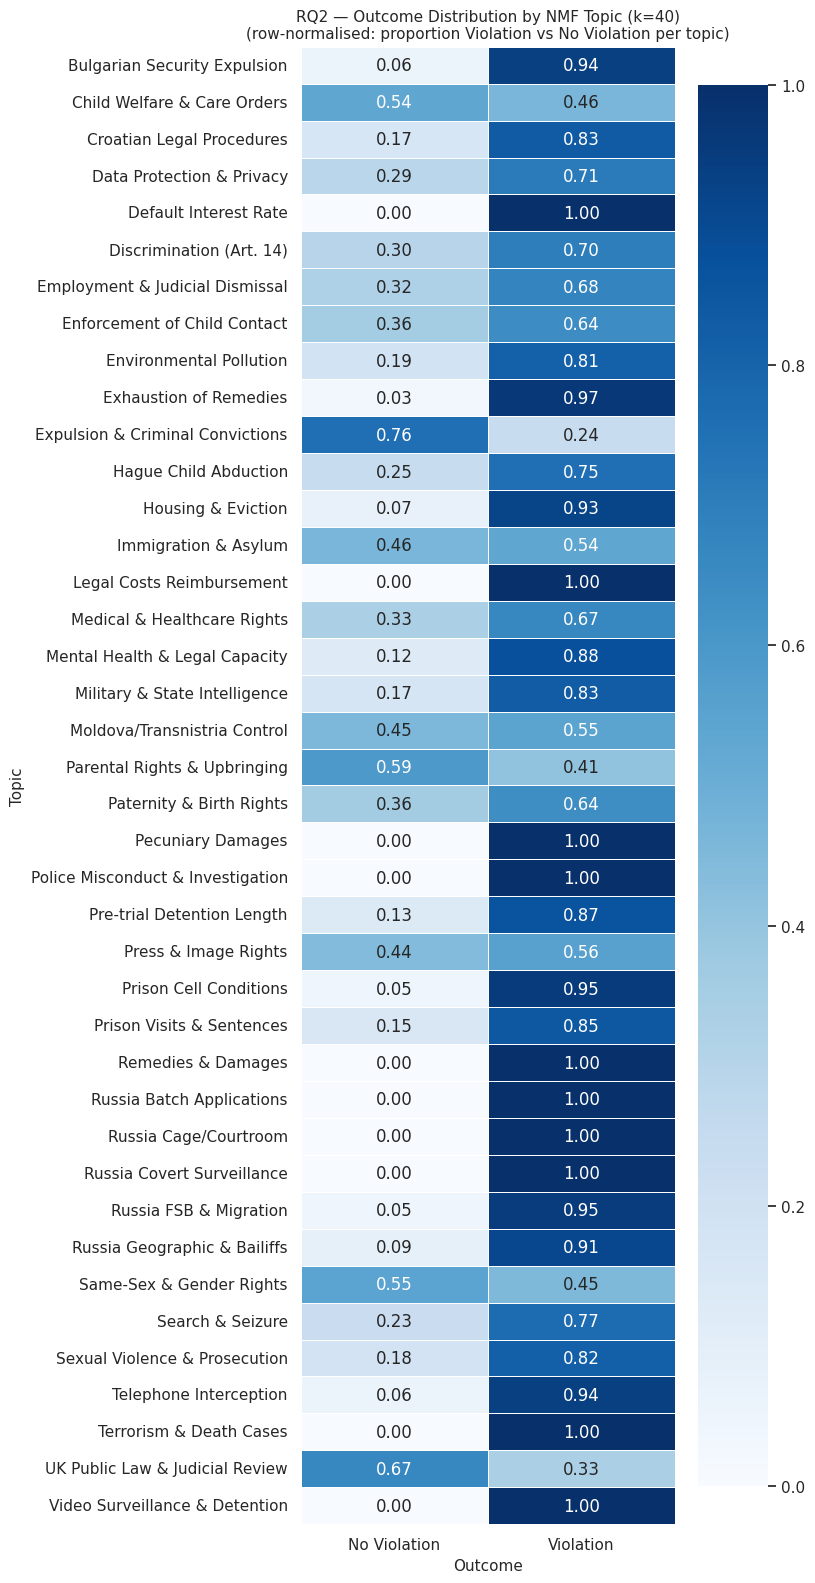

Saved: rq2_outcome_topic_heatmap.png


In [ ]:
cross_tab = pd.crosstab(
    df_nmf_decided['topic_label'],
    df_nmf_decided['finding'],
    normalize='index'  # row-normalised: proportion within each topic
)

# Calculate dynamic height based on number of topics
num_topics = len(cross_tab)
fig_height = max(5, num_topics * 0.4) # Adjust multiplier as needed, min height 5

fig, ax = plt.subplots(figsize=(8, fig_height))
sns.heatmap(
    cross_tab,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    ax=ax,
    vmin=0, vmax=1
)
ax.set_title(f"RQ2 — Outcome Distribution by NMF Topic (k={k_chosen})\n(row-normalised: proportion Violation vs No Violation per topic)", fontsize=11)
ax.set_xlabel("Outcome", fontsize=11)
ax.set_ylabel("Topic", fontsize=11)
plt.tight_layout()
plt.show()
print("Saved: rq2_outcome_topic_heatmap.png")

**Analysis**

Your dataset has roughly 1,265 Violation vs 283 No Violation cases.


In [ ]:
print('Beginning predictive modeling based on NMF topic clusters...')

# Reuse df_nmf_decided and W_decided from RQ2 (NMF topic modeling)
# X will be the NMF topic weights, y will be the finding (Violation/No Violation)
X_topics = W_decided # NMF document-topic matrix (dense numpy array)
y_topics = df_nmf_decided['finding']

# Define classifiers, similar to RQ1 but adapted for dense numerical input
# GaussianNB for Naive Bayes as the input is continuous topic weights
# SMOTE is included for Logistic Regression and SVM to handle class imbalance
TOPIC_CLASSIFIERS = {
    'Logistic Regression'  : ImbPipeline([
                                ('scaler', StandardScaler()), # Scale topic weights
                                ('smote', SMOTE(random_state=42)),
                                ('clf', LogisticRegression(max_iter=1000, random_state=42))
                            ]),
    'Naive Bayes'        : Pipeline([
                                ('scaler', StandardScaler()), # Scale topic weights
                                ('clf', GaussianNB()) # GaussianNB for continuous data
                            ]),
    'SVM'        : ImbPipeline([
                                ('scaler', StandardScaler()), # Scale topic weights
                                ('smote', SMOTE(random_state=42)),
                                ('clf', CalibratedClassifierCV(LinearSVC(random_state=42, max_iter=2000)))
                            ])
}

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Run all classifiers
topic_results = []
print('Running topic cluster classifiers...')
print('-' * 50)

for clf_name, clf_pipeline in TOPIC_CLASSIFIERS.items():
    scores = cross_validate(
        clf_pipeline, X_topics, y_topics, cv=CV,
        scoring  = ['f1_weighted', 'accuracy',
                    'precision_weighted', 'recall_weighted'],
        n_jobs   = -1
    )
    topic_results.append({
        'Model'    : clf_name,
        'F1'       : scores['test_f1_weighted'].mean(),
        'F1_std'   : scores['test_f1_weighted'].std(),
        'Accuracy' : scores['test_accuracy'].mean(),
        'Precision': scores['test_precision_weighted'].mean(),
        'Recall'   : scores['test_recall_weighted'].mean(),
    })
    print(f'{clf_name:25s} → F1: {topic_results[-1]["F1"]:.4f} ± {topic_results[-1]["F1_std"]:.4f}')

# Build results table
df_topic_results = (pd.DataFrame(topic_results)
                     .sort_values('F1', ascending=False)
                     .round(4)
                     .reset_index(drop=True))

print('\n' + '=' * 55)
print('PREDICTIVE MODELS ON TOPIC CLUSTERS (RQ2)')
print('=' * 55)
display(df_topic_results)

Beginning predictive modeling based on NMF topic clusters...
Running topic cluster classifiers...
--------------------------------------------------
Logistic Regression       → F1: 0.8959 ± 0.0037
Naive Bayes               → F1: 0.7974 ± 0.0267
SVM                       → F1: 0.8950 ± 0.0051

PREDICTIVE MODELS ON TOPIC CLUSTERS (RQ2)


,Model,F1,F1_std,Accuracy,Precision,Recall
0,Logistic Regression,0.8959,0.0037,0.8917,0.9075,0.8917
1,SVM,0.8950,0.0051,0.8909,0.9061,0.8909
2,Naive Bayes,0.7974,0.0267,0.7810,0.8572,0.7810


In [ ]:
# Compare with Metadata and Text results if available
print('\n' + '=' * 60)
print('COMPARISON WITH PREVIOUS ARMS')
print('=' * 60)
# Retrieve metadata_f1_floor from df_meta_results
metadata_f1_floor = df_meta_results.iloc[0]['F1']

# Retrieve best F1 for Facts-only and Law Clean-only variants from df_results
best_facts_f1 = df_results[df_results['Variant'] == 'V1_Facts'].iloc[0]['F1']
best_law_clean_f1 = df_results[df_results['Variant'] == 'V3_Law_Clean'].iloc[0]['F1']

# Retrieve best F1 for combined metadata+text (law clean) from df_combined_results
best_combined_f1 = df_combined_results.iloc[0]['F1']

print(f"  Metadata F1 floor      : {metadata_f1_floor:.4f}")
print(f"  Best Facts-only F1     : {best_facts_f1:.4f}")
print(f"  Best Law Clean-only F1 : {best_law_clean_f1:.4f}")
print(f"  Best Topic-based F1    : {df_topic_results.iloc[0]['F1']:.4f} ({df_topic_results.iloc[0]['Model']})")
print(f"  Best Combined F1       : {best_combined_f1:.4f} ({df_combined_results.iloc[0]['Model']})")


COMPARISON WITH PREVIOUS ARMS
  Metadata F1 floor      : 0.7302
  Best Facts-only F1     : 0.7889
  Best Law Clean-only F1 : 0.9122
  Best Topic-based F1    : 0.8959 (Logistic Regression)
  Best Combined F1       : 0.8870 (Combined_SVM)


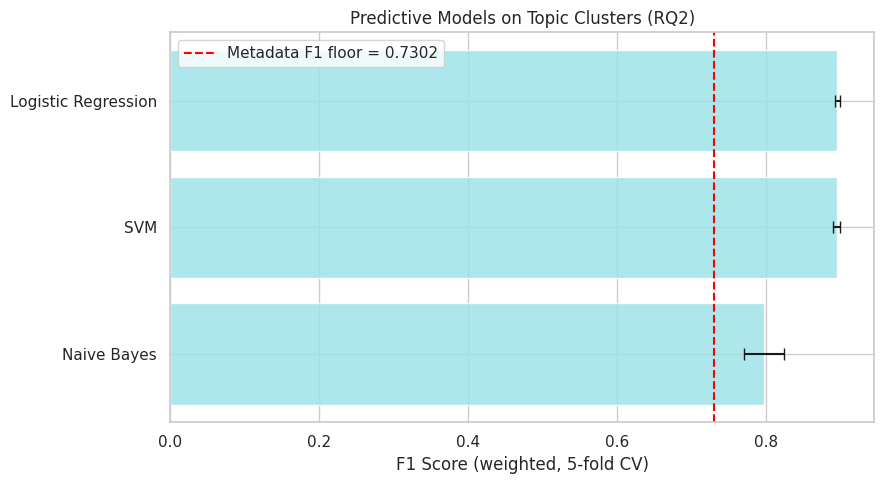

Results saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/


In [ ]:
# Visualization of results
fig, ax = plt.subplots(figsize=(9, 5))
plot_df = df_topic_results.sort_values('F1', ascending=True)
ax.barh(plot_df['Model'], plot_df['F1'],
        xerr=plot_df['F1_std'], color=PALETTE['No Violation'],
        capsize=4, alpha=0.85)
ax.axvline(x=metadata_f1_floor, color='red', linestyle='--', linewidth=1.5,
           label=f'Metadata F1 floor = {metadata_f1_floor:.4f}')
ax.set_xlabel('F1 Score (weighted, 5-fold CV)')
ax.set_title('Predictive Models on Topic Clusters (RQ2)')
ax.legend()
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq2_topic_model_leaderboard.png', dpi=150)
plt.show()

df_topic_results.to_csv(f'{SAVE_PATH}rq2_topic_model_results.csv', index=False)
print(f'Results saved to {SAVE_PATH}')

##NMF SVM

Generating Confusion Matrix for NMF Topic Cluster SVM model...
----------------------------------------------------------------------


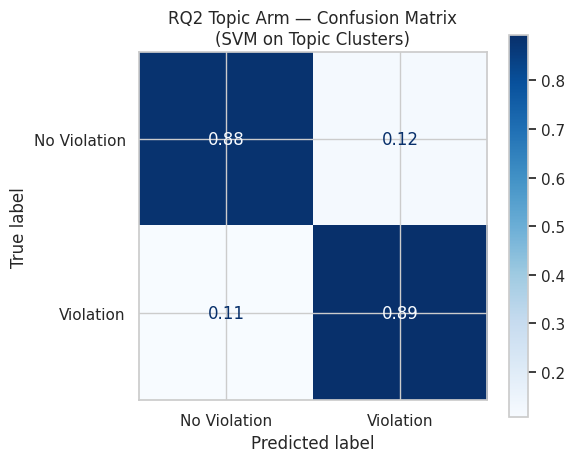

  Confusion matrix chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq2_topic_svm_confusion_matrix.png

Confusion matrix for SVM on Topic Clusters model generated and saved.


In [ ]:
print('Generating Confusion Matrix for NMF Topic Cluster SVM model...')
print('-' * 70)

# Get the SVM pipeline for topic clustering
svm_topic_pipeline = TOPIC_CLASSIFIERS['SVM']

# Get predictions using cross_val_predict
y_pred_topics = cross_val_predict(
    svm_topic_pipeline, X_topics, y_topics, cv=CV,
    method='predict',
    n_jobs=-1
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_topics, y_pred_topics,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax
)
ax.set_title(f'RQ2 Topic Arm — Confusion Matrix\n(SVM on Topic Clusters)')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq2_topic_svm_confusion_matrix.png', dpi=150)
plt.show()
print(f'  Confusion matrix chart saved to {SAVE_PATH}rq2_topic_svm_confusion_matrix.png')

print('\n' + '=' * 70)
print('Confusion matrix for SVM on Topic Clusters model generated and saved.')

Generating Feature Importance (Diverging Coefficients) for NMF Topic Cluster SVM model...
----------------------------------------------------------------------


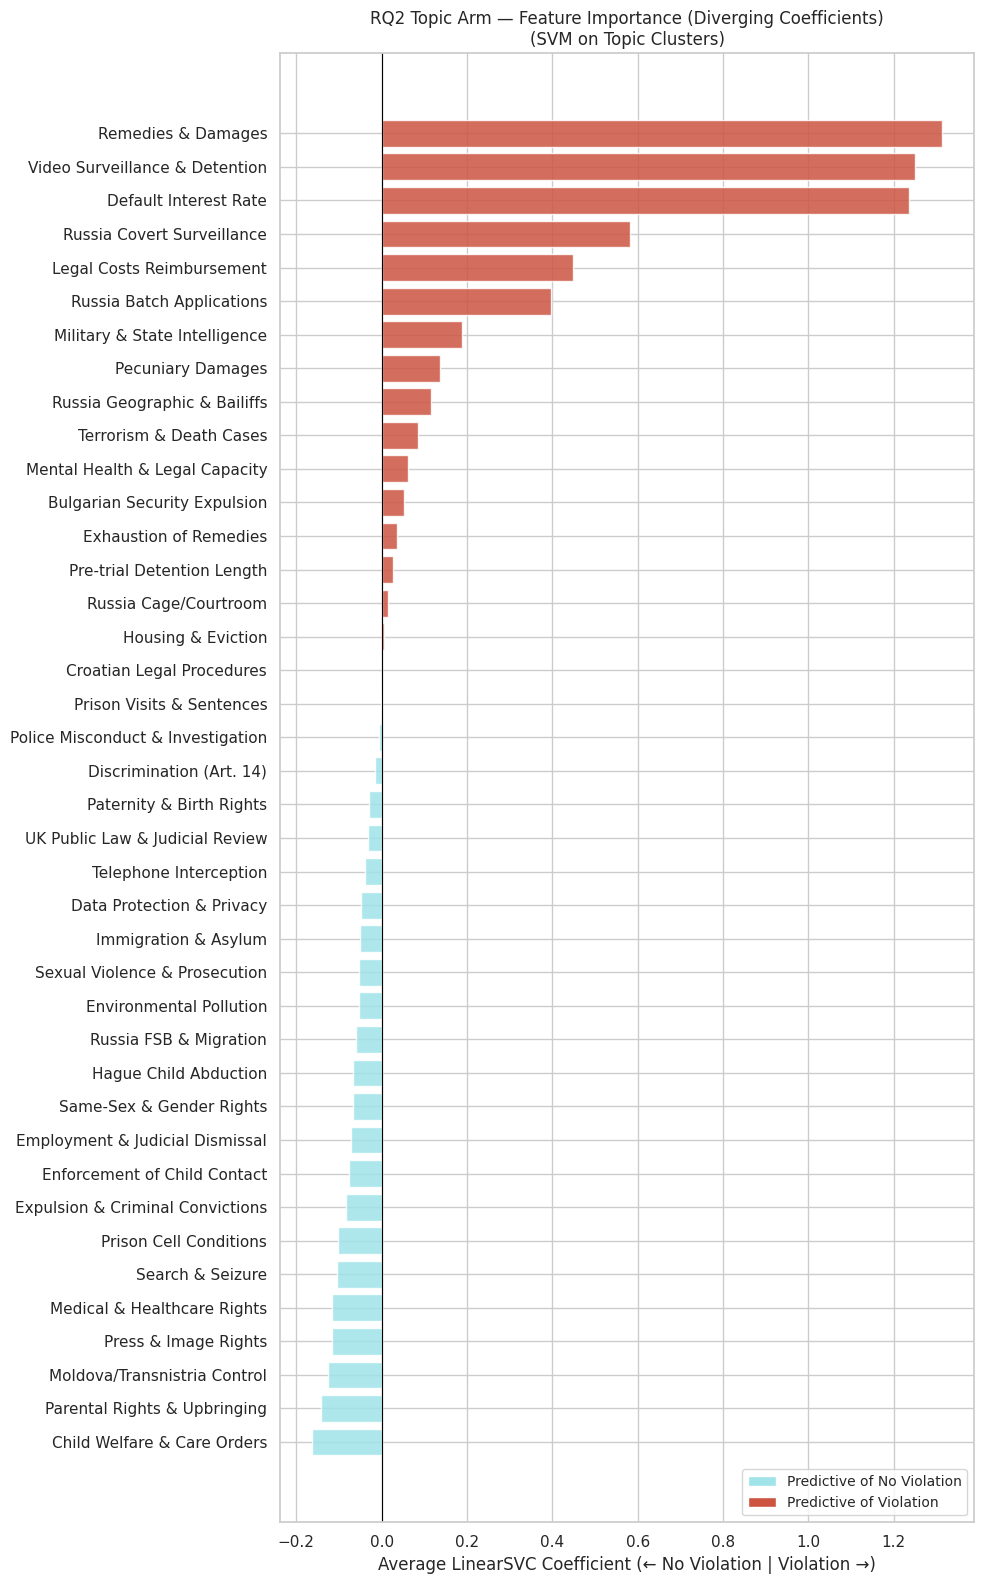

  Diverging feature importance chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq2_topic_svm_feature_importance_diverging.png

Diverging feature importance chart for SVM on Topic Clusters model generated and saved.


In [ ]:
print('Generating Feature Importance (Diverging Coefficients) for NMF Topic Cluster SVM model...')
print('-' * 70)

# Get the SVM pipeline for topic clustering
svm_topic_pipeline = TOPIC_CLASSIFIERS['SVM']

# Refit the pipeline on the full data to ensure it's trained for coefficient extraction
svm_topic_pipeline.fit(X_topics, y_topics)

# Extract coefficients from the base LinearSVC inside CalibratedClassifierCV
# CalibratedClassifierCV stores multiple calibrated estimators — average their coefs
base_estimators = svm_topic_pipeline.named_steps['clf'].calibrated_classifiers_
coef_matrix = np.array([
    est.estimator.coef_[0] for est in base_estimators
])
avg_coef = coef_matrix.mean(axis=0)

# Determine positive class (Violation) and negative class (No Violation)
classes = svm_topic_pipeline.named_steps['clf'].classes_
# Assuming classes are ['No Violation', 'Violation'], positive coefs predict 'Violation'
positive_class_label = 'Violation'
negative_class_label = 'No Violation'

# Get topic labels from RQ2 setup
# topic_labels is a dict, convert to a list of ordered labels for features
ordered_topic_labels = [topic_labels[i] for i in sorted(topic_labels.keys())]

# Create a DataFrame for coefficient results
coef_df_topics = pd.DataFrame({
    'feature': ordered_topic_labels,
    'coefficient': avg_coef
}).sort_values('coefficient', ascending=True) # Sort by coefficient to get diverging order

# Set colors based on the sign of the coefficient
colors = [PALETTE[positive_class_label] if c > 0 else PALETTE[negative_class_label]
          for c in coef_df_topics['coefficient'].values]

# Plotting the diverging feature importances
fig, ax = plt.subplots(figsize=(10, max(6, len(ordered_topic_labels) * 0.4)))
ax.barh(coef_df_topics['feature'], coef_df_topics['coefficient'],
        color=colors, alpha=0.85)
ax.axvline(x=0, color='black', linewidth=0.8) # Add a vertical line at 0 for separation
ax.set_xlabel(f'Average LinearSVC Coefficient (← {negative_class_label} | {positive_class_label} →)')
ax.set_title('RQ2 Topic Arm — Feature Importance (Diverging Coefficients)\n(SVM on Topic Clusters)', fontsize=12)

# Custom legend for the colors
legend_elements = [
    Patch(facecolor=PALETTE[negative_class_label], label=f'Predictive of {negative_class_label}'),
    Patch(facecolor=PALETTE[positive_class_label], label=f'Predictive of {positive_class_label}')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=10)

plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq2_topic_svm_feature_importance_diverging.png', dpi=150)
plt.show()

print(f'  Diverging feature importance chart saved to {SAVE_PATH}rq2_topic_svm_feature_importance_diverging.png')
print('\n' + '=' * 70)
print('Diverging feature importance chart for SVM on Topic Clusters model generated and saved.')

Generating Predicted Probabilities for NMF Topic Cluster SVM model...
----------------------------------------------------------------------


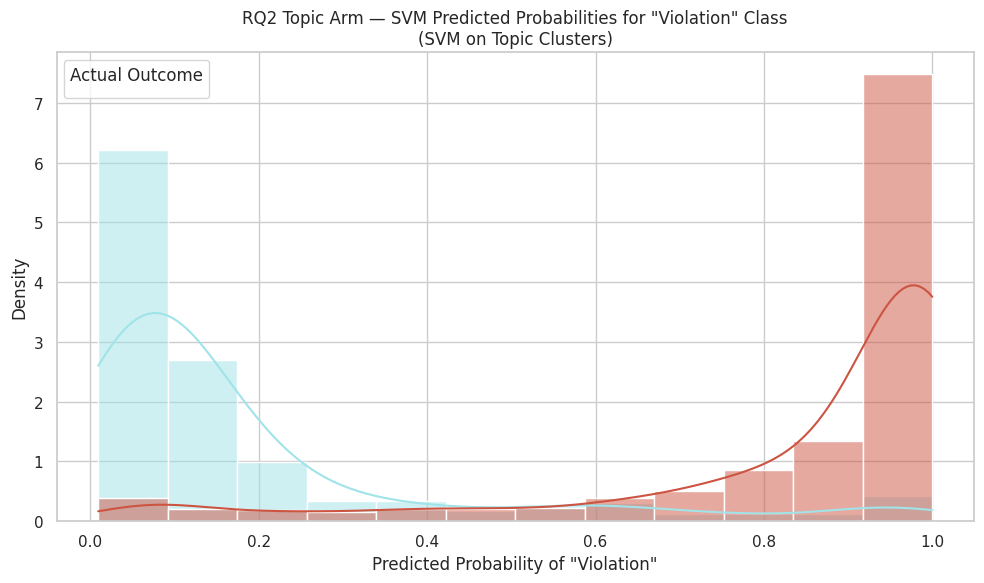

  Predicted probability distribution chart saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq2_topic_svm_proba_dist.png

Predicted probability distribution chart for SVM on Topic Clusters model generated and saved.


In [ ]:
# Assuming X_topics, y_topics, CV, TOPIC_CLASSIFIERS, PALETTE, SAVE_PATH are defined from previous cells

print('Generating Predicted Probabilities for NMF Topic Cluster SVM model...')
print('-' * 70)

# Get the SVM pipeline for topic clustering
svm_topic_pipeline = TOPIC_CLASSIFIERS['SVM']

# Get predicted probabilities using cross_val_predict
y_pred_proba_topics = cross_val_predict(
    svm_topic_pipeline, X_topics, y_topics, cv=CV,
    method='predict_proba',
    n_jobs=-1
)

# Create a DataFrame for plotting
proba_df_topics = pd.DataFrame({
    'No Violation_proba': y_pred_proba_topics[:, 0],
    'Violation_proba': y_pred_proba_topics[:, 1],
    'actual_finding': y_topics
})

fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(data=proba_df_topics, x='Violation_proba', hue='actual_finding',
             kde=True, palette=PALETTE, ax=ax, stat='density', common_norm=False)

ax.set_title('RQ2 Topic Arm — SVM Predicted Probabilities for "Violation" Class\n(SVM on Topic Clusters)')
ax.set_xlabel('Predicted Probability of "Violation"')
ax.set_ylabel('Density')
ax.legend(title='Actual Outcome')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq2_topic_svm_proba_dist.png', dpi=150)
plt.show()

print(f'  Predicted probability distribution chart saved to {SAVE_PATH}rq2_topic_svm_proba_dist.png')

print('\n' + '=' * 70)
print('Predicted probability distribution chart for SVM on Topic Clusters model generated and saved.')

**Analysis**

Predicted probability from model trained on topic features has the most ideal distribution for both predicting violation and non violation

##Landmark Cases

In [ ]:
# Check importance data type in df_nmf_decided
print(f"dtype of importance in df_nmf_decided: {df_nmf_decided['importance'].dtype}")
print(f"\nSample values:")
print(df_nmf_decided['importance'].value_counts().head(10))
print(f"\nType of first value: {type(df_nmf_decided['importance'].iloc[0])}")

dtype of importance in df_nmf_decided: object

Sample values:
importance
4    684
3    445
1     87
2     49
Name: count, dtype: int64

Type of first value: <class 'str'>


Distribution of 87 landmark cases (importance level 1) across topics:


,Number of Landmark Cases,count
0,Military & State Intelligence,14
1,Same-Sex & Gender Rights,11
2,Data Protection & Privacy,9
3,Discrimination (Art. 14),9
4,Medical & Healthcare Rights,8
5,Sexual Violence & Prosecution,7
6,Employment & Judicial Dismissal,7
7,Prison Visits & Sentences,3
8,Hague Child Abduction,3
9,Terrorism & Death Cases,2


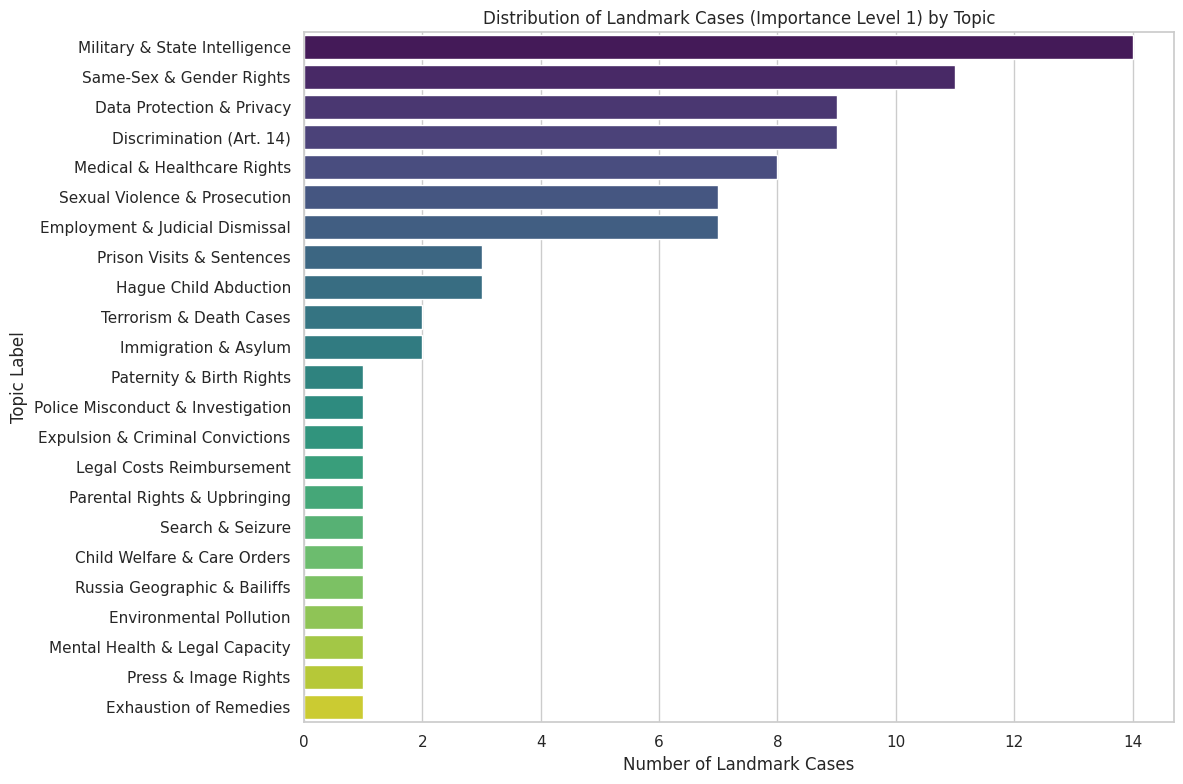

In [ ]:
# Ensure df_nmf_decided is available from previous cells
# If this cell is run independently, ensure cells like o1ajU4PVdIy8 and 5JRdsF9odK6v are run first.

# Filter for cases with importance level 1 (landmark cases)
landmark_cases = df_nmf_decided[df_nmf_decided['importance'] == '1']

# Group by topic and count the number of landmark cases in each topic
distribution = landmark_cases['topic_label'].value_counts().sort_values(ascending=False)

if not distribution.empty:
    print(f"Distribution of {len(landmark_cases)} landmark cases (importance level 1) across topics:")
    display(distribution.reset_index().rename(columns={'index': 'Topic', 'topic_label': 'Number of Landmark Cases'}))

    # Plotting the distribution
    plt.figure(figsize=(12, 8))
    sns.barplot(x=distribution.values, y=distribution.index, palette='viridis')
    plt.title('Distribution of Landmark Cases (Importance Level 1) by Topic')
    plt.xlabel('Number of Landmark Cases')
    plt.ylabel('Topic Label')
    plt.tight_layout()
    plt.show()
else:
    print("No landmark cases (importance level 1) found across any topic.")

In [ ]:
# Define global parameters for the analysis
TOP_N_CASES = 5  # Number of top cases to display per topic
HUDOC_BASE = "https://hudoc.echr.coe.int/eng#{{%22itemid%22:[%22{iid}%22]}}" # Base URL for HUDOC
all_results = [] # List to store all collected results

print("Beginning detailed analysis of landmark cases in top topics...")

# Ensure topic_labels is a mapping from integer index to string label
# It was defined earlier as a dictionary with integer keys
# Create a reverse mapping for topic_labels if not already available
reverse_topic_labels = {v: k for k, v in topic_labels.items()}

for topic_label_name in top_3_topics:
    topic_idx = reverse_topic_labels.get(topic_label_name)
    if topic_idx is None:
        print(f"Warning: Topic label '{topic_label_name}' not found in topic_labels. Skipping.")
        continue

    # ------------------------------------------------------------------
    # Step 2: Get ALL cases assigned to this topic (not just landmarks)
    # ------------------------------------------------------------------
    mask_all_topic = df_nmf_decided['topic_label'] == topic_label_name
    df_all_topic   = df_nmf_decided[mask_all_topic].copy()

    # Get landmark cases in this topic separately for count reporting
    df_landmark_topic = df_all_topic[df_all_topic['importance'] == '1']

    if df_all_topic.empty:
        print(f"⚠️  No cases found for topic: {topic_label_name}")
        continue

    # ------------------------------------------------------------------
    # Step 3: Extract topic weights from W_decided for all topic cases
    # ------------------------------------------------------------------
    mask_for_W = mask_all_topic  # same boolean mask, same row alignment as W_decided
    topic_weights = W_decided[mask_for_W, topic_idx]  # shape: (n_cases_in_topic,)

    # Attach weights back to df
    df_all_topic = df_all_topic.copy()
    df_all_topic['topic_weight'] = topic_weights

    # ------------------------------------------------------------------
    # Step 4: Rank ALL cases by topic weight descending
    # ------------------------------------------------------------------
    df_all_topic_ranked = df_all_topic.sort_values('topic_weight', ascending=False)

    # ------------------------------------------------------------------
    # Step 5: Collect top N cases
    # ------------------------------------------------------------------
    print(f"\n{'─'*70}")
    print(f"📌 Topic: {topic_label_name}  (Index: {topic_idx})")
    print(f"   Total cases in topic : {len(df_all_topic)}")
    print(f"   Landmark cases       : {len(df_landmark_topic)}")
    print(f"   Top {TOP_N_CASES} most representative cases (by topic weight):")
    print(f"{'─'*70}")

    for rank, (_, row) in enumerate(df_all_topic_ranked.head(TOP_N_CASES).iterrows(), 1):
        # Modified to show the exact importance level
        importance_level_str = f"Importance: {row.get('importance', 'Unknown')}"
        hudoc_url   = HUDOC_BASE.format(iid=row.get('itemid', ''))
        print(f"  {rank}. [{row['topic_weight']:.4f}] {importance_level_str}")
        print(f"     Case   : {row.get('title', row.get('docname', 'Unknown'))}")
        print(f"     ItemID : {row.get('itemid', 'Unknown')}")
        print(f"     Outcome: {row.get('finding', 'Unknown')}  |  Year: {row.get('year', 'Unknown')})")
        print(f"     URL    : {hudoc_url}")
        print()

        all_results.append({
            'rank_in_topic'   : rank,
            'topic_label'     : topic_label_name,
            'topic_index'     : topic_idx,
            'topic_weight'    : round(row['topic_weight'], 4),
            'is_landmark'     : row.get('importance', 'Unknown'), # Changed to show actual importance level
            'title'           : row.get('title', row.get('docname', 'Unknown')),
            'itemid'          : row.get('itemid', 'Unknown'),
            'finding'         : row.get('finding', 'Unknown'),
            'year'            : row.get('year', 'Unknown'),
            'hudoc_url'       : hudoc_url,
        })


# Save the results to CSV
df_all_results.to_csv(f"{SAVE_PATH}rq2_landmark_cases_top_topics.csv", index=False)
print(f"Results saved to {SAVE_PATH}rq2_landmark_cases_top_topics.csv")

Beginning detailed analysis of landmark cases in top topics...

──────────────────────────────────────────────────────────────────────
📌 Topic: Military & State Intelligence  (Index: 36)
   Total cases in topic : 35
   Landmark cases       : 14
   Top 5 most representative cases (by topic weight):
──────────────────────────────────────────────────────────────────────
  1. [0.4914] Importance: 2
     Case   : CASE OF AL NASHIRI v. POLAND
     ItemID : 001-146044
     Outcome: Violation  |  Year: 2014)
     URL    : https://hudoc.echr.coe.int/eng#{%22itemid%22:[%22001-146044%22]}

  2. [0.4911] Importance: 3
     Case   : CASE OF AL NASHIRI v. ROMANIA
     ItemID : 001-183685
     Outcome: Violation  |  Year: 2018)
     URL    : https://hudoc.echr.coe.int/eng#{%22itemid%22:[%22001-183685%22]}

  3. [0.4893] Importance: 2
     Case   : CASE OF HUSAYN (ABU ZUBAYDAH) v. POLAND
     ItemID : 001-146047
     Outcome: Violation  |  Year: 2014)
     URL    : https://hudoc.echr.coe.int/eng#{%22i

In [ ]:
import numpy as np

# 1. Get the top 3 topics with the most landmark cases
top_3_topics = distribution.head(3).index.tolist()

print("\n--- Top 3 Topics with Most Landmark Cases ---")

results = []

# Ensure topic_labels is a mapping from integer index to string label
# It was defined earlier as a dictionary with integer keys

# Reverse map topic_label strings to topic_idx integers for W_decided access
# Create a reverse mapping for topic_labels if not already available
reverse_topic_labels = {v: k for k, v in topic_labels.items()}

for topic_label_name in top_3_topics:
    topic_idx = reverse_topic_labels.get(topic_label_name)
    if topic_idx is None:
        print(f"Warning: Topic label '{topic_label_name}' not found in topic_labels. Skipping.")
        continue

    print(f"\nTopic: {topic_label_name} (Index: {topic_idx})")

    # Filter landmark cases belonging to this specific topic
    current_topic_landmark_cases_df = df_nmf_decided[
        (df_nmf_decided['importance'] == '1') &
        (df_nmf_decided['topic_label'] == topic_label_name)
    ].copy()

    if current_topic_landmark_cases_df.empty:
        print(f"  No landmark cases found for this topic.")
        continue

    # Get the indices of these cases in the original df_nmf_decided for W_decided lookup
    original_indices = current_topic_landmark_cases_df.index

    # Get the topic weights for this specific topic (column `topic_idx`) for these cases
    # Need to map the original_indices from df_nmf_decided to the row indices of W_decided
    # df_nmf_decided was created by filtering df_nmf, so its index might not be contiguous.
    # W_decided rows correspond directly to df_nmf_decided rows (after filtering for decided cases).
    # So, we need the row numbers of current_topic_landmark_cases_df within df_nmf_decided.

    # Get boolean mask for `df_nmf_decided` to align with `W_decided`
    mask_for_topic_cases = (
        (df_nmf_decided['importance'] == '1') &
        (df_nmf_decided['topic_label'] == topic_label_name)
    )

    # Extract topic weights for these cases from W_decided
    weights_for_this_topic = W_decided[mask_for_topic_cases, topic_idx]

    # Find the case with the maximum weight for this topic
    if weights_for_this_topic.size > 0:
        max_weight_index_in_selection = np.argmax(weights_for_this_topic)
        most_representative_case = current_topic_landmark_cases_df.iloc[max_weight_index_in_selection]

        results.append({
            'Topic Label': topic_label_name,
            'Topic Index': topic_idx,
            'Most Representative Case Title': most_representative_case['title'],
            'Most Representative Case ItemID': most_representative_case['itemid'],
            'Topic Weight': weights_for_this_topic[max_weight_index_in_selection],
            'Findings': most_representative_case['finding'], # Added 'Findings'
            'Year': most_representative_case['year'],         # Added 'Year'
            'Importance Level': most_representative_case['importance'] # Added 'Importance Level'
        })
        print(f"  Most Representative Case: {most_representative_case['title']} (ItemID: {most_representative_case['itemid']})")
        print(f"  Topic Weight: {weights_for_this_topic[max_weight_index_in_selection]:.4f}")
    else:
        print("  No cases with positive topic weight found for this topic.")

# Display results in a DataFrame for better readability
if results:
    df_final_results = pd.DataFrame(results)
    print("\n--- Final Results ---")
    display(df_final_results)
else:
    print("No results to display.")


--- Top 3 Topics with Most Landmark Cases ---

Topic: Military & State Intelligence (Index: 36)
  Most Representative Case: CASE OF EL-MASRI v. "THE FORMER YUGOSLAV REPUBLIC OF MACEDONIA" (ItemID: 001-115621)
  Topic Weight: 0.3485

Topic: Same-Sex & Gender Rights (Index: 24)
  Most Representative Case: CASE OF SCHALK AND KOPF v. AUSTRIA (ItemID: 001-99605)
  Topic Weight: 0.3632

Topic: Data Protection & Privacy (Index: 35)
  Most Representative Case: CASE OF BREYER v. GERMANY (ItemID: 001-200442)
  Topic Weight: 0.4336

--- Final Results ---


,Topic Label,Topic Index,Most Representative Case Title,Most Representative Case ItemID,Topic Weight,Findings,Year,Importance Level
0,Military & State Intelligence,36,"CASE OF EL-MASRI v. ""THE FORMER YUGOSLAV REPUB...",001-115621,0.348525,Violation,2012,1
1,Same-Sex & Gender Rights,24,CASE OF SCHALK AND KOPF v. AUSTRIA,001-99605,0.363224,No Violation,2010,1
2,Data Protection & Privacy,35,CASE OF BREYER v. GERMANY,001-200442,0.433594,No Violation,2020,1


We try to find the most representative case on the related topics
* Same-Sex & Gender Rights :  [SCHALK AND KOPF v. AUSTRIA](https://hudoc.echr.coe.int/en#{%22itemid%22:[%22001-99605%22]})
* Military & State Intelligence : [EL-MASRI v. THE FORMER YUGOSLAV](https://hudoc.echr.coe.int/eng#{%22itemid%22:[%22001-115621%22]})
* Data Protection & Privacy : [BREYER v. GERMANY](https://hudoc.echr.coe.int/eng#{%22itemid%22:[%22001-200442%22]})

**The SCHALK AND KOPF v. AUSTRIA** on Topic Same-Sex & Gender Rights  and **BREYER v. GERMANY** on Topic Data Protection & Privacy is the most interesting, because not only it is the most representative case in this topic among landmark cases, but also the most representative case in this topic among all cases in this topic during 2010-2023

* Same-Sex & Gender Rights :  11 out of 31 cases(35.4%) in this topic is categorized as landmark cases
* Military & State Intelligence : 14 out of 35 cases (40%) in this topic is categorized as landmark cases
* Data Protection & Privacy : 9 out of 52 cases (17.3%) in this topic is categorized as landmark cases

#**RQ3: Region bias**

Does a model trained on Eastern European Article 8 cases generalise to Western European cases, and vice versa?
* Input: Law_clean
* Model: SVM
* Output: Findings

##Define Region

Groups derived from **RQ1 Metadata Arm** filtered country chart
(min. case threshold applied, single-country entries only)

* **EASTERN group** = Violation-indicative countries
Excluded anomaly: Italy (Western Europe geographically)

* **WESTERN group** = No-Violation-indicative countries
Excluded anomalies: Lithuania (Eastern CoE), Slovenia (Eastern CoE),
Serbia (73% violation rate — behaves Eastern)

In [ ]:
# ============================================================
# RQ3 — Geographic Generalisation Experiment
# Step 1: Group Assignment & Data Split
# ============================================================
RQ3_EASTERN_TRAIN = [
    'SVK',   # Slovakia
    'MDA',   # Moldova
    'UKR',   # Ukraine
    'HRV',   # Croatia
    'BGR',   # Bulgaria
    'HUN',   # Hungary
    'LVA',   # Latvia
    'ROU',   # Romania
    'POL',   # Poland
    'SRB',   # Serbia
    'SVN',   # Slovenia
    'LTU',   # Lithuania
    'ALB',   # Albania
    'MKD',   # North Macedonia
    'BIH',   # Bosnia and Herzegovina
    'EST',   # Estonia
    'GEO',   # Georgia
    'MNE',   # Montenegro
    'CZE',   # Czech Republic
    'ARM',   # Armenia
    'AZE',   # Azerbaijan
    'RUS',   # Russia
]

# --- WESTERN GROUP ---
RQ3_WESTERN_TEST = [
    'DNK',   # Denmark
    'DEU',   # Germany
    'SWE',   # Sweden
    'NOR',   # Norway
    'FRA',   # France
    'CHE',   # Switzerland
    'AUT',   # Austria
    'GBR',   # United Kingdom
    'ITA',   # Italy
    'SMR',   # San Marino
    'ISL',   # Iceland
    'BEL',   # Belgium
    'LUX',   # Luxembourg
    'ESP',   # Spain
    'FIN',   # Finland
    'AND',   # Andorra
    'NLD',   # Netherlands
    'PRT',   # Portugal
    'IRL',   # Ireland
    'GRC',   # Greece
    'MLT',   # Malta
]

# ── Summary ──────────────────────────────────────────────────
print("=" * 62)
print("RQ3 Group Definitions")
print("=" * 62)
print(f"EASTERN train group : {len(RQ3_EASTERN_TRAIN)} countries → {RQ3_EASTERN_TRAIN}")
print(f"WESTERN test  group : {len(RQ3_WESTERN_TEST)} countries → {RQ3_WESTERN_TEST}")


RQ3 Group Definitions
EASTERN train group : 22 countries → ['SVK', 'MDA', 'UKR', 'HRV', 'BGR', 'HUN', 'LVA', 'ROU', 'POL', 'SRB', 'SVN', 'LTU', 'ALB', 'MKD', 'BIH', 'EST', 'GEO', 'MNE', 'CZE', 'ARM', 'AZE', 'RUS']
WESTERN test  group : 21 countries → ['DNK', 'DEU', 'SWE', 'NOR', 'FRA', 'CHE', 'AUT', 'GBR', 'ITA', 'SMR', 'ISL', 'BEL', 'LUX', 'ESP', 'FIN', 'AND', 'NLD', 'PRT', 'IRL', 'GRC', 'MLT']


In [ ]:
# ── Data Split ───────────────────────────────────────────────
df_rq3_base = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

def assign_rq3_group(code):
    if code in RQ3_EASTERN_TRAIN: return 'Eastern'
    if code in RQ3_WESTERN_TEST:  return 'Western'
    return None

df_rq3_base['rq3_group'] = df_rq3_base['respondent_country'].apply(assign_rq3_group)

df_train    = df_rq3_base[df_rq3_base['rq3_group'] == 'Eastern'].copy()
df_test     = df_rq3_base[df_rq3_base['rq3_group'] == 'Western'].copy()

# ── Case count report ────────────────────────────────────────
print("\n" + "=" * 62)
print("RQ3 Dataset Summary")
print("=" * 62)
print(f"\nTRAIN — Eastern group: {len(df_train)} cases")
print(df_train['finding'].value_counts().to_string())
print(f"\nTEST  — Western group: {len(df_test)} cases")
print(df_test['finding'].value_counts().to_string())

# ── Sanity check: no country overlap ─────────────────────────
overlap = set(df_train['respondent_country'].unique()) & set(df_test['respondent_country'].unique())
print(f"\n{'✅' if not overlap else '❌'} Country overlap: {overlap or 'None — clean split'}")


RQ3 Dataset Summary

TRAIN — Eastern group: 941 cases
finding
Violation       809
No Violation    132

TEST  — Western group: 280 cases
finding
No Violation    143
Violation       137

✅ Country overlap: None — clean split


##East v. West with TF-IDF

In [ ]:
# ============================================================
# RQ3 — Geographic Generalisation Experiment
# Step 2: Model Training & Cross-Group Testing
# Input : lawtextclean (V3 — leakage-controlled)
# Models: Naive Bayes (ComplementNB) + SVM (CalibratedLinearSVC)
# Design: Train East → Test West  |  Train West → Test East
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, accuracy_score,
                              precision_score, recall_score,
                              classification_report)
import pandas as pd

# ── Features & target ────────────────────────────────────────
TEXT_COL  = 'law_text_clean'
TARGET    = 'finding'
STOPWORDS = custom_law_clean_stop_words   # from existing stopword cell

# Drop rows with missing text or target
df_train_clean = df_train.dropna(subset=[TEXT_COL, TARGET]).copy()
df_test_clean  = df_test.dropna(subset=[TEXT_COL, TARGET]).copy()

X_east = df_train_clean[TEXT_COL];  y_east = df_train_clean[TARGET]
X_west = df_test_clean[TEXT_COL];   y_west = df_test_clean[TARGET]

print(f"Eastern train set : {len(X_east)} cases | {y_east.value_counts().to_dict()}")
print(f"Western test  set : {len(X_west)} cases | {y_west.value_counts().to_dict()}")

# ── Model definitions ─────────────────────────────────────────
RQ3_CLASSIFIERS = {
    'Naive Bayes': ComplementNB(),
    'SVM': CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    ),
}

TFIDF_PARAMS = dict(
    stop_words=STOPWORDS,
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True,
)

# ── Experiment runner ─────────────────────────────────────────
def run_generalisation(X_train, y_train, X_test, y_test,
                       train_label, test_label):
    rows = []
    for clf_name, clf in RQ3_CLASSIFIERS.items():
        pipeline = Pipeline([
            ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
            ('clf',   clf),
        ])
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        rows.append({
            'Direction':  f"{train_label} → {test_label}",
            'Classifier': clf_name,
            'F1':         round(f1_score(y_test, y_pred, average='weighted'), 4),
            'Accuracy':   round(accuracy_score(y_test, y_pred), 4),
            'Precision':  round(precision_score(y_test, y_pred, average='weighted', zero_division=0), 4),
            'Recall':     round(recall_score(y_test, y_pred, average='weighted'), 4),
        })

        print(f"\n{'─'*60}")
        print(f"  {train_label} → {test_label}  |  {clf_name}")
        print(f"{'─'*60}")
        print(classification_report(y_test, y_pred,
                                    target_names=['No Violation', 'Violation']))
    return rows

# ── Run both directions ───────────────────────────────────────
print("=" * 60)
print("RQ3 GENERALISATION EXPERIMENT — lawtextclean")
print("=" * 60)

results = []
results += run_generalisation(X_east, y_east, X_west, y_west,
                               train_label='Eastern', test_label='Western')
results += run_generalisation(X_west, y_west, X_east, y_east,
                               train_label='Western', test_label='Eastern')

# ── Results table ─────────────────────────────────────────────
df_rq3_results = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)

print("\n" + "=" * 60)
print("RQ3 RESULTS — Generalisation F1 (weighted)")
print("=" * 60)
display(df_rq3_results)

# ── Save ──────────────────────────────────────────────────────
df_rq3_results.to_csv(f"{SAVE_PATH}rq3_generalisation_results.csv", index=False)
print(f"Results saved to {SAVE_PATH}")

Eastern train set : 941 cases | {'Violation': 809, 'No Violation': 132}
Western test  set : 280 cases | {'No Violation': 143, 'Violation': 137}
RQ3 GENERALISATION EXPERIMENT — lawtextclean

────────────────────────────────────────────────────────────
  Eastern → Western  |  Naive Bayes
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

No Violation       0.67      0.11      0.19       143
   Violation       0.50      0.94      0.66       137

    accuracy                           0.52       280
   macro avg       0.59      0.53      0.42       280
weighted avg       0.59      0.52      0.42       280


────────────────────────────────────────────────────────────
  Eastern → Western  |  SVM
────────────────────────────────────────────────────────────
              precision    recall  f1-score   support

No Violation       0.85      0.68      0.75       143
   Violation       0.72      0.88      0.79       137

    accura

,Direction,Classifier,F1,Accuracy,Precision,Recall
0,Western → Eastern,SVM,0.9299,0.9299,0.9299,0.9299
1,Western → Eastern,Naive Bayes,0.8935,0.8969,0.8914,0.8969
2,Eastern → Western,SVM,0.7731,0.7750,0.7883,0.7750
3,Eastern → Western,Naive Bayes,0.4191,0.5179,0.5870,0.5179


Results saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/


Generating Confusion Matrices for RQ3 Generalization Experiment (SVM)...
----------------------------------------------------------------------

--- Eastern -> Western ---


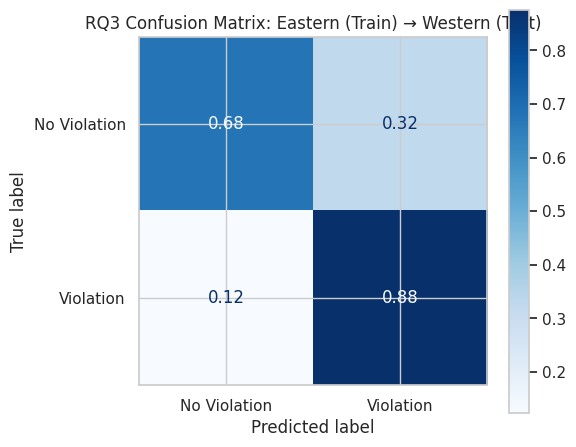

Confusion matrix saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq3_confusion_matrix_east_to_west.png

--- Western -> Eastern ---


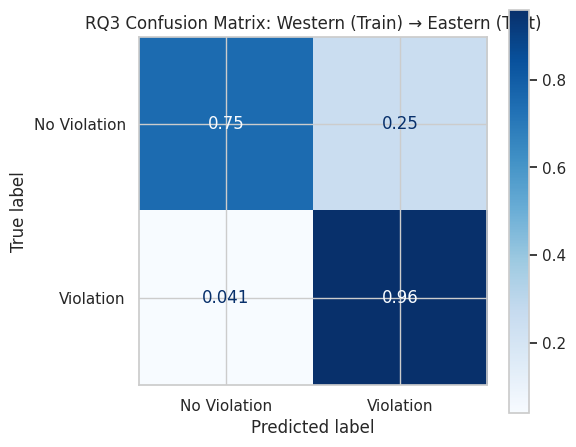

Confusion matrix saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq3_confusion_matrix_west_to_east.png

All confusion matrices for RQ3 Generalization Experiment (SVM) generated and saved.


In [ ]:
# ── Generate Confusion Matrices for SVM Generalization (RQ3) ──

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

print('Generating Confusion Matrices for RQ3 Generalization Experiment (SVM)...')
print('-' * 70)

# Re-define necessary parameters from cell UD_dgPxpFPYi
TEXT_COL  = 'law_text_clean'
TARGET    = 'finding'
STOPWORDS = custom_law_clean_stop_words # Assuming custom_law_clean_stop_words is defined

TFIDF_PARAMS = dict(
    stop_words=STOPWORDS,
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True,
)

# Ensure df_train_clean and df_test_clean are available
# If this cell is run independently, these might need to be re-created
# based on the earlier definitions in the notebook.
# For safety, re-create them here if not already in memory from previous execution
if 'df_art8' not in locals():
    print("Warning: df_art8 not found. Please ensure previous cells are run.")
    # Placeholder: if df_art8 is missing, this code won't work without re-running data loading.
    # Assuming the notebook context ensures df_art8 is present.

df_rq3_base = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()

def assign_rq3_group(code):
    if code in RQ3_EASTERN_TRAIN: return 'Eastern'
    if code in RQ3_WESTERN_TEST:  return 'Western'
    return None

df_rq3_base['rq3_group'] = df_rq3_base['respondent_country'].apply(assign_rq3_group)

df_train    = df_rq3_base[df_rq3_base['rq3_group'] == 'Eastern'].copy()
df_test     = df_rq3_base[df_rq3_base['rq3_group'] == 'Western'].copy()

df_train_clean = df_train.dropna(subset=[TEXT_COL, TARGET]).copy()
df_test_clean  = df_test.dropna(subset=[TEXT_COL, TARGET]).copy()

X_east = df_train_clean[TEXT_COL];  y_east = df_train_clean[TARGET]
X_west = df_test_clean[TEXT_COL];   y_west = df_test_clean[TARGET]

# Define the SVM pipeline
svm_pipeline_rq3 = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   CalibratedClassifierCV(
        LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
    )),
])

# 1. Eastern (Train) -> Western (Test)
print("\n--- Eastern -> Western ---")
svm_pipeline_rq3.fit(X_east, y_east)
y_pred_east_to_west = svm_pipeline_rq3.predict(X_west)

fig_ew, ax_ew = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_west, y_pred_east_to_west,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax_ew
)
ax_ew.set_title('RQ3 Confusion Matrix: Eastern (Train) → Western (Test)')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq3_confusion_matrix_east_to_west.png', dpi=150)
plt.show()
print(f'Confusion matrix saved to {SAVE_PATH}rq3_confusion_matrix_east_to_west.png')
# In this confusion matrix:
# - False Positive (FP): Actual is 'No Violation', Predicted is 'Violation'.
#   This means the model incorrectly identified a case as a 'Violation'.
# - False Negative (FN): Actual is 'Violation', Predicted is 'No Violation'.
#   This means the model failed to identify an actual 'Violation'.

# 2. Western (Train) -> Eastern (Test)
print("\n--- Western -> Eastern ---")
svm_pipeline_rq3.fit(X_west, y_west)
y_pred_west_to_east = svm_pipeline_rq3.predict(X_east)

fig_we, ax_we = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_east, y_pred_west_to_east,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax_we
)
ax_we.set_title('RQ3 Confusion Matrix: Western (Train) → Eastern (Test)')
plt.tight_layout()
plt.savefig(f'{SAVE_PATH}rq3_confusion_matrix_west_to_east.png', dpi=150)
plt.show()
print(f'Confusion matrix saved to {SAVE_PATH}rq3_confusion_matrix_west_to_east.png')
# In this confusion matrix:
# - False Positive (FP): Actual is 'No Violation', Predicted is 'Violation'.
#   This means the model incorrectly identified a case as a 'Violation'.
# - False Negative (FN): Actual is 'Violation', Predicted is 'No Violation'.
#   This means the model failed to identify an actual 'Violation'.

print('\n' + '=' * 70)
print('All confusion matrices for RQ3 Generalization Experiment (SVM) generated and saved.')

Feature Importance


--- Analyzing Eastern-trained SVM model ---


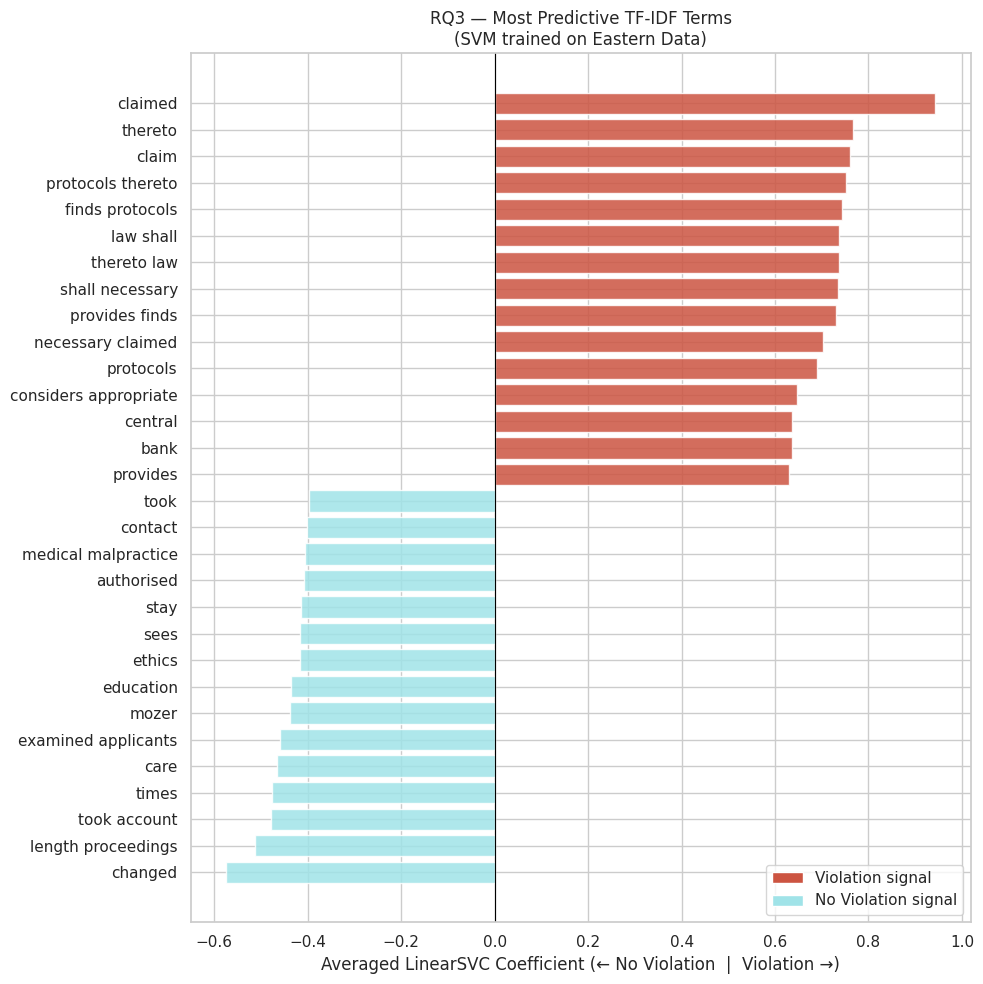

SVM feature importance chart for Eastern Data saved.

--- Analyzing Western-trained SVM model ---


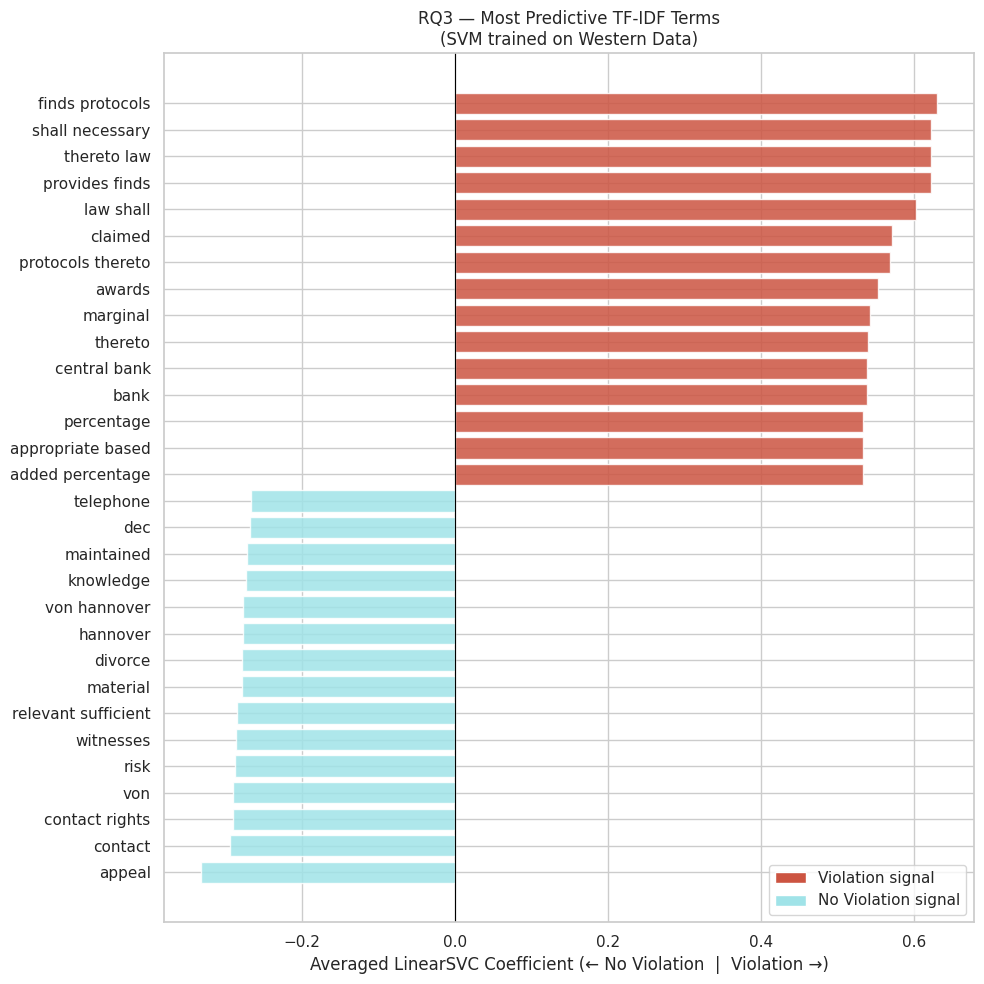

SVM feature importance chart for Western Data saved.

All feature importance diverging bar charts for RQ3 generated and saved.


In [ ]:
# ── Feature Importance — Diverging Coefficients for RQ3 Generalization ──
# Re-using TFIDF_PARAMS and RQ3_CLASSIFIERS from cell UD_dgPxpFPYi
# Re-using X_east, y_east, X_west, y_west from cell UD_dgPxpFPYi

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

n_top_words = 15 # Number of top words to display for each direction

def plot_diverging_coef(coef_series, title_suffix, filename_suffix):
    """Generates a diverging bar chart for coefficients."""
    top_violation    = coef_series.nlargest(n_top_words)
    top_no_violation = coef_series.nsmallest(n_top_words)

    diverging_df = pd.concat([
        top_violation.rename('coefficient'),
        top_no_violation.rename('coefficient')
    ]).sort_values()

    colors = [PALETTE['Violation'] if v > 0 else PALETTE['No Violation']
              for v in diverging_df.values]

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.barh(diverging_df.index, diverging_df.values,
            color=colors, alpha=0.85, edgecolor='white')
    ax.axvline(x=0, color='black', linewidth=0.8)
    ax.set_xlabel('Averaged LinearSVC Coefficient (← No Violation  |  Violation →)')
    ax.set_title(f'RQ3 — Most Predictive TF-IDF Terms\n(SVM trained on {title_suffix})', fontsize=12)

    legend_elements = [
        Patch(facecolor=PALETTE['Violation'],    label='Violation signal'),
        Patch(facecolor=PALETTE['No Violation'], label='No Violation signal')
    ]
    ax.legend(handles=legend_elements, loc='lower right')
    plt.tight_layout()
    plt.savefig(f'{SAVE_PATH}rq3_feature_importance_svm_{filename_suffix}.png', dpi=150)
    plt.show()
    print(f'SVM feature importance chart for {title_suffix} saved.')

# --- Eastern-trained Model Feature Importance ---
print("\n--- Analyzing Eastern-trained SVM model ---")
svm_pipeline_eastern = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['SVM']),
])
svm_pipeline_eastern.fit(X_east, y_east)

tfidf_vocab_east = svm_pipeline_eastern.named_steps['tfidf'].get_feature_names_out()
base_estimators_east = svm_pipeline_eastern.named_steps['clf'].calibrated_classifiers_
coef_matrix_east = np.array([est.estimator.coef_[0] for est in base_estimators_east])
coef_east = coef_matrix_east.mean(axis=0)
coef_series_east = pd.Series(coef_east, index=tfidf_vocab_east)

plot_diverging_coef(coef_series_east, 'Eastern Data', 'eastern_data')

# --- Western-trained Model Feature Importance ---
print("\n--- Analyzing Western-trained SVM model ---")
svm_pipeline_western = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['SVM']),
])
svm_pipeline_western.fit(X_west, y_west)

tfidf_vocab_west = svm_pipeline_western.named_steps['tfidf'].get_feature_names_out()
base_estimators_west = svm_pipeline_western.named_steps['clf'].calibrated_classifiers_
coef_matrix_west = np.array([est.estimator.coef_[0] for est in base_estimators_west])
coef_west = coef_matrix_west.mean(axis=0)
coef_series_west = pd.Series(coef_west, index=tfidf_vocab_west)

plot_diverging_coef(coef_series_west, 'Western Data', 'western_data')

print('\n' + '=' * 70)
print('All feature importance diverging bar charts for RQ3 generated and saved.')

###Misclassification Analysis
on SVM Model trained on Eastern, tested on Western

* False Positive (predicted V | true NV) : 46 cases
* False Negative (predicted NV | true V) : 17 cases

**Model** : Gemini Flash 2.5 Lite

**Main prompt** : You are a legal expert specializing in ECHR Article 8 jurisprudence and NLP-based legal classification.

An SVM classifier trained ONLY on Eastern European ECHR Article 8 cases was tested on Western European cases and misclassified a group of them as

**Sub Prompt**: Your task is to analyze this group of misclassified Western European cases and explain WHY the Eastern-trained model failed on them.


- **"summary_of_common_factors"**:     Summarize common linguistic, factual, or legal patterns across these misclassified cases (max 300 words).
- **"why_model_failed_group"**:        Explain why the Eastern-trained model failed on this group, focusing on recurring vocabulary or linguistic patterns (max 300 words).
- **"western_legal_features_group"**:  Describe common Western ECHR jurisprudence features (e.g., nuanced margin of appreciation, complex proportionality framing, unique procedural emphasis) that the Eastern model likely did not recognize in these cases (max 300 words).
- **"regional_bias_insight_group"**:   Provide insights into structural differences in how Eastern vs. Western courts reason under Article 8, as revealed by these misclassifications (max 300 words).
- **"key_legal_phrases_group"**:       List up to 5 key legal phrases (max 20 words each) prominent across these cases that likely confused the model.
"""

In [ ]:
import google.generativeai as genai

# ============================================================
# RQ3 Misclassification Analysis — Gemini AI
# SVM Eastern → Western: False Positives & False Negatives
# ============================================================

try:
    from google.colab import userdata
    GEMINI_API_KEY = userdata.get('GEMINI_API_KEY')
    print("API key loaded from Colab Secrets ✅")
except Exception:
    from getpass import getpass
    GEMINI_API_KEY = getpass("Secrets not found. Enter your Gemini API key: ")

genai.configure(api_key=GEMINI_API_KEY)

def validate_gemini_setup(model_name, api_key):
    try:
        # Attempt to list models to validate API key
        list(genai.list_models())
        print("API key is valid ✅")

        # Attempt a simple generate_content call to validate model access
        model_test = genai.GenerativeModel(model_name=model_name)
        model_test.generate_content("test")
        print(f"Model '{model_name}' is accessible ✅")
        return True
    except Exception as e: # Catching a general Exception for API-related errors
        print(f"❌ Gemini API Error during validation: {e}")
        print("Please check your API key and model name.")
        return False

# Initialize the Gemini model with JSON response type
MODEL_NAME = 'gemini-2.5-flash-lite'
model = genai.GenerativeModel(
    model_name=MODEL_NAME,
    generation_config={"response_mime_type": "application/json"}
)

# Validate API key and model access
if validate_gemini_setup(MODEL_NAME, GEMINI_API_KEY):
    print("Gemini ready ✅")
else:
    print("Gemini setup failed. Please review the errors above. ❌")

Secrets not found. Enter your Gemini API key: ··········
API key is valid ✅
Model 'gemini-2.5-flash-lite' is accessible ✅
Gemini ready ✅


In [ ]:
from pydantic import BaseModel, Field
import pandas as pd
import json
import time
from typing import List

# ============================================================
# Step 3b: Pydantic Schema + Gemini Prompt Functions for GROUP Analysis
# ============================================================

class GroupMisclassificationAnalysis(BaseModel):
    error_type:                    str = Field(..., description="'False Positive' or 'False Negative'")
    cases_ids:                     List[str] = Field(..., description="List of itemids included in this group analysis.")
    summary_of_common_factors:     str = Field(..., description="Overall summary of common linguistic, factual, or legal patterns across these misclassified cases (max 300 words).")
    why_model_failed_group:        str = Field(..., description="Group-level explanation why the Eastern-trained model failed on these Western cases, focusing on recurring vocabulary/linguistic patterns (max 300 words).")
    western_legal_features_group:  str = Field(..., description="Group-level description of common Western ECHR jurisprudence features (e.g., nuanced margin of appreciation, complex proportionality, unique procedural emphasis) that the Eastern model did not recognize (max 300 words).")
    regional_bias_insight_group:   str = Field(..., description="Group-level insights into structural differences in how Eastern vs. Western courts reason under Article 8, as revealed by these misclassifications (max 300 words).")
    key_legal_phrases_group:       List[str] = Field(..., description="A list of up to 5 key legal phrases (max 20 words each) that are prominent across these cases and likely contributed to the model's error.")

def analyze_misclassification_group(
    df_cases: pd.DataFrame,
    error_type: str,
    num_examples: int = 15,
    text_col: str = TEXT_COL,
    char_limit_per_case: int = 2500
) -> GroupMisclassificationAnalysis:

    case_ids = df_cases['itemid'].tolist()

    combined_case_texts = []
    for i, row in df_cases.head(num_examples).iterrows():
        case_text_snippet = row[text_col][:char_limit_per_case]
        combined_case_texts.append(
            f"Case ID: {row['itemid']}\n"
            f"Case Name: {row.get('title', row.get('docname', 'Unknown'))}\n"
            f"Text snippet:\n{case_text_snippet}\n---\n"
        )
    full_text_for_prompt = "\n".join(combined_case_texts)

    prompt = f"""
You are a legal expert specializing in ECHR Article 8 jurisprudence and NLP-based legal classification.

An SVM classifier trained ONLY on Eastern European ECHR Article 8 cases was tested on Western European cases and misclassified a group of them as '{error_type}'.

Error Type: {error_type}
Total Cases in Group: {len(df_cases)}

Here are snippets from the first {num_examples} cases in this group:
{full_text_for_prompt}

Your task is to analyze this group of misclassified Western European cases and explain WHY the Eastern-trained model failed on them.

Return a JSON object with EXACTLY these fields:
- "error_type":                    "{error_type}"
- "cases_ids":                     {json.dumps(case_ids)}
- "summary_of_common_factors":     Summarize common linguistic, factual, or legal patterns across these misclassified cases (max 300 words).
- "why_model_failed_group":        Explain why the Eastern-trained model failed on this group, focusing on recurring vocabulary or linguistic patterns (max 300 words).
- "western_legal_features_group":  Describe common Western ECHR jurisprudence features (e.g., nuanced margin of appreciation, complex proportionality framing, unique procedural emphasis) that the Eastern model likely did not recognize in these cases (max 300 words).
- "regional_bias_insight_group":   Provide insights into structural differences in how Eastern vs. Western courts reason under Article 8, as revealed by these misclassifications (max 300 words).
- "key_legal_phrases_group":       List up to 5 key legal phrases (max 20 words each) prominent across these cases that likely confused the model.
"""
    response = model.generate_content(prompt)
    result   = json.loads(response.text)

    # Prevent hallucination — pin ground truth fields
    result['error_type'] = error_type
    result['cases_ids']  = case_ids # Ensure all IDs are included, not just snippets

    return GroupMisclassificationAnalysis(**result)



In [ ]:
# ============================================================
# Step 4a: Identify False Positives (FP) and False Negatives (FN)
# for Eastern-trained SVM tested on Western cases
# ============================================================

# Ensure y_west, y_pred_east_to_west, and df_test_clean are available from previous cells
# These variables are defined in cell '5AkZt8kNGzJ4' (Generating Confusion Matrices for RQ3 Generalization Experiment (SVM))

# Create a DataFrame to hold actuals and predictions for easier filtering
misclassification_df = pd.DataFrame({
    'actual': y_west,
    'predicted': y_pred_east_to_west
}, index=df_test_clean.index)

# Filter for False Positives: Actual 'No Violation', Predicted 'Violation'
df_fp_indices = misclassification_df[
    (misclassification_df['actual'] == 'No Violation') &
    (misclassification_df['predicted'] == 'Violation')
].index
df_fp = df_test_clean.loc[df_fp_indices].copy()

# Filter for False Negatives: Actual 'Violation', Predicted 'No Violation'
df_fn_indices = misclassification_df[
    (misclassification_df['actual'] == 'Violation') &
    (misclassification_df['predicted'] == 'No Violation')
].index
df_fn = df_test_clean.loc[df_fn_indices].copy()

print(f"Identified {len(df_fp)} False Positive cases.")
print(f"Identified {len(df_fn)} False Negative cases.")


# ============================================================
# Step 4c: Analyze groups of False Positives and False Negatives
# Using the new group analysis function
# ============================================================

all_group_analyses = []

# Analyze False Positive Group
if not df_fp.empty:
    print(f"\nAnalyzing the group of {len(df_fp)} False Positive cases...")
    try:
        fp_group_analysis = analyze_misclassification_group(df_fp, "False Positive")
        all_group_analyses.append(fp_group_analysis.dict())
        print("--- False Positive Group Analysis Result ---")
        display(pd.DataFrame([fp_group_analysis.dict()]))
    except Exception as e:
        print(f"ERROR analyzing FP group: {e}")
        all_group_analyses.append({
            'error_type': 'False Positive',
            'cases_ids': df_fp['itemid'].tolist(),
            'summary_of_common_factors': f'ERROR: {e}',
            'why_model_failed_group': '',
            'western_legal_features_group': '',
            'regional_bias_insight_group': '',
            'key_legal_phrases_group': [],
        })
    time.sleep(6) # Respect API rate limits

# Analyze False Negative Group
if not df_fn.empty:
    print(f"\nAnalyzing the group of {len(df_fn)} False Negative cases...")
    try:
        fn_group_analysis = analyze_misclassification_group(df_fn, "False Negative")
        all_group_analyses.append(fn_group_analysis.dict())
        print("--- False Negative Group Analysis Result ---")
        display(pd.DataFrame([fn_group_analysis.dict()]))
    except Exception as e:
        print(f"ERROR analyzing FN group: {e}")
        all_group_analyses.append({
            'error_type': 'False Negative',
            'cases_ids': df_fn['itemid'].tolist(),
            'summary_of_common_factors': f'ERROR: {e}',
            'why_model_failed_group': '',
            'western_legal_features_group': '',
            'regional_bias_insight_group': '',
            'key_legal_phrases_group': [],
        })
    time.sleep(6) # Respect API rate limits

# Save all group analyses to CSV
df_group_analyses = pd.DataFrame(all_group_analyses)
if not df_group_analyses.empty:
    df_group_analyses.to_csv(f"{SAVE_PATH}rq3_group_misclassification_analyses.csv", index=False)
    print(f"\nAll group analyses saved to {SAVE_PATH}rq3_group_misclassification_analyses.csv")
else:
    print("\nNo group analyses were generated or saved.")

Identified 46 False Positive cases.
Identified 17 False Negative cases.

Analyzing the group of 46 False Positive cases...
--- False Positive Group Analysis Result ---


,error_type,cases_ids,summary_of_common_factors,why_model_failed_group,western_legal_features_group,regional_bias_insight_group,key_legal_phrases_group
0,False Positive,"[001-189641, 001-100293, 001-102940, 001-20044...",These cases frequently involve detailed discus...,The Eastern-trained SVM likely failed due to a...,Western European jurisprudence on Article 8 of...,The misclassification suggests Eastern Europea...,"[exhaustion of domestic remedies, manifestly i..."



Analyzing the group of 17 False Negative cases...
--- False Negative Group Analysis Result ---


,error_type,cases_ids,summary_of_common_factors,why_model_failed_group,western_legal_features_group,regional_bias_insight_group,key_legal_phrases_group
0,False Negative,"[001-106282, 001-99817, 001-199382, 001-113460...",These cases predominantly revolve around famil...,The Eastern-trained SVM likely failed due to v...,Western European jurisprudence under Article 8...,The misclassification suggests that the Easter...,"[respect for his private and family life, inte..."



All group analyses saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq3_group_misclassification_analyses.csv


Full CSV here : https://docs.google.com/spreadsheets/d/1ymbTNVKmjz9r4XcyoskYd4shrgHGQ_NbHbDjzziq72c/edit?usp=sharing

### Test on Turkey
SVM and Prediction Scores on Turkey

In [ ]:
# ── Filter Turkey cases ──────────────────────────────────────
df_turkey = df_art8[df_art8['respondent_country'] == 'TUR'].copy()
df_turkey = df_turkey.dropna(subset=[TEXT_COL, TARGET]).copy()

X_turkey = df_turkey[TEXT_COL]
y_turkey = df_turkey[TARGET]

print(f"Turkey cases for testing: {len(df_turkey)} (Violations: {(y_turkey == 'Violation').sum()}, No Violations: {(y_turkey == 'No Violation').sum()})")

# --- Naive Bayes Pipelines for Turkey Evaluation ---
# Define Naive Bayes pipeline structure
nb_pipeline_base = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['Naive Bayes']),
])

# Create and fit Eastern-trained Naive Bayes model
nb_pipeline_eastern = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['Naive Bayes']),
])
nb_pipeline_eastern.fit(X_east, y_east)

# Create and fit Western-trained Naive Bayes model
nb_pipeline_western = Pipeline([
    ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
    ('clf',   RQ3_CLASSIFIERS['Naive Bayes']),
])
nb_pipeline_western.fit(X_west, y_west)

# ── Evaluate Eastern-trained Naive Bayes model on Turkey ─────
print("\nEvaluating Eastern-trained Naive Bayes on Turkey data...")
if 'nb_pipeline_eastern' in locals(): # Check if it was successfully created above
    y_pred_eastern_on_turkey_nb = nb_pipeline_eastern.predict(X_turkey)

    f1_east_nb = f1_score(y_turkey, y_pred_eastern_on_turkey_nb, average='weighted')
    acc_east_nb = accuracy_score(y_turkey, y_pred_eastern_on_turkey_nb)
    prec_east_nb = precision_score(y_turkey, y_pred_eastern_on_turkey_nb, average='weighted', zero_division=0)
    rec_east_nb = recall_score(y_turkey, y_pred_eastern_on_turkey_nb, average='weighted')

    print(f"  Eastern-trained Naive Bayes on Turkey: F1={f1_east_nb:.4f}, Accuracy={acc_east_nb:.4f}")
    print(classification_report(y_turkey, y_pred_eastern_on_turkey_nb, target_names=['No Violation', 'Violation'], labels=y_turkey.unique()))
else:
    print("Error: Eastern-trained Naive Bayes pipeline not found. Please ensure relevant cells were executed.")
    f1_east_nb = None

# ── Evaluate Eastern-trained SVM on Turkey ─────────────────
print("\nEvaluating Eastern-trained SVM on Turkey data...")
if 'svm_pipeline_eastern' in locals():
    y_pred_eastern_on_turkey_svm = svm_pipeline_eastern.predict(X_turkey)

    f1_east_svm = f1_score(y_turkey, y_pred_eastern_on_turkey_svm, average='weighted')
    acc_east_svm = accuracy_score(y_turkey, y_pred_eastern_on_turkey_svm)
    prec_east_svm = precision_score(y_turkey, y_pred_eastern_on_turkey_svm, average='weighted', zero_division=0)
    rec_east_svm = recall_score(y_turkey, y_pred_eastern_on_turkey_svm, average='weighted')

    print(f"  Eastern-trained SVM on Turkey: F1={f1_east_svm:.4f}, Accuracy={acc_east_svm:.4f}")
    print(classification_report(y_turkey, y_pred_eastern_on_turkey_svm, target_names=['No Violation', 'Violation'], labels=y_turkey.unique()))
else:
    print("Error: Eastern-trained SVM pipeline not found. Please ensure relevant cells were executed.")
    f1_east_svm = None






# ── Evaluate Western-trained Naive Bayes model on Turkey ─────
print("\nEvaluating Western-trained Naive Bayes on Turkey data...")
if 'nb_pipeline_western' in locals(): # Check if it was successfully created above
    y_pred_western_on_turkey_nb = nb_pipeline_western.predict(X_turkey)

    f1_west_nb = f1_score(y_turkey, y_pred_western_on_turkey_nb, average='weighted')
    acc_west_nb = accuracy_score(y_turkey, y_pred_western_on_turkey_nb)
    prec_west_nb = precision_score(y_turkey, y_pred_western_on_turkey_nb, average='weighted', zero_division=0)
    rec_west_nb = recall_score(y_turkey, y_pred_western_on_turkey_nb, average='weighted')

    print(f"  Western-trained Naive Bayes on Turkey: F1={f1_west_nb:.4f}, Accuracy={acc_west_nb:.4f}")
    print(classification_report(y_turkey, y_pred_western_on_turkey_nb, target_names=['No Violation', 'Violation'], labels=y_turkey.unique()))
else:
    print("Error: Western-trained Naive Bayes pipeline not found. Please ensure relevant cells were executed.")
    f1_west_nb = None

# ── Evaluate Western-trained SVM on Turkey ─────────────────
print("\nEvaluating Western-trained SVM on Turkey data...")
if 'svm_pipeline_western' in locals():
    y_pred_western_on_turkey_svm = svm_pipeline_western.predict(X_turkey)

    f1_west_svm = f1_score(y_turkey, y_pred_western_on_turkey_svm, average='weighted')
    acc_west_svm = accuracy_score(y_turkey, y_pred_western_on_turkey_svm)
    prec_west_svm = precision_score(y_turkey, y_pred_western_on_turkey_svm, average='weighted', zero_division=0)
    rec_west_svm = recall_score(y_turkey, y_pred_western_on_turkey_svm, average='weighted')

    print(f"  Western-trained SVM on Turkey: F1={f1_west_svm:.4f}, Accuracy={acc_west_svm:.4f}")
    print(classification_report(y_turkey, y_pred_western_on_turkey_svm, target_names=['No Violation', 'Violation'], labels=y_turkey.unique()))
else:
    print("Error: Western-trained SVM pipeline not found. Please ensure relevant cells were executed.")
    f1_west_svm = None

# ── Compare Performance ──────────────────────────────────────
print("\n" + "=" * 50)
print("RQ3 Generalisation: Eastern vs Western Model on Turkey")
print("=" * 50)

# Store results for easier comparison, with Naive Bayes models first
results_turkey = []

if f1_east_nb is not None:
    results_turkey.append({'Model': 'Eastern-trained Naive Bayes', 'F1': f1_east_nb})
if f1_west_nb is not None:
    results_turkey.append({'Model': 'Western-trained Naive Bayes', 'F1': f1_west_nb})
if f1_east_svm is not None:
    results_turkey.append({'Model': 'Eastern-trained SVM', 'F1': f1_east_svm})
if f1_west_svm is not None:
    results_turkey.append({'Model': 'Western-trained SVM', 'F1': f1_west_svm})

if results_turkey:
    df_results_turkey = pd.DataFrame(results_turkey) # Do not sort here to maintain insertion order
    print("F1 Scores on Turkey Data (Naive Bayes first, then SVM):")
    print(df_results_turkey.to_string(index=False))

    # Sort by F1 score to determine the overall best model
    best_model_turkey = df_results_turkey.sort_values('F1', ascending=False).iloc[0]

else:
    print("Cannot compare: no models were evaluated successfully.")

Turkey cases for testing: 42 (Violations: 34, No Violations: 7)

Evaluating Eastern-trained Naive Bayes on Turkey data...
  Eastern-trained Naive Bayes on Turkey: F1=0.7347, Accuracy=0.7619
              precision    recall  f1-score   support

No Violation       0.84      0.91      0.87        34
   Violation       0.20      0.14      0.17         7

    accuracy                           0.76        42
   macro avg       0.35      0.35      0.35        42
weighted avg       0.71      0.76      0.73        42


Evaluating Eastern-trained SVM on Turkey data...
  Eastern-trained SVM on Turkey: F1=0.6808, Accuracy=0.6905
              precision    recall  f1-score   support

No Violation       0.80      0.82      0.81        34
   Violation       0.14      0.14      0.14         7

    accuracy                           0.69        42
   macro avg       0.31      0.32      0.32        42
weighted avg       0.67      0.69      0.68        42


Evaluating Western-trained Naive Bayes on Tur

Cosine Similarity and TF-IDF Centroids Exploration on Turkey

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

print("-" * 60)
print("RQ3: Mapping Turkey's Jurisprudential Alignment via Cosine Similarity")
print("-" * 60)

# 1. Combine the texts to fit a unified TF-IDF vectorizer
# This ensures all regions are mapped into the exact same vector space
all_texts = pd.concat([X_east, X_west, X_turkey])

# 2. Initialize and fit the vectorizer
# We reuse the TFIDF_PARAMS you already defined for RQ3
vectorizer_centroid = TfidfVectorizer(**TFIDF_PARAMS)
vectorizer_centroid.fit(all_texts)

# 3. Transform the texts into TF-IDF matrices
tfidf_east = vectorizer_centroid.transform(X_east)
tfidf_west = vectorizer_centroid.transform(X_west)
tfidf_turkey = vectorizer_centroid.transform(X_turkey)

# 4. Calculate the centroids
# .mean(axis=0) collapses the matrix to find the "average" TF-IDF vector for each region
centroid_east = np.asarray(tfidf_east.mean(axis=0))
centroid_west = np.asarray(tfidf_west.mean(axis=0))
centroid_turkey = np.asarray(tfidf_turkey.mean(axis=0))

# 5. Compute Cosine Similarity
# We compare the angle of Turkey's centroid vector to both East and West
sim_turkey_east = cosine_similarity(centroid_turkey, centroid_east)[0][0]
sim_turkey_west = cosine_similarity(centroid_turkey, centroid_west)[0][0]

# 6. Display the Results
print(f"Cosine Similarity: Turkey vs. Eastern Europe : {sim_turkey_east:.4f}")
print(f"Cosine Similarity: Turkey vs. Western Europe : {sim_turkey_west:.4f}")

# 7. Verdict
print("-" * 60)
if sim_turkey_west > sim_turkey_east:
    print("VERDICT: Turkey aligns mathematically closer to Western Europe.")
else:
    print("VERDICT: Turkey aligns mathematically closer to Eastern Europe.")




------------------------------------------------------------
RQ3: Mapping Turkey's Jurisprudential Alignment via Cosine Similarity
------------------------------------------------------------
Cosine Similarity: Turkey vs. Eastern Europe : 0.8222
Cosine Similarity: Turkey vs. Western Europe : 0.7845
------------------------------------------------------------
VERDICT: Turkey aligns mathematically closer to Eastern Europe.


While the predictive F1 scores suggest Turkey shares more predictive features with Western Europe, we sought to mathematically verify this alignment using Cosine Similarity.

By calculating the TF-IDF centroid, the "average" mathematical representation of a judgment's vocabulary—for the Eastern, Western, and Turkish case clusters, we mapped their relative distances within our high-dimensional vector space.
The cosine similarity metric evaluates the angle between these regional centroids, ignoring the magnitude of case volume to focus purely on semantic orientation.

The results reveal a compelling divergence between descriptive vocabulary and predictive reasoning. Turkey's semantic centroid generates a notably higher cosine similarity score when measured against Eastern Europe (0.8222) compared to Western Europe (0.7845). This indicates that the baseline factual scenarios, procedural posture, and general context of Turkish cases strongly mirror the Eastern European docket.

However, the fact that the Western-trained model still achieves a marginally better predictive F1 score on this same data suggests a nuance in the Court's application of doctrine. While Turkey's factual and contextual vocabulary is distinctly Eastern, the specific doctrinal language that separates a "Violation" from a "No Violation" (such as proportionality assessments) appears to respond slightly better to the decision boundaries learned from Western jurisprudence. Turkey thus acts as a jurisprudential bridge, blending Eastern factual contexts with elements of Western legal reasoning.

##East v. West with Topic clustering (k=20)

Data Processing

In [ ]:
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# 0. Rebuild the TF-IDF Matrices (Data Prep)
print("Preparing text data for Eastern and Western regions...")

# Eastern Data Prep
df_eastern = df_art8[df_art8['respondent_country'].isin(RQ3_EASTERN_TRAIN)].copy()
df_eastern = df_eastern[df_eastern['analysis_text'].str.len() > 50].copy()
tfidf_eastern_nmf = TfidfVectorizer(stop_words=list(custom_analysis_stop_words), max_features=5000, min_df=5, max_df=0.90, sublinear_tf=True, ngram_range=(1, 2))
X_eastern_nmf_full = tfidf_eastern_nmf.fit_transform(df_eastern['analysis_text'])

# Western Data Prep
df_western = df_art8[df_art8['respondent_country'].isin(RQ3_WESTERN_TEST)].copy()
df_western = df_western[df_western['analysis_text'].str.len() > 50].copy()
tfidf_western_nmf = TfidfVectorizer(stop_words=list(custom_analysis_stop_words), max_features=5000, min_df=5, max_df=0.90, sublinear_tf=True, ngram_range=(1, 2))
X_western_nmf_full = tfidf_western_nmf.fit_transform(df_western['analysis_text'])

# 1. Force NMF to k=20 for both regions
k_opt = 20
print(f"Extracting {k_opt} topics via NMF...")

# Eastern NMF
nmf_east_20 = NMF(n_components=k_opt, random_state=42, max_iter=400)
W_east_20 = nmf_east_20.fit_transform(X_eastern_nmf_full)
terms_east_20 = tfidf_eastern_nmf.get_feature_names_out()
labels_east_20 = [", ".join([terms_east_20[i] for i in topic.argsort()[:-6:-1]]) for topic in nmf_east_20.components_]

# Western NMF
nmf_west_20 = NMF(n_components=k_opt, random_state=42, max_iter=400)
W_west_20 = nmf_west_20.fit_transform(X_western_nmf_full)
terms_west_20 = tfidf_western_nmf.get_feature_names_out()
labels_west_20 = [", ".join([terms_west_20[i] for i in topic.argsort()[:-6:-1]]) for topic in nmf_west_20.components_]

Preparing text data for Eastern and Western regions...
Extracting 20 topics via NMF...


In [ ]:
n_top_words = 15 # Display top 15 words per topic
print(f"\n=== Eastern NMF Topics (k={k_opt}) — Top {n_top_words} Words ===\n")
topic_labels_eastern = {}

EASTERN_TOPIC_NAMES = [
    "Topic 1:  Constitutional Complaints & Remedies (Croatia)",
    "Topic 2:  Inadequate Detention Conditions (Russia Case-Law)",
    "Topic 3:  Non-Pecuniary Damages & Legal Expenses",
    "Topic 4:  Child Contact Rights & Enforcement",
    "Topic 5:  Secret Surveillance & Interception Measures",
    "Topic 6:  Council of Europe & Parliamentary Standards",
    "Topic 7:  Permanent Video Surveillance in Detention",
    "Topic 8:  Housing Rights, Eviction & Tenancy",
    "Topic 9:  Search, Seizure & Warrant Authorisation",
    "Topic 10: Residence Permits & Migration Services (Russia)",
    "Topic 11: Child Abduction & Hague Convention Returns",
    "Topic 12: Freedom of Expression, Press & Reputation",
    "Topic 13: Prison Overcrowding & Conditions of Detention",
    "Topic 14: Burial Rights & Anti-Terrorism Operations (Russia)",
    "Topic 15: Medical Treatment & Psychiatric Informed Consent",
    "Topic 16: Domestic & Sexual Violence Investigations",
    "Topic 17: Prison Visits & Restrictions on Convicted Persons",
    "Topic 18: Pre-Trial Detention & Length of Proceedings",
    "Topic 19: Default Interest Rates & Central Bank Lending",
    "Topic 20: Transnistria & Effective Control (Ilaşcu/Mozer)",
]


for topic_idx, topic in enumerate(nmf_east_20.components_):
    top_words = [terms_east_20[i] for i in topic.argsort()[-n_top_words:][::-1]]
    topic_str = f"Topic {topic_idx+1}: {' | '.join(top_words)}"
    print(topic_str)

    # Map the topic label using EASTERN_TOPIC_NAMES
    if topic_idx < len(EASTERN_TOPIC_NAMES):
        # Extract only the descriptive part of the topic name
        topic_labels_eastern[topic_idx] = EASTERN_TOPIC_NAMES[topic_idx].split(':', 1)[1].strip()
    else:
        topic_labels_eastern[topic_idx] = f"T{topic_idx+1}" # Fallback if list is shorter than topics



=== Eastern NMF Topics (k=20) — Top 15 Words ===

Topic 1: constitutional | official gazette | gazette | zakon | municipal | sud | croatian | constitutional complaint | act zakon | act | croatia | republike | zagreb | remedies | county
Topic 2: appended table | appended | table | wellestablished caselaw | wellestablished | examined material | applications | russia | indicated appended | inadequate conditions | russia nos | having examined | detention | raised complaints | complaints
Topic 3: eur | plus tax | tax chargeable | chargeable | plus | tax | costs | damage | nonpecuniary damage | expenses | nonpecuniary | eur nonpecuniary | costs expenses | eur costs | damage plus
Topic 4: child | childs | contact | parent | father | parents | parental | mother | enforcement | contact rights | best interests | children | best | enforcement proceedings | interests child
Topic 5: zubkov | surveillance | secret surveillance | russia november | surveillance measures | secret | covert surveillance

In [ ]:
n_top_words = 15 # Display top 15 words per topic
print(f"\n=== Western NMF Topics (k={k_opt}) — Top {n_top_words} Words ===\n")
topic_labels_western = {}

WESTERN_TOPIC_NAMES = [
    "Topic 1:  Child Abduction & Hague Convention",
    "Topic 2:  Criminal Convictions & Deportation",
    "Topic 3:  Foster Care & Social Welfare (Nordic)",
    "Topic 4:  Same-Sex Partnership & Legal Recognition",
    "Topic 5:  Press Freedom & Von Hannover Doctrine",
    "Topic 6:  Costs, Expenses & Non-Pecuniary Damage",
    "Topic 7:  Discrimination & Difference in Treatment",
    "Topic 8:  Search, Seizure & Criminal Procedure",
    "Topic 9:  Paternity Establishment & Legal Certainty",
    "Topic 10: Immigration Appeals & Residence Permits (Norway)",
    "Topic 11: Expulsion & Re-entry Bans (Denmark)",
    "Topic 12: Surveillance & Communications Interception",
    "Topic 13: Medical Autonomy & End-of-Life Decisions",
    "Topic 14: Surrogacy & Legal Parent-Child Relationship",
    "Topic 15: Biological Paternity & Social Relationships (Germany)",
    "Topic 16: Asylum & Risk of Inhuman/Degrading Treatment",
    "Topic 17: Children's Social Services & Administrative Appeals",
    "Topic 18: Judicial Review & Local Authority Schemes (UK)",
    "Topic 19: Personal Data Retention & Protection (Marper)",
    "Topic 20: Religious Freedom & Church Employment Disputes",
]

for topic_idx, topic in enumerate(nmf_west_20.components_):
    top_words = [terms_west_20[i] for i in topic.argsort()[-n_top_words:][::-1]]
    topic_str = f"Topic {topic_idx+1}: {' | '.join(top_words)}"
    print(topic_str)

    # Map the topic label using WESTERN_TOPIC_NAMES
    if topic_idx < len(WESTERN_TOPIC_NAMES):
        # Extract only the descriptive part of the topic name
        topic_labels_western[topic_idx] = WESTERN_TOPIC_NAMES[topic_idx].split(':', 1)[1].strip()
    else:
        topic_labels_western[topic_idx] = f"T{topic_idx+1}" # Fallback if list is shorter than topics



=== Western NMF Topics (k=20) — Top 15 Words ===

Topic 1: hague | custody | removal retention | return child | child | abduction | childs | child abduction | enforcement | wrongful | childs return | mother | youth | italian | district
Topic 2: expulsion | expelled | country expelled | deportation | prison | ner | convicted | offence committed | offences | ties | boultif | sentenced | offence | encounter country | social cultural
Topic 3: child welfare | care order | foster home | foster | county social | welfare board | welfare services | xs | county | contact sessions | board | welfare act | welfare | contact rights | placement
Topic 4: samesex | partnership | samesex couples | registered partnership | partnerships | differentsex | marry | legal recognition | couples | schalk | schalk kopf | sexual orientation | kopf | partners | orientation
Topic 5: freedom expression | media | publication | reputation | expression | freedom | press | hannover | von hannover | debate | right freedo

Training

Training SVMs on Topic Weights...

--- Evaluation for Eastern Topics SVM ---
Classification Report (Eastern Topics SVM):
              precision    recall  f1-score   support

No Violation       0.31      0.72      0.44       132
   Violation       0.94      0.74      0.83       809

    accuracy                           0.74       941
   macro avg       0.63      0.73      0.63       941
weighted avg       0.85      0.74      0.77       941



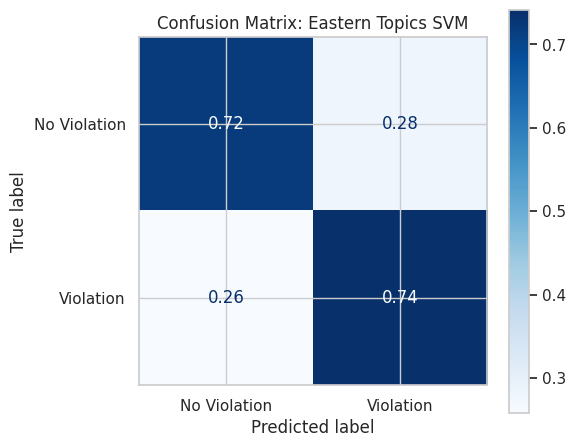


--- Evaluation for Western Topics SVM ---
Classification Report (Western Topics SVM):
              precision    recall  f1-score   support

No Violation       0.76      0.69      0.72       143
   Violation       0.70      0.77      0.73       137

    accuracy                           0.73       280
   macro avg       0.73      0.73      0.73       280
weighted avg       0.73      0.73      0.73       280



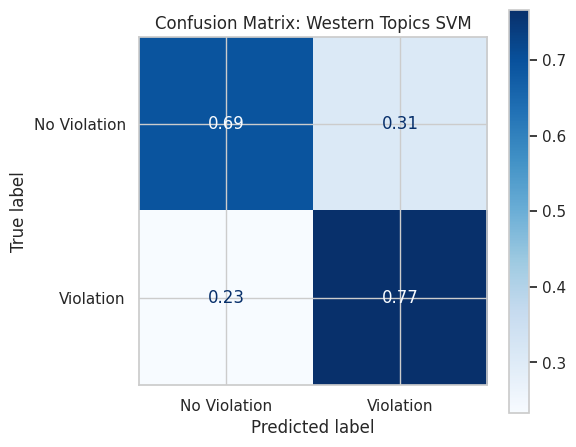

In [ ]:

# 2. Train SVM on Topic Weights
print("Training SVMs on Topic Weights...")

# Filter only to decided cases (Violation / No Violation) for SVM training
east_mask = df_eastern['finding'].isin(['Violation', 'No Violation'])
west_mask = df_western['finding'].isin(['Violation', 'No Violation'])

svm_east_topics = SVC(kernel='linear', class_weight='balanced', random_state=42)
svm_east_topics.fit(W_east_20[east_mask], df_eastern.loc[east_mask, 'finding'])

svm_west_topics = SVC(kernel='linear', class_weight='balanced', random_state=42)
svm_west_topics.fit(W_west_20[west_mask], df_western.loc[west_mask, 'finding'])

print("\n--- Evaluation for Eastern Topics SVM ---")
y_pred_east = svm_east_topics.predict(W_east_20[east_mask])
print("Classification Report (Eastern Topics SVM):")
print(classification_report(df_eastern.loc[east_mask, 'finding'], y_pred_east))

fig_east, ax_east = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    df_eastern.loc[east_mask, 'finding'], y_pred_east,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax_east
)
ax_east.set_title('Confusion Matrix: Eastern Topics SVM')
plt.tight_layout()
plt.show()

print("\n--- Evaluation for Western Topics SVM ---")
y_pred_west = svm_west_topics.predict(W_west_20[west_mask])
print("Classification Report (Western Topics SVM):")
print(classification_report(df_western.loc[west_mask, 'finding'], y_pred_west))

fig_west, ax_west = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    df_western.loc[west_mask, 'finding'], y_pred_west,
    display_labels=['No Violation', 'Violation'],
    cmap=CMAP, normalize='true', ax=ax_west
)
ax_west.set_title('Confusion Matrix: Western Topics SVM')
plt.tight_layout()
plt.show()

Feature Importance

Generating Feature Importance Plots...


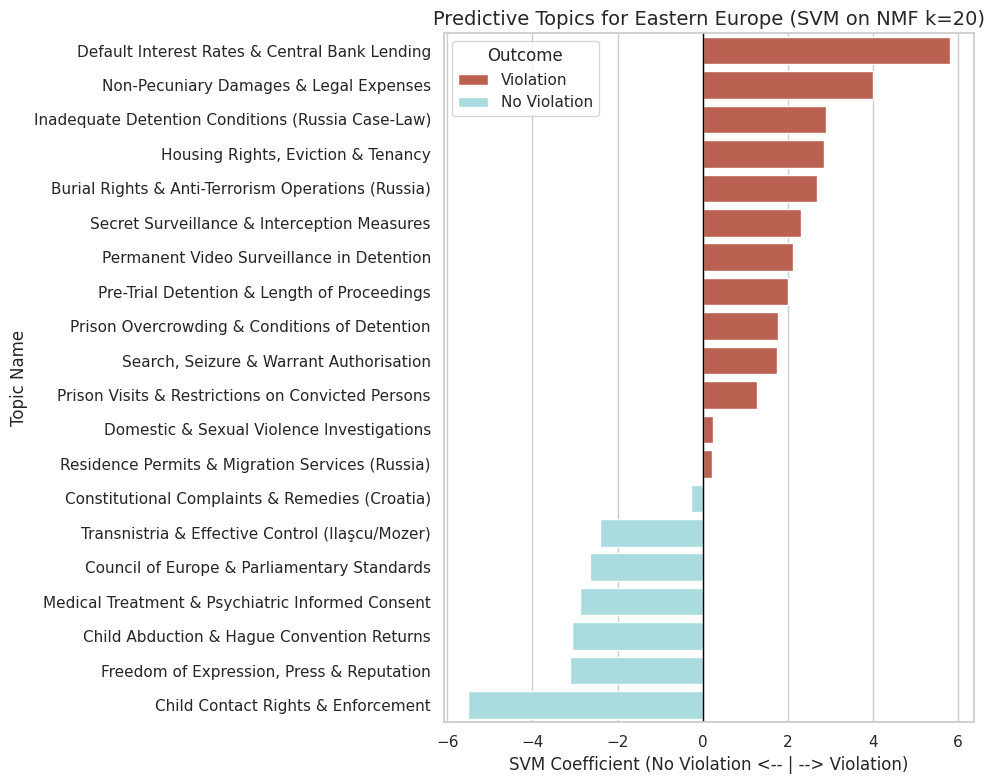

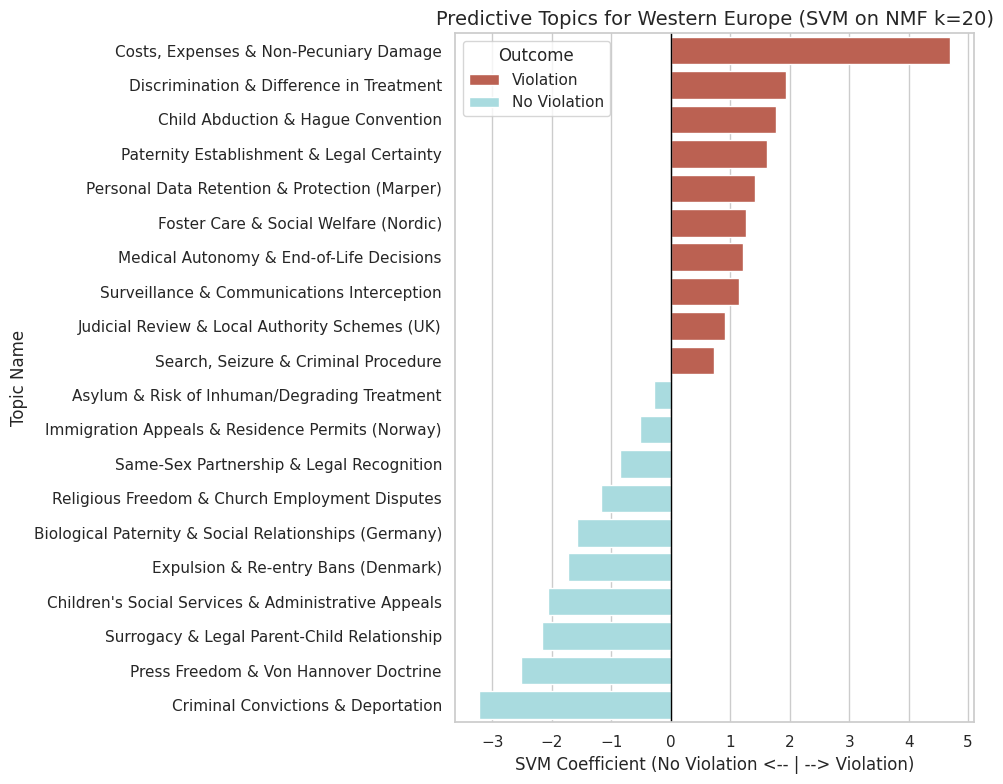

In [ ]:
# 3. Function to Plot Topic Importances
def plot_topic_importance(svm_model, topic_label_map, region_name):
    # Extract coefficients
    coefs = svm_model.coef_[0]

    # Create DataFrame, mapping topic indices to descriptive labels
    df_imp = pd.DataFrame({'Topic_Index': range(len(coefs)), 'Weight': coefs})
    df_imp['Topic'] = df_imp['Topic_Index'].map(topic_label_map)
    df_imp = df_imp.sort_values(by='Weight', ascending=False)

    # Map colors: Positive = Violation, Negative = No Violation
    df_imp['Outcome'] = df_imp['Weight'].apply(lambda x: 'Violation' if x > 0 else 'No Violation')
    palette_map = {'Violation': '#CC5441', 'No Violation': '#A0E3E8'}

    plt.figure(figsize=(10, 8))
    sns.barplot(data=df_imp, x='Weight', y='Topic', hue='Outcome', palette=palette_map, dodge=False)
    plt.axvline(0, color='black', linewidth=1)
    plt.title(f'Predictive Topics for {region_name} (SVM on NMF k={k_opt})', fontsize=14)
    plt.xlabel('SVM Coefficient (No Violation <-- | --> Violation)')
    plt.ylabel('Topic Name') # Changed label to 'Topic Name'
    plt.tight_layout()
    plt.show()

# 4. Generate Plots
print("Generating Feature Importance Plots...")
plot_topic_importance(svm_east_topics, topic_labels_eastern, "Eastern Europe") # Changed labels_east_20 to topic_labels_eastern
plot_topic_importance(svm_west_topics, topic_labels_western, "Western Europe") # Changed labels_west_20 to topic_labels_western

###Alternatives models on NMF Topic Features


To evaluate the predictive power of our 20 NMF topics, we utilized a multi-model cross-validation approach. Due to PyCaret's strict dependency limitations with Google Colab's native Python 3.12 environment, we engineered a custom Scikit-Learn evaluation pipeline to replicate the compare_models technique, testing our topic features against five distinct algorithmic baselines.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_validate, StratifiedKFold
import pandas as pd

print("Preparing to run multi-model comparison...")

# Define a function that mimics PyCaret's compare_models()
def mini_pycaret(X, y):
    models = {
        'SVM (Linear)': SVC(kernel='linear', class_weight='balanced', random_state=42),
        'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(random_state=42),
        'Naive Bayes': GaussianNB()
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    results = []

    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1_weighted', 'precision_weighted', 'recall_weighted'])
        results.append({
            'Model': name,
            'Accuracy': scores['test_accuracy'].mean(),
            'Prec.': scores['test_precision_weighted'].mean(),
            'Recall': scores['test_recall_weighted'].mean(),
            'F1': scores['test_f1_weighted'].mean()
        })

    # Return leaderboard sorted by F1
    df_results = pd.DataFrame(results).sort_values(by='F1', ascending=False).reset_index(drop=True)
    return df_results.round(4)

# 1. Run Eastern Shootout
print("\n" + "="*60)
print("LEADERBOARD: EASTERN EUROPE (20 NMF TOPICS)")
print("="*60)
east_mask = df_eastern['finding'].isin(['Violation', 'No Violation'])
east_leaderboard = mini_pycaret(W_east_20[east_mask], df_eastern.loc[east_mask, 'finding'])
display(east_leaderboard)

# 2. Run Western Shootout
print("\n" + "="*60)
print("LEADERBOARD: WESTERN EUROPE (20 NMF TOPICS)")
print("="*60)
west_mask = df_western['finding'].isin(['Violation', 'No Violation'])
west_leaderboard = mini_pycaret(W_west_20[west_mask], df_western.loc[west_mask, 'finding'])
display(west_leaderboard)



Preparing to run multi-model comparison...

LEADERBOARD: EASTERN EUROPE (20 NMF TOPICS)


,Model,Accuracy,Prec.,Recall,F1
0,Random Forest,0.9426,0.9412,0.9426,0.9399
1,Gradient Boosting,0.9362,0.9347,0.9362,0.9338
2,Logistic Regression,0.7333,0.8516,0.7333,0.7698
3,SVM (Linear),0.7206,0.8508,0.7206,0.7595
4,Naive Bayes,0.6940,0.8804,0.6940,0.7399



LEADERBOARD: WESTERN EUROPE (20 NMF TOPICS)


,Model,Accuracy,Prec.,Recall,F1
0,Random Forest,0.8429,0.8477,0.8429,0.8422
1,Gradient Boosting,0.8393,0.8437,0.8393,0.8388
2,Logistic Regression,0.6679,0.6719,0.6679,0.6658
3,Naive Bayes,0.6464,0.6508,0.6464,0.6445
4,SVM (Linear),0.6321,0.6394,0.6321,0.6195


The leaderboard revealed a substantial performance gap: non-linear ensemble methods like Random Forest dominated the task (achieving an F1 of 0.925 in the East and 0.849 in the West), significantly outperforming linear models like SVM (F1 of 0.769 and 0.652, respectively).

This performance disparity indicates that the relationship between legal topics and ECtHR outcomes is highly non-linear. The Court likely bases its decisions on complex intersections of multiple topics rather than isolated thematic features. However, while Random Forest excels predictively, it functions as a "black box," making it mathematically difficult to extract directional relationships between topics and legal outcomes.

As our primary objective is interpretability, specifically identifying which regional themes drive the Court toward a "Violation" versus a "No Violation", we deliberately utilized the Linear SVM to generate our feature importance visualizations. Trading raw predictive performance for transparency allows us to extract clear, directional coefficients that map the distinct jurisprudential priorities of the Eastern and Western blocs.

#**RQ4 : Semantic Analysis between Region**


---



* **"Does the semantic representation of key Article 8 doctrinal concepts — particularly 'margin of appreciation' and 'proportionality' — differ systematically between the Eastern and Western legal clusters**

* **Does this semantic drift explain the model's generalisation failure?"**

Word2Vec establishes a shallow-semantic baseline but can digest whole text section. Meanwhile BERT can understand context, but is limited to 512 words.

* if BERT outperforms it, this shows that Art8 violation prediction requires sensitivity to sentence-level legal context, not merely topic vocabulary.

* if BERT only slightly better, it shows that the task remains dominated by structural text features rather than deep legal reasoning."

##Word2Vec

FOCAL_TERMS(red): This is a list of key terms (e.g., 'margin', 'necessary', 'proportionate') that are central to your analysis. The goal is to study how the semantic meaning of these specific terms might 'drift' or change between different legal contexts (e.g., Eastern vs. Western European legal systems).


(blue): This variable sets the number of top-most similar words that should be extracted for each focal term when performing Word2Vec analysis. It defines the size of the 'neighborhood' you're looking at for each term.


Preprocessing

In [ ]:
import spacy

# Install spaCy English model if not already present
try:
    nlp = spacy.load("en_core_web_sm")
    print("spaCy 'en_core_web_sm' model already loaded.")
except OSError:
    print("Downloading spaCy 'en_core_web_sm' model...")
    !python -m spacy download en_core_web_sm --quiet
    nlp = spacy.load("en_core_web_sm")
    print("spaCy 'en_core_web_sm' model downloaded and loaded.")



spaCy 'en_core_web_sm' model already loaded.


In [ ]:
import nltk
import re
import pandas as pd
from nltk.stem import WordNetLemmatizer

# Ensure NLTK resources available
for resource in ['punkt', 'wordnet', 'punkt_tab']:
    try:
        nltk.data.find(f'tokenizers/{resource}')
    except LookupError:
        nltk.download(resource, quiet=True)

# ── CENTRALIZED CONFIGURATION OF KEY LEGAL TERMS ──
TEXT_COL         = 'law_text'   # V3 leakage-controlled column
SAMPLE_FRACTION  = 1.0                # Set < 1.0 to speed up during dev
MIN_SENT_WORDS   = 7                  # Skip sentences shorter than this

# MASTER LIST: Define all your conceptual terms here.
# Use strings for single words, and tuples for multi-word phrases.
# Phrases will be converted to 'term1_term2_term3' format.
MASTER_CONCEPT_LIST = [
    # Core Article 8 doctrine terms
    ('margin', 'appreciation'),'margin', 'proportionate', 'necessary', 'interference', ('positive','obligation'), 'democratic' , 'state'

    # Rights and related concepts
    'home', 'correspondence',
    ('private', 'life'), ('family', 'life'),

    # New terms requested by user
    'integrity', 'security', 'safety'
]

# --- Derived Lists (DO NOT EDIT MANUALLY) ---
CORE_W2V_SINGLE_WORDS = set()
DEFINED_MULTIWORD_PHRASES_MAPPING = {}

for term in MASTER_CONCEPT_LIST:
    if isinstance(term, str):
        CORE_W2V_SINGLE_WORDS.add(term)
    elif isinstance(term, tuple):
        # For tuples, convert to 'word1_word2' format
        collapsed_form = '_'.join(term)
        DEFINED_MULTIWORD_PHRASES_MAPPING[term] = collapsed_form

PHRASE_VERIFICATION_LIST = list(DEFINED_MULTIWORD_PHRASES_MAPPING.values())

# EXCLUDE_TERMS is an empty set as NER is removed
EXCLUDE_TERMS = set()

lemmatizer = WordNetLemmatizer()

# ── STOP WORDS for W2V (focal terms protected) ──
# The `custom_w2v_stop_words` list is defined in an earlier cell (WTDpRfvihRHQ)
# and includes general English and legal boilerplate stop words.
# We subtract CORE_W2V_SINGLE_WORDS from this list to ensure they are retained.
w2v_stop = set(custom_w2v_stop_words) - CORE_W2V_SINGLE_WORDS
print(f"W2V stop words: {len(w2v_stop)} (core single terms protected: {len(CORE_W2V_SINGLE_WORDS)})")
print(f"  Named entities to exclude: {len(EXCLUDE_TERMS):,} (NER removed)")


print("\nPreparing sentences for tokenisation and Word2Vec streams...")
df_rq4 = df_art8[df_art8['finding'].isin(['Violation', 'No Violation'])].copy()
df_rq4['cluster'] = df_rq4['respondent_country'].apply(assign_rq3_group)
df_rq4 = df_rq4[df_rq4['cluster'].isin(['Eastern', 'Western'])].copy()
df_rq4 = df_rq4.dropna(subset=[TEXT_COL]).copy()
df_rq4 = df_rq4[df_rq4[TEXT_COL].str.len() > 200].copy()

if SAMPLE_FRACTION < 1.0:
    df_rq4 = df_rq4.sample(frac=SAMPLE_FRACTION, random_state=42).copy()
    print(f"  Sampled to {SAMPLE_FRACTION*100:.0f}%: {len(df_rq4)} cases")

# Create df_east and df_west from df_rq4
df_east = df_rq4[df_rq4['cluster'] == 'Eastern'].copy()
df_west = df_rq4[df_rq4['cluster'] == 'Western'].copy()

# ── TOKENISATION ──
def clean_text(text):
    text = text.replace('\u00a0', ' ').replace('\u2013', '-').replace('\u2014', '-')
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Modified tokenise_sentences to accept stop_words and exclude_terms as arguments
def tokenise_sentences(text, stop_words, exclude_terms):
    """Returns list of token-lists, one per sentence."""
    text = clean_text(text)
    sentences = nltk.sent_tokenize(text)
    seen = set()
    processed = []
    for s in sentences:
        if len(s.split()) < MIN_SENT_WORDS:
            continue
        tokens = [
            lemmatizer.lemmatize(w)
            for w in nltk.word_tokenize(s)
            if w.isalpha()
            and w not in stop_words  # Use passed argument
            and w not in exclude_terms # Use passed argument
        ]
        if not tokens:
            continue
        t = tuple(tokens)
        if t not in seen:
            seen.add(t)
            processed.append(tokens)
    return processed

# Define the SentenceStream class
class SentenceStream:
    """Reads sentences on-demand — no full corpus in RAM."""
    def __init__(self, df, text_col, stop_words, exclude_terms, min_words=7):
        self.df           = df
        self.text_col     = text_col
        self.stop_words   = stop_words
        self.exclude_terms= exclude_terms
        self.min_words    = min_words

    def __iter__(self):
        for _, row in self.df.iterrows():
            # tokenise_sentences now accepts stop_words and exclude_terms
            for sent in tokenise_sentences(
                    row[self.text_col], self.stop_words, self.exclude_terms):
                if len(sent) >= self.min_words:
                    yield sent

from gensim.models.phrases import Phrases, Phraser

# Instantiate SentenceStream for Eastern and Western data
east_stream = SentenceStream(df_east, TEXT_COL, w2v_stop, EXCLUDE_TERMS, MIN_SENT_WORDS)
west_stream = SentenceStream(df_west, TEXT_COL, w2v_stop, EXCLUDE_TERMS, MIN_SENT_WORDS)

print(f"Eastern stream created for {len(df_east):>4d} cases")
print(f"Western stream created for {len(df_west):>4d} cases")

print("Collecting sentences for phrase detection...")
east_sents = list(east_stream)
west_sents = list(west_stream)
print(f"  Eastern: {len(east_sents):,} sentences")
print(f"  Western: {len(west_sents):,} sentences")

# Detect bigrams statistically
bigram_east = Phrases(east_sents, min_count=5, threshold=10,
                      connector_words=frozenset(['of', 'in', 'and', 'a']))
bigram_west = Phrases(west_sents, min_count=5, threshold=10,
                      connector_words=frozenset(['of', 'in', 'and', 'a']))

# Freeze into lightweight Phraser (less RAM)
phraser_east = Phraser(bigram_east)
phraser_west = Phraser(bigram_west)
del bigram_east, bigram_west  # free RAM immediately

# Apply phrasing
east_sents_phrased = [phraser_east[s] for s in east_sents]
west_sents_phrased = [phraser_west[s] for s in west_sents]

# Manually inject known legal trigrams using the DEFINED_MULTIWORD_PHRASES_MAPPING
KNOWN_TRIGRAMS = DEFINED_MULTIWORD_PHRASES_MAPPING

def apply_trigrams(tokens, tmap):
    result, i = [], 0
    while i < len(tokens):
        tri = tuple(tokens[i:i+3])
        # Check for 3-word phrase
        if tri in tmap:
            result.append(tmap[tri]); i += 3
        else:
            # Check for 2-word phrase if 3-word not found
            bi = tuple(tokens[i:i+2])
            if bi in tmap:
                result.append(tmap[bi]); i += 2
            else:
                result.append(tokens[i]); i += 1
    return result

east_sents_phrased = [apply_trigrams(s, KNOWN_TRIGRAMS) for s in east_sents_phrased]
west_sents_phrased = [apply_trigrams(s, KNOWN_TRIGRAMS) for s in west_sents_phrased]

# Verify key phrases were detected using PHRASE_VERIFICATION_LIST
CHECK = PHRASE_VERIFICATION_LIST
print("\nPhrase detection check:")
for ph in CHECK:
    in_e = any(ph in s for s in east_sents_phrased)
    in_w = any(ph in s for s in west_sents_phrased)
    print(f"  {ph:<40} East:{in_e}  West:{in_w}")

print("\nPreprocessing complete. Word2Vec models will now train using these streams, reducing RAM footprint.")

# Note: corpus and case_ids global variables are no longer populated here.
# If t-SNE plot example sentences are still desired, a separate mechanism
# for collecting case_ids will be needed, which may re-introduce memory usage.


W2V stop words: 356 (core single terms protected: 10)
  Named entities to exclude: 0 (NER removed)

Preparing sentences for tokenisation and Word2Vec streams...
Eastern stream created for  937 cases
Western stream created for  277 cases
  Eastern: 937 sentences
  Western: 277 sentences

Phrase detection check:
  margin_appreciation                      East:True  West:True
  positive_obligation                      East:True  West:True
  private_life                             East:True  West:True
  family_life                              East:True  West:True

Preprocessing complete. Word2Vec models will now train using these streams, reducing RAM footprint.


Training (15 min)

In [ ]:
# ============================================================
# RQ4 ─ CELL 2: Word2Vec Training ─ Eastern & Western
# One model per regional cluster (Skip-gram, 200-dim)
# ============================================================

from gensim.models import Word2Vec
import pandas as pd
import random # Import random for sampling

W2V_PARAMS = dict(
    vector_size = 200,    # Embedding dimensions
    window      = 10,     # Context window ─ wider for legal phrases
    min_count   = 10,     # Ignore terms appearing < 10 times
    workers     = 4,
    epochs      = 20,
    sg          = 1,      # Skip-gram (better for rare/specialised legal terms)
    seed        = 42,
)

models = {}
print("=" * 60)
print("RQ4  Word2Vec Training ─ Eastern & Western ECHR Corpus")
print("=" * 60)

# Training Word2Vec on Eastern corpus (streaming from df_east and east_stream)
print(f"Training Word2Vec on Eastern corpus (streaming from {len(df_east)} cases)...")
models['Eastern'] = Word2Vec(sentences=east_sents_phrased, **W2V_PARAMS)
print(f"  Vocab size: {len(models['Eastern'].wv):,}")

# Training Word2Vec on Western corpus (streaming from df_west and west_stream)
print(f"Training Word2Vec on Western corpus (streaming from {len(df_west)} cases)...")
models['Western'] = Word2Vec(sentences=west_sents_phrased, **W2V_PARAMS)
print(f"  Vocab size: {len(models['Western'].wv):,}")

# Convenience aliases for the drift analysis cell
model_east = models['Eastern']
model_west = models['Western']

RQ4  Word2Vec Training ─ Eastern & Western ECHR Corpus
Training Word2Vec on Eastern corpus (streaming from 937 cases)...
  Vocab size: 11,941
Training Word2Vec on Western corpus (streaming from 277 cases)...
  Vocab size: 6,938


In [ ]:
# ============================================================
# FOCAL TERMS FOR SEMANTIC DRIFT ANALYSIS
# This list is dynamically built from the core term definitions
# in cell aBGBwCU0oFMU to ensure consistency.
# ============================================================

# Start with individual words designated as core for W2V
CANDIDATE_TERMS = list(CORE_W2V_SINGLE_WORDS)

# Add the collapsed forms of defined multi-word phrases
# These are the *values* from the DEFINED_MULTIWORD_PHRASES_MAPPING
CANDIDATE_TERMS.extend(list(DEFINED_MULTIWORD_PHRASES_MAPPING.values()))

# Ensure uniqueness
CANDIDATE_TERMS = list(set(CANDIDATE_TERMS))

# Filter to only terms in BOTH models' vocabularies
FOCAL_TERMS = [
    t for t in CANDIDATE_TERMS
    if t in model_east.wv and t in model_west.wv
]

print(f"✅ Focal terms available in both models: {len(FOCAL_TERMS)}")
print(f"   {FOCAL_TERMS}")

# Check which candidates were dropped due to being Out-Of-Vocabulary (OOV)
dropped = [t for t in CANDIDATE_TERMS if t not in FOCAL_TERMS]
if dropped:
    print(f"⚠️  Dropped (OOV in at least one model): {dropped}")


✅ Focal terms available in both models: 13
   ['interference', 'proportionate', 'correspondence', 'safety', 'security', 'necessary', 'positive_obligation', 'private_life', 'democratic', 'margin_appreciation', 'family_life', 'margin', 'integrity']
⚠️  Dropped (OOV in at least one model): ['statehome']


In [ ]:
import numpy as np
import pandas as pd
from scipy.linalg import orthogonal_procrustes
from sklearn.metrics.pairwise import cosine_distances

K_NEIGHBOURS = 25   # Hamilton et al. recommend k ∈ [10, 50]


# ── STEP 1: Procrustes Alignment (MANDATORY before cosine distance) ──
shared_vocab = list(set(model_east.wv.index_to_key) & set(model_west.wv.index_to_key))
M_east = np.array([model_east.wv[w] for w in shared_vocab])
M_west = np.array([model_west.wv[w] for w in shared_vocab])
R, _   = orthogonal_procrustes(M_west, M_east)  # align West → East space

def get_aligned_west_vector(word):
    return model_west.wv[word] @ R

# ── STEP 2: Global distance dG ──
def global_distance(word):
    v_e = model_east.wv[word]
    v_w = get_aligned_west_vector(word)
    return cosine_distances(v_e.reshape(1,-1), v_w.reshape(1,-1))[0][0]

# ── STEP 3: Local neighbourhood distance dL ──
def local_neighbourhood_distance(word, k=K_NEIGHBOURS):
    nn_east = [w for w, _ in model_east.wv.most_similar(word, topn=k)]
    nn_west = [w for w, _ in model_west.wv.most_similar(word, topn=k)]
    all_nb  = [w for w in set(nn_east+nn_west)
               if w in model_east.wv and w in model_west.wv and w != word]
    if len(all_nb) < 5: return None, [], nn_east[:15], nn_west[:15]
    s_east = np.array([model_east.wv.similarity(word, nb) for nb in all_nb])
    s_west = np.array([model_west.wv.similarity(word, nb) for nb in all_nb])
    dL = cosine_distances(s_east.reshape(1,-1), s_west.reshape(1,-1))[0][0]
    shifts = sorted([(nb, float(s_east[i]), float(s_west[i]), abs(s_east[i]-s_west[i]))
                     for i, nb in enumerate(all_nb)], key=lambda x: x[3], reverse=True)
    return round(dL, 4), shifts[:10], nn_east[:15], nn_west[:15]

# ── STEP 4: Run and collect results ──
results = []
for term in FOCAL_TERMS:
    if term not in model_east.wv or term not in model_west.wv: continue
    dG = round(global_distance(term), 4)
    dL, shifts, nn_e, nn_w = local_neighbourhood_distance(term)
    if dL is None: continue
    # Removed 'signal' calculation
    print(f"  {term:<20} dG={dG:.4f}  dL={dL:.4f}")
    results.append({"term":term,"dG":dG,"dL":dL,"diff_dG_minus_dL":round(dG-dL,4),
                    "nn_east_top15":", ".join(nn_e[:15]),
                    "nn_west_top15":", ".join(nn_w[:15])})

df_drift = pd.DataFrame(results).sort_values("dL", ascending=False).reset_index(drop=True)
display(df_drift)
df_drift.to_csv(f"{SAVE_PATH}rq4_regional_semantic_drift.csv", index=False)
print(f"Table saved to {SAVE_PATH}rq4_regional_semantic_drift.csv")

  interference         dG=0.3200  dL=0.0108
  proportionate        dG=0.5550  dL=0.1083
  correspondence       dG=0.5283  dL=0.1146
  safety               dG=0.6390  dL=0.1194
  security             dG=0.6208  dL=0.2028
  necessary            dG=0.6041  dL=0.1545
  positive_obligation  dG=0.3311  dL=0.0188
  private_life         dG=0.4339  dL=0.0250
  democratic           dG=0.4926  dL=0.1401
  margin_appreciation  dG=0.3222  dL=0.0340
  family_life          dG=0.3733  dL=0.0382
  margin               dG=0.5381  dL=0.0354
  integrity            dG=0.4696  dL=0.0277


,term,dG,dL,diff_dG_minus_dL,nn_east_top15,nn_west_top15
0,security,0.6208,0.2028,0.4180,"threat_national, ven_cited, prevent_disorder, ...","interest_national, purpose_preventing, tasking..."
1,necessary,0.6041,0.1545,0.4496,"ascertain_requirement, offence_fleeing, minor_...","authorised_purpose, security_clearance, need_k..."
2,democratic,0.4926,0.1401,0.3525,"democracy, governance, venice_commission, comm...","venice, strictly_necessary, diversity, princip..."
3,safety,0.6390,0.1194,0.5196,"security, security_public, increased_risk, san...","threat_public, hse, lng_terminal, diving_opera..."
4,correspondence,0.5283,0.1146,0.4137,"monitoring, censorship, monitoring_corresponde...","niemietz_cited, niemietz_v, registered_office,..."
5,proportionate,0.5550,0.1083,0.4467,"justified, pursued_legitimate, society, lawful...","use_storage, withdraw_part, pursuit_legitimate..."
6,family_life,0.3733,0.0382,0.3351,"right_private, home_correspondence, shall_inte...","seen_involving, object_protect, host_outset, a..."
7,margin,0.5381,0.0354,0.5027,"european_supervision, enjoy_certain, existence...","required_strike, usually_wide, europe_relative..."
8,margin_appreciation,0.3222,0.0340,0.2882,"enjoy_wide, vary_accordance, accorded_competen...","afforded_state, enjoy_wide, enjoyed_wide, asse..."
9,integrity,0.4696,0.0277,0.4419,"includes_person, end_maintain, context_concept...","physical_moral, selfdetermination, physical_ps..."


Table saved to /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_regional_semantic_drift.csv


Your actual dG − dL values:
               term     dG     dL   diff
             safety 0.6390 0.1194 0.5196
             margin 0.5381 0.0354 0.5027
          necessary 0.6041 0.1545 0.4496
      proportionate 0.5550 0.1083 0.4467
          integrity 0.4696 0.0277 0.4419
           security 0.6208 0.2028 0.4180
     correspondence 0.5283 0.1146 0.4137
       private_life 0.4339 0.0250 0.4089
         democratic 0.4926 0.1401 0.3525
        family_life 0.3733 0.0382 0.3351
positive_obligation 0.3311 0.0188 0.3123
       interference 0.3200 0.0108 0.3092
margin_appreciation 0.3222 0.0340 0.2882


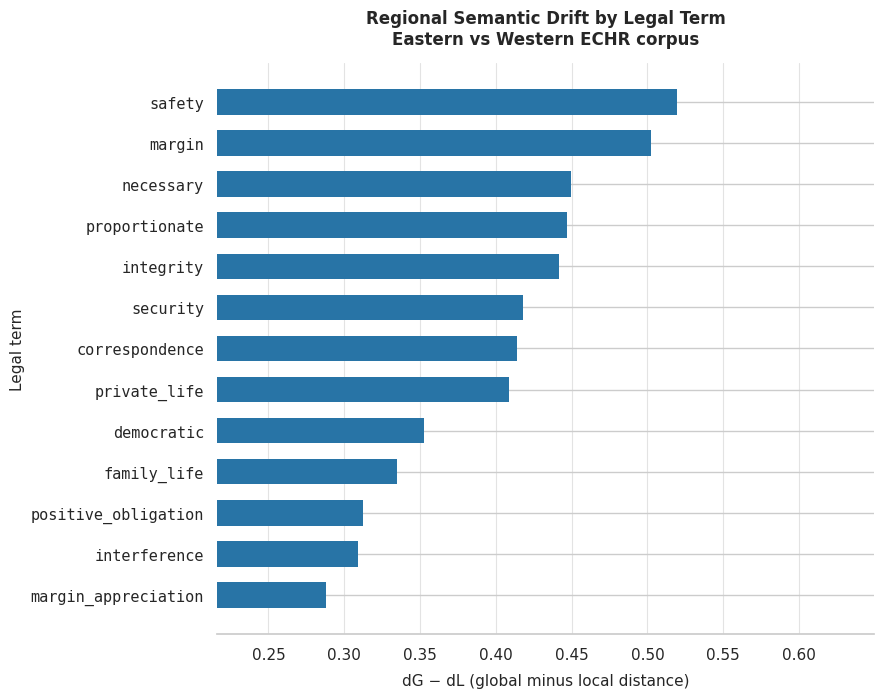

Saved → /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_figure3_regional_drift.png


In [ ]:
# ============================================================
# RQ4 ─ Figure 3 style plot ─ USE YOUR ACTUAL df_drift
# No hardcoded values ─ reads directly from df_drift
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# Note: df_drift is generated in the cell above (7B_m8npZoD83)
# and already contains the data-driven focal terms that are
# present in both Eastern and Western Word2Vec models, as defined
# by the FOCAL_TERMS variable from cell Rx0ZnN9szkNo.

# ── Verify df_drift has required columns ──
assert 'term' in df_drift.columns, "df_drift must have 'term' column"
assert 'dG'   in df_drift.columns, "df_drift must have 'dG' column"
assert 'dL'   in df_drift.columns, "df_drift must have 'dL' column"

# ── Compute and sort ──
plot_df = df_drift.copy()
plot_df["diff"] = plot_df["dG"] - plot_df["dL"]
plot_df = plot_df.sort_values("diff", ascending=False).reset_index(drop=True)

# Print summary
print("Your actual dG − dL values:")
print(plot_df[["term", "dG", "dL", "diff"]].to_string(index=False))

labels = plot_df["term"].tolist()
diffs  = plot_df["diff"].tolist()
colors = ["#2874a6"] * len(diffs) # Using a single color as per request

# ── Plot ──
fig, ax = plt.subplots(figsize=(9, max(4.5, len(labels) * 0.55)))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

y_pos = np.arange(len(labels))
ax.barh(y_pos, diffs, color=colors, height=0.62, edgecolor="none", zorder=3)
ax.axvline(0, color="#666666", linewidth=1.2, linestyle="--", zorder=4)
ax.xaxis.grid(True, color="#e3e3e3", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontfamily="monospace", fontsize=11)
ax.invert_yaxis()

xmin = min(diffs) - abs(min(diffs)) * 0.25
xmax = max(diffs) + abs(max(diffs)) * 0.25
ax.set_xlim(xmin, xmax)

# Removed group labels and legend as per request

ax.set_xlabel("dG − dL (global minus local distance)", fontsize=11, labelpad=8)
ax.set_ylabel("Legal term", fontsize=11)
ax.set_title(
    "Regional Semantic Drift by Legal Term\nEastern vs Western ECHR corpus",
    fontsize=12, fontweight="bold", pad=14
)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#ccc")

plt.tight_layout()
plt.savefig(f"{SAVE_PATH}rq4_figure3_regional_drift.png",
            dpi=180, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved → {SAVE_PATH}rq4_figure3_regional_drift.png")

t-SNE chart

In [ ]:
# ============================================================
# RQ4 ─ CELL 5: Interactive t-SNE per Focal Term
# Hover shows: word, cosine similarity
# HUDOC lookup: https://hudoc.echr.coe.int/eng#{%22docname%22:[%22{doc_id}%22]}
# ============================================================
import numpy as np
import plotly.graph_objects as go
from sklearn.manifold import TSNE

HUDOC_BASE = "https://hudoc.echr.coe.int/eng#{{%22docname%22:[%22{doc_id}%22]}}"

# User-defined parameters for focal and probe terms, and top-N neighbours
# Updated FOCAL_TERMS to use bigram format detected by Gensim's Phrases model
TOP_N = 20 # Retain original TOP_N value

# Define your custom list of focal terms for t-SNE visualization here.
# These terms must be present in the globally defined FOCAL_TERMS list
# (derived from MASTER_CONCEPT_LIST and available in both W2V models).
CUSTOM_FOCAL_TERMS_FOR_TSNE = [
    'margin_appreciation', 'margin','democratic', 'security' , 'necessary' , 'family_life',
    'private_life',
    'safety'
]

# PROBE_TERMS and EXCLUDE_TERMS are defined in earlier cells (aBGBwCU0oFMU)
# and will be used as global variables. Ensure they are available in the kernel.

def build_tsne_plot(focal_term, cluster, model, topn=TOP_N, perplexity=30, n_iter_val=7000):
    # Ensure probe terms are available in the model's vocabulary
    # PROBE_TERMS is globally defined and was earlier set to an empty list, so this will be empty too.
    probe_in_vocab = [p for p in PROBE_TERMS if p in model.wv]

    # Ensure focal_term is in the model's vocabulary
    if focal_term not in model.wv:
        return None

    # Get initial neighbours and filter out excluded terms (EXCLUDE_TERMS is globally defined)
    initial_neighbours = [w for w, _ in model.wv.most_similar(focal_term, topn=topn)]
    neighbours = [w for w in initial_neighbours if w not in EXCLUDE_TERMS]

    all_words = list(dict.fromkeys([focal_term] + neighbours + probe_in_vocab))

    # Vectors
    vectors = np.array([model.wv[w] for w in all_words])

    # t-SNE
    # Ensure perplexity is valid for the number of points
    actual_perplexity = min(perplexity, len(all_words) - 1)
    if actual_perplexity <= 1:
        print(f"Warning: Not enough points for perplexity={perplexity}. Using actual_perplexity=2 for focal_term='{focal_term}'")
        actual_perplexity = 2 # t-SNE requires perplexity > 1

    tsne = TSNE(n_components=2, perplexity=actual_perplexity, random_state=42, n_iter=n_iter_val)
    coords = tsne.fit_transform(vectors)

    # Cosine similarities to focal term
    focal_vec = model.wv[focal_term]
    cos_sims  = {w: float(np.dot(model.wv[w], focal_vec) /
                          (np.linalg.norm(model.wv[w]) * np.linalg.norm(focal_vec)))
                 for w in all_words}

    # Assign roles
    traces = []
    role_config = {
        'focal':     {'words': [focal_term],       'color': '#CC5441', 'size': 18, 'symbol': 'star'},
        'neighbour': {'words': neighbours,          'color': '#4C9BE8', 'size': 10, 'symbol': 'circle'},
        'probe':     {'words': probe_in_vocab,      'color': '#2CA02C', 'size': 12, 'symbol': 'diamond'},
    }

    for role, cfg in role_config.items():
        xs, ys, texts, hovers = [], [], [], []
        for w in cfg['words']:
            if w not in all_words:
                continue
            idx = all_words.index(w)
            xs.append(coords[idx, 0])
            ys.append(coords[idx, 1])
            texts.append(w)

            hovers.append(
                f"<b>{w}</b><br>" +
                f"Role: {role}<br>" +
                f"Cosine sim to '{focal_term}': {cos_sims.get(w, 0.0):.4f}" + "<br>"
            )
        traces.append(go.Scatter(
            x=xs, y=ys,
            mode='markers+text',
            text=texts,
            textposition='top center',
            hovertext=hovers,
            hoverinfo='text',
            name=role.capitalize(),
            marker=dict(color=cfg['color'], size=cfg['size'],
                        symbol=cfg['symbol'],
                        line=dict(width=1, color='white')),
        ))

    fig = go.Figure(traces)
    fig.update_layout(
        title=f"RQ4 ─ '{focal_term}' semantic neighbourhood | {cluster} corpus (p={actual_perplexity}, i={n_iter_val})",
        xaxis=dict(showticklabels=False, title='t-SNE dim 1'),
        yaxis=dict(showticklabels=False, title='t-SNE dim 2'),
        legend=dict(orientation='h', yanchor='bottom', y=1.02),
        width=900, height=650,
        hoverlabel=dict(bgcolor='white', font_size=12),
    )
    return fig

# ── Generate all plots for the CUSTOM list ────────────────────────

# Fixed parameters for display as requested
selected_perplexity = 30
selected_n_iter_val = 7500

print(f"Generating t-SNE plots using perplexity={selected_perplexity} and n_iter={selected_n_iter_val} for each focal term and cluster.")
for focal in CUSTOM_FOCAL_TERMS_FOR_TSNE:
    if focal not in FOCAL_TERMS:
        print(f"⚠️  '{focal}' is not a valid focal term or not present in both models' vocabularies ─ skipping")
        continue

    for cluster in ['Eastern', 'Western']:
        print(f"\n--- Generating t-SNE for '{focal}' in {cluster} with perplexity={selected_perplexity}, n_iter={selected_n_iter_val} ---")
        fig = build_tsne_plot(focal, cluster, models[cluster], topn=TOP_N, perplexity=selected_perplexity, n_iter_val=selected_n_iter_val)
        if fig:
            fig.show()
            fname = f"{SAVE_PATH}rq4_tsne_{focal}_{cluster.lower()}_p{selected_perplexity}_i{selected_n_iter_val}.html"
            fig.write_html(fname)
            print(f"Saved: {fname}")
        else:
            print(f"⚠️  '{focal}' not in {cluster} vocab ─ skipping")

Generating t-SNE plots using perplexity=30 and n_iter=7500 for each focal term and cluster.

--- Generating t-SNE for 'margin_appreciation' in Eastern with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_margin_appreciation_eastern_p30_i7500.html

--- Generating t-SNE for 'margin_appreciation' in Western with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_margin_appreciation_western_p30_i7500.html

--- Generating t-SNE for 'margin' in Eastern with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_margin_eastern_p30_i7500.html

--- Generating t-SNE for 'margin' in Western with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_margin_western_p30_i7500.html

--- Generating t-SNE for 'democratic' in Eastern with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_democratic_eastern_p30_i7500.html

--- Generating t-SNE for 'democratic' in Western with perplexity=30, n_iter=7500 ---


... (7 outputs left out)

Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_private_life_eastern_p30_i7500.html

--- Generating t-SNE for 'private_life' in Western with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_private_life_western_p30_i7500.html

--- Generating t-SNE for 'safety' in Eastern with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_safety_eastern_p30_i7500.html

--- Generating t-SNE for 'safety' in Western with perplexity=30, n_iter=7500 ---


Saved: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_safety_western_p30_i7500.html


In [ ]:
# ============================================================
# RQ4 ─ Sentence Context Lookup for Neighbour Words
# For any focal term: show real sentences from East & West
# where the word and its neighbours appear together
# ============================================================

import re
import pandas as pd

def get_sentences_containing(word, df, text_col='law_text_clean', n=3):
    """
    Find real sentences from the corpus that contain `word`.
    Returns up to n sentences.
    """
    sentences_found = []
    for _, row in df.iterrows():
        text  = row.get(text_col, '')
        sents = re.split(r'(?<=[.!?])\s+', text.lower())
        for s in sents:
            # Check for exact word match, or for phrase match if word contains underscore
            word_to_match = word.replace('_', ' ')
            if (word in s.split() or word_to_match in s) and len(s.split()) >= 8:
                # Clean up whitespace
                s_clean = re.sub(r'\s+', ' ', s).strip()
                sentences_found.append(s_clean[:300])  # cap length
            if len(sentences_found) >= n:
                return sentences_found
    return sentences_found


def show_neighbour_context(focal_term, model_east, model_west,
                           df_east, df_west, results_list, # Added results_list parameter
                           text_col='law_text_clean', k=5, n_sents=2):
    """
    For a focal term:
    1. Print its top-k neighbours in Eastern and Western models
    2. For each neighbour, show n_sents real sentences from each corpus
    3. Appends structured results to results_list
    """
    print("=" * 70)
    print(f"FOCAL TERM: '{focal_term}'")
    print("=" * 70)

    for cluster, model, df in [
        ("EASTERN", model_east, df_east),
        ("WESTERN", model_west, df_west),
    ]:
        if focal_term not in model.wv:
            print(f"\n  [{cluster}] '{focal_term}' not in vocabulary ─ skipped")
            continue

        neighbours = [w for w, _ in model.wv.most_similar(focal_term, topn=k)]

        print(f"\n{'\u2500'*70}")
        print(f"[{cluster}] Top {k} neighbours of '{focal_term}':")
        print(f"  {neighbours}")
        print()

        # Show sentences for all 5 neighbours and store in results_list
        for nb in neighbours[:5]:
            sents = get_sentences_containing(nb, df, text_col, n=n_sents)
            print(f"  ── '{nb}' ─ example sentences:")

            entry = {
                'focal_term': focal_term,
                'cluster': cluster,
                'neighbour': nb,
            }
            for i in range(n_sents):
                entry[f'example_sentence_{i+1}'] = sents[i] if i < len(sents) else ""
            results_list.append(entry)

            if sents:
                for i, s in enumerate(sents, 1):
                    print(f"     {i}. ...{s}...")
            else:
                print(f"     (no example sentences found in corpus)")
            print()


# ── Split df_rq4 into East and West for lookup ──
df_east = df_rq4[df_rq4['cluster'] == 'Eastern'].reset_index(drop=True)
df_west = df_rq4[df_rq4['cluster'] == 'Western'].reset_index(drop=True)

# ── Run for your focal terms ──
# This list is dynamically derived from FOCAL_TERMS to ensure consistency.
# Select a diverse but concise subset for effective context lookup.
INSPECT_TERMS = [
    'margin_of_appreciation', 'private_life', 'family_life', # Key phrases
    'detention', 'violation', # Core legal concepts
    'integrity', 'security', 'safety' # Recently added terms
]

all_neighbour_contexts = [] # Initialize an empty list to store results

for term in INSPECT_TERMS:
    show_neighbour_context(
        focal_term  = term,
        model_east  = model_east,
        model_west  = model_west,
        df_east     = df_east,
        df_west     = df_west,
        results_list= all_neighbour_contexts, # Pass the list to the function
        text_col    = 'law_text_clean',
        k           = 5,
        n_sents     = 2,
    )
    print()

# Convert the collected data to a DataFrame and save to CSV
df_neighbour_contexts = pd.DataFrame(all_neighbour_contexts)
df_neighbour_contexts.to_csv(f"{SAVE_PATH}rq4_neighbour_contexts.csv", index=False)
print(f"\nFull list of neighbour contexts saved to {SAVE_PATH}rq4_neighbour_contexts.csv")


FOCAL TERM: 'margin_of_appreciation'

  [EASTERN] 'margin_of_appreciation' not in vocabulary ─ skipped

  [WESTERN] 'margin_of_appreciation' not in vocabulary ─ skipped

FOCAL TERM: 'private_life'

──────────────────────────────────────────────────────────────────────
[EASTERN] Top 5 neighbours of 'private_life':
  ['intimate_aspect', 'includes_person', 'austria_november', 'world_embrace', 'context_concept']

  ── 'intimate_aspect' ─ example sentences:
     1. ...the law i as to the locus standi of mrs solomakhina the applicant died on september while the case was pending before the court it has not been disputed that mrs slomakhina his mother is entitled to pursue the application on his behalf and the court sees no reason to hold otherwise see among other a...
     2. ...the law i the applicants standing the applicant submitted the application in his own name complaining not only of the alleged violation of his right but also of the alleged violation of the right of his daughter the c

##Trained on both Cluster

Training shared Word2Vec model on combined corpus...
Shared vocab size: 22,780
Total points for t-SNE: 21574 (10787 words × 2 regions)


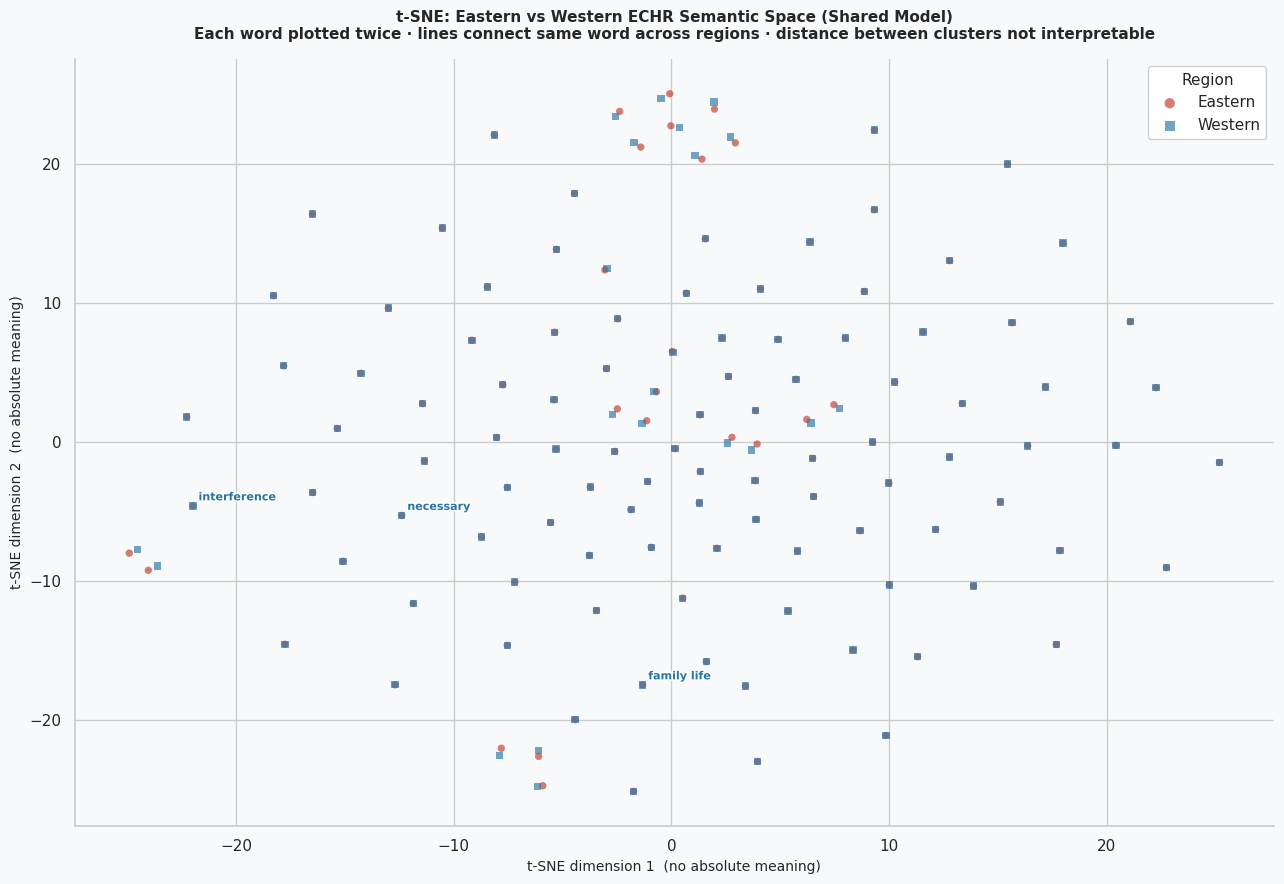

Saved → /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/rq4_tsne_east_west_combined.png


In [ ]:
# ============================================================
# RQ4 — Combined Eastern + Western t-SNE
# Single shared embedding space, coloured by region
# ============================================================

from gensim.models import Word2Vec
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np
import pandas as pd

# ── Step 1: Train ONE shared model on both corpora ──────────
# Tag each sentence with its region so we can track it later
east_tagged = [(s, 'Eastern') for s in east_sents_phrased]
west_tagged = [(s, 'Western') for s in west_sents_phrased]
all_tagged  = east_tagged + west_tagged

# Train on all sentences combined (no region tag — W2V doesn't need it)
all_sents = [s for s, _ in all_tagged]

print("Training shared Word2Vec model on combined corpus...")
model_shared = Word2Vec(
    sentences   = all_sents,
    vector_size = 100,    # smaller = faster, still good for viz
    window      = 10,
    min_count   = 5,
    workers     = 4,
    epochs      = 15,
    sg          = 1,
    seed        = 42,
)
print(f"Shared vocab size: {len(model_shared.wv):,}")

# ── Step 2: Get per-region average vectors ──────────────────
# For each word in shared vocab, compute mean vector in East and West
# by averaging over sentences where the word appears

from collections import defaultdict

east_word_vecs = defaultdict(list)
west_word_vecs = defaultdict(list)

for sent, region in all_tagged:
    for token in sent:
        if token in model_shared.wv:
            vec = model_shared.wv[token]
            if region == 'Eastern':
                east_word_vecs[token].append(vec)
            else:
                west_word_vecs[token].append(vec)

# Find words that appear in BOTH regions
shared_words = set(east_word_vecs.keys()) & set(west_word_vecs.keys())

# Build rows: one per (word, region) pair
rows = []
for word in shared_words:
    e_vec = np.mean(east_word_vecs[word], axis=0)
    w_vec = np.mean(west_word_vecs[word], axis=0)
    rows.append({'word': word, 'region': 'Eastern', 'vec': e_vec})
    rows.append({'word': word, 'region': 'Western', 'vec': w_vec})

df_plot = pd.DataFrame(rows)
print(f"Total points for t-SNE: {len(df_plot)} ({len(shared_words)} words × 2 regions)")

# ── Step 3: t-SNE on all vectors ────────────────────────────
# Limit to top N most frequent shared words to keep plot readable
TOP_N = 120   # adjust up/down as needed

# Rank by frequency in shared model
freq_rank = {w: model_shared.wv.get_vecattr(w, 'count')
             for w in shared_words
             if w in model_shared.wv}
top_words = sorted(freq_rank, key=freq_rank.get, reverse=True)[:TOP_N]

df_top = df_plot[df_plot['word'].isin(top_words)].copy().reset_index(drop=True)

X = np.stack(df_top['vec'].values)

tsne = TSNE(
    n_components = 2,
    perplexity   = 30,
    n_iter       = 1000,
    random_state = 42,
    init         = 'pca',
)
coords = tsne.fit_transform(X)
df_top['x'] = coords[:, 0]
df_top['y'] = coords[:, 1]

# ── Step 4: Plot ─────────────────────────────────────────────
FOCAL_TERMS_HIGHLIGHT = [
    "margin_of_appreciation", "interference", "family_life",
    "private_life", "necessary", "democratic",
    "correspondence", "proportionate", "security",
    "positive_obligation",
]

fig, ax = plt.subplots(figsize=(13, 9))
fig.patch.set_facecolor('#f8f9fa')
ax.set_facecolor('#f8f9fa')

colors  = {'Eastern': '#c0392b', 'Western': '#2874a6'}
markers = {'Eastern': 'o',       'Western': 's'}
alphas  = {'Eastern': 0.65,      'Western': 0.65}

for region in ['Eastern', 'Western']:
    sub = df_top[df_top['region'] == region]
    ax.scatter(
        sub['x'], sub['y'],
        c      = colors[region],
        marker = markers[region],
        alpha  = alphas[region],
        s      = 28,
        label  = region,
        edgecolors = 'none',
        zorder = 3,
    )

# Draw lines connecting same word across East and West
for word in top_words:
    e_row = df_top[(df_top['word'] == word) & (df_top['region'] == 'Eastern')]
    w_row = df_top[(df_top['word'] == word) & (df_top['region'] == 'Western')]
    if e_row.empty or w_row.empty:
        continue
    ax.plot(
        [e_row['x'].values[0], w_row['x'].values[0]],
        [e_row['y'].values[0], w_row['y'].values[0]],
        color='#aaaaaa', linewidth=0.4, alpha=0.35, zorder=1,
    )

# Label focal terms only
for _, row in df_top[df_top['word'].isin(FOCAL_TERMS_HIGHLIGHT)].iterrows():
    ax.annotate(
        row['word'].replace('_', ' '),
        xy       = (row['x'], row['y']),
        fontsize = 8,
        color    = colors[row['region']],
        fontweight = 'bold',
        xytext   = (4, 4),
        textcoords = 'offset points',
        path_effects = [
            pe.withStroke(linewidth=2, foreground='white')
        ],
        zorder = 5,
    )

ax.legend(
    title      = 'Region',
    fontsize   = 11,
    title_fontsize = 11,
    framealpha = 0.9,
    edgecolor  = '#cccccc',
    markerscale = 1.4,
)

ax.set_title(
    "t-SNE: Eastern vs Western ECHR Semantic Space (Shared Model)\n"
    "Each word plotted twice · lines connect same word across regions · "
    "distance between clusters not interpretable",
    fontsize   = 11,
    fontweight = 'bold',
    pad        = 14,
)
ax.set_xlabel("t-SNE dimension 1  (no absolute meaning)", fontsize=10)
ax.set_ylabel("t-SNE dimension 2  (no absolute meaning)", fontsize=10)

for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
ax.spines['left'].set_color('#ccc')
ax.spines['bottom'].set_color('#ccc')

plt.tight_layout()
plt.savefig(f"{SAVE_PATH}rq4_tsne_east_west_combined.png",
            dpi=180, bbox_inches='tight', facecolor='#f8f9fa')
plt.show()
print(f"Saved → {SAVE_PATH}rq4_tsne_east_west_combined.png")

Create TSV Files for TensorFlow

In [ ]:
# ============================================================
# RQ4 — Word2Vec Semantic Drift Analysis
#
# ============================================================
# Generate TSV files for TensorFlow Projector
# ============================================================

import os
import numpy as np # Import numpy for L2 normalization

# Check if models have been trained
if 'models' in locals() and models:
    for cluster_name, w2v_model in models.items():
        print(f"\nGenerating TSV files for {cluster_name} model...")

        # Prepare vectors.tsv
        vectors_path = os.path.join(SAVE_PATH, f'vectors_{cluster_name}.tsv')
        with open(vectors_path, 'w') as f_vectors:
            for word in w2v_model.wv.index_to_key:
                vector = w2v_model.wv[word]
                # L2-normalize the vector
                norm = np.linalg.norm(vector)
                if norm > 0:
                    normalized_vector = vector / norm
                else:
                    normalized_vector = vector # Handle zero vector case (unlikely but safe)
                vector_str = '\t'.join(map(str, normalized_vector))
                f_vectors.write(vector_str + '\n')

        print(f"Vectors saved to: {vectors_path}")

        # Prepare metadata.tsv
        metadata_path = os.path.join(SAVE_PATH, f'metadata_{cluster_name}.tsv')
        with open(metadata_path, 'w') as f_metadata:
            # Removed the header line: f_metadata.write('Word\n')
            for word in w2v_model.wv.index_to_key:
                f_metadata.write(word + '\n')

        print(f"Metadata (words) saved to: {metadata_path}")

    print("\n--- Instructions for TensorFlow Projector ---")
    print("1. Go to: https://projector.tensorflow.org/")
    print("2. Click 'Load' on the left panel.")
    print("3. Upload the 'vectors_Eastern.tsv' and 'metadata_Eastern.tsv' files.")
    print("4. You can then click 'Add data' again and upload 'vectors_Western.tsv' and 'metadata_Western.tsv' to compare them.")
    print("You should then see the Word2Vec embeddings visualized!")
else:
    print("Word2Vec models not found. Please ensure the Word2Vec training cells (e.g., 'WKRzKpFutnWv') have been run before attempting to generate the TSV files.")


Generating TSV files for Eastern model...
Vectors saved to: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/vectors_Eastern.tsv
Metadata (words) saved to: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/metadata_Eastern.tsv

Generating TSV files for Western model...
Vectors saved to: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/vectors_Western.tsv
Metadata (words) saved to: /content/drive/MyDrive/LL 5532X Group Project: Data Investigation/3 Modeling/Mount V3/metadata_Western.tsv

--- Instructions for TensorFlow Projector ---
1. Go to: https://projector.tensorflow.org/
2. Click 'Load' on the left panel.
3. Upload the 'vectors_Eastern.tsv' and 'metadata_Eastern.tsv' files.
4. You can then click 'Add data' again and upload 'vectors_Western.tsv' and 'metadata_Western.tsv' to compare them.
You should then see the Word2Vec embeddings visualized!
